# Did post-training cause Qwen3's algorithm collapse? (runnable demo)

**Question.** Ask Qwen3-8B (instruct, thinking off) 200 times at T = 1 to *"write `solve(n, edges, s, t)` for the weighted shortest path"* and it writes Dijkstra 193 times. Was this **algorithm-choice collapse** installed by post-training, or does Qwen3-8B-**Base** already behave the same way?

**Design of the experiment.** A 2 × 2 *weights × format* decomposition on two path-search tasks (T1 unweighted grid path, T2 weighted directed shortest path):
`base_tf` (base model, template-free docstring prompt) · `base_chat` (base model on the instruct chat template, identical tokens) · `instruct_tf` · `instruct_chat`, plus a modal-ban arm (*"Do not use Dijkstra."*). Every generated program is run on 46 hidden tests and labelled by **what it actually does**: a runtime-signature labeller (instrumented heaps and queues, edge-list passes, line-count scaling) plus an AST labeller, with a blind LLM judge breaking disagreements. Diversity is the **Hill number** `Hill_cc = exp(entropy)` of the algorithm labels among *correct* programs; 1 means a single algorithm.

**Full-run result (T2).** `instruct_chat` Hill_cc 1.16 vs `base_chat` 2.09, so D_weights = −0.93 [−1.38, −0.46] and the pre-registered verdict is **INSTALLED_BY_POST_TRAINING** (T1: MIXED). Post-training concentrated the base model's existing mode (Dijkstra) rather than inventing it. Subtracting the instruct-minus-base residual difference (the "sharpening direction") did not restore diversity. A ban prompt did (Hill_cc 1.16 → 1.99), and the model landed on Bellman-Ford, as the base model had forecast.

**What this notebook runs (CPU only, 1–2 minutes plus package installs).** The CPU half of `method.py`'s pipeline, with the artifact's own code, on **100 curated T2 samples** (20 per arm) from `mini_demo_data.json`:
prompts → hidden tests → program extraction → sandboxed scoring → runtime and AST labelling → final label (judge answers from its cache) → Hill numbers, paraphrase-cluster bootstrap, permutation tests, pre-registered verdict → hash-committed forecast check → `method_out.json`. It then plots the **actual residual-stream geometry** at the read position (base vs instruct) behind the steering experiment.

**Not re-run here** (needs GPUs or API keys): vLLM generation of the 4,140 programs with Qwen3-8B-Base and Qwen3-8B, HF activation capture and steering, and fresh LLM-judge calls. Their outputs are this notebook's inputs.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (every artifact module logs with loguru)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib, openai — pre-installed on Colab, install locally only
# (openai: the blind judge builds its API client even when every answer comes from its cache)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'openai==2.17.0')

In [2]:
from __future__ import annotations  # as at the top of every artifact module

# --- method.py ---
import argparse
import json
import os
import platform
import subprocess
import sys
from pathlib import Path

from loguru import logger

# --- src/ modules used below (common, prompts, extract, labeller_ast, judge, label_score, stats_utils, analysis, acts_hf) ---
import ast
import asyncio
import gc
import hashlib
import importlib
import math
import random
import re
import time
import warnings
from typing import Any, Iterable

import numpy as np

# --- notebook only: decoding the stored activations, the labelling worker thread, plots ---
import base64
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
from IPython.display import Image, display

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-1/experiment-5/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
examples_all = data["datasets"][0]["examples"]
support = data["metadata"]["demo_support"]  # tests, prompts, judge cache, forecast, activations, full-run reference numbers
print(data["datasets"][0]["dataset"], "|", len(examples_all), "examples |", "models:", data["metadata"]["models"])
print("support:", ", ".join(support))

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
T2_weighted_shortest_path | 100 examples | models: {'base': 'Qwen/Qwen3-8B-Base', 'instruct': 'Qwen/Qwen3-8B'}
support: selection, hidden_tests, prompts, raw_extra, judge_cache_rows, forecast_file_text, hash_log_text, git_commit_text, time_log, activations_R, full_run_reference


## Configuration

Every knob of the demo is in this cell. `EXAMPLES_PER_ARM` takes the first *k* of the 20 curated samples of each arm (100 samples in total). `N_WORKERS` is the number of sandboxed program subprocesses run at once. Colab has 2 vCPUs, and the hidden tests have a 1 s per-case limit, so oversubscribing the CPU can turn slow-but-correct programs into timeouts. `B_BOOT` and `N_PERM` are the bootstrap and permutation sizes used by `src/analysis.py`. Each line notes the value the artifact used. All values below are the artifact's own except `N_WORKERS`; with them the whole notebook ran in under a minute on 4 CPU cores. Lower `EXAMPLES_PER_ARM`, `B_BOOT` and `N_PERM` for a quicker look.

In [5]:
# ---- demo scale (values used by the artifact in the comments) ----
EXAMPLES_PER_ARM = 20  # samples per arm from mini_demo_data.json (max 20; the full run had 100-300 per arm per task)
TASKS_DEMO = ("t2",)   # the demo data holds T2 only (full run: ("t1", "t2"))
N_WORKERS = 2          # parallel sandboxed subprocesses for the harness / runtime labeller (original: 5, on 6 vCPUs)
MAX_CASES = 0          # hidden test cases per program, 0 = all 46 (original: 0)
B_BOOT = 2000          # paraphrase-cluster bootstrap resamples (original: 2000)
N_PERM = 10000         # permutation-test shuffles (original: 10000)

## 1 · Shared constants and helpers (`src/common.py`)

This module holds the model ids and the algorithm **catalogue** per task. For T2 that is `dijkstra, bellman_ford_spfa, bidir_dijkstra, floyd_warshall, dial`, and anything else counts as `other`. It also defines the banned mode and its survivors for the ban arms, the decoding used for every arm (T = 1.0, top-p 1.0, no top-k, thinking off, ≤ 1024 new tokens), and small helpers (Wilson CI, JSONL I/O, sha256).

**One change:** `WS`, the artifact folder, becomes a local working folder `demo_ws/`. The pipeline writes its usual `data/`, `runs/`, `results/`, `predictions/`, `figures/` and `logs/` there.

In [6]:
"""Shared constants, paths and small helpers for the collapse screen (alternate 4: post-training)."""
import hashlib
import json
import math
import os
import sys
import time
from pathlib import Path
from typing import Any, Iterable

from loguru import logger

WS = Path.cwd() / "demo_ws"  # notebook: local working folder instead of the artifact folder (was Path(__file__).resolve().parent.parent)
SRC = WS / "src"
DATA = WS / "data"
TESTS = DATA / "tests"
REFS = DATA / "refs"
RUNS = WS / "runs"
PRED = WS / "predictions"
ACTS = WS / "activations"
RESULTS = WS / "results"
FIGS = WS / "figures"
LOGS = WS / "logs"
for _d in (DATA, TESTS, REFS, RUNS, PRED, ACTS, RESULTS, FIGS, LOGS):
    _d.mkdir(parents=True, exist_ok=True)
SRC.mkdir(parents=True, exist_ok=True)  # notebook: the modules that run as subprocesses are written here (%%writefile)

MB = "Qwen/Qwen3-8B-Base"
MI = "Qwen/Qwen3-8B"
N_LAYERS = 36
D_MODEL = 4096
EOS_IDS = [151645, 151643]  # <|im_end|>, <|endoftext|>
IM_START_ID = 151644
TASKS = ("t1", "t2")
TASK_NAMES = {"t1": "T1_unweighted_grid_path", "t2": "T2_weighted_shortest_path"}

T1_LABELS = ["bfs", "dfs", "bidir_bfs", "iddfs", "astar_greedy", "dijkstra_unit"]
T2_LABELS = ["dijkstra", "bellman_ford_spfa", "bidir_dijkstra", "floyd_warshall", "dial"]
CATALOGUE = {"t1": T1_LABELS, "t2": T2_LABELS}
BANNED = {"t1": "bfs", "t2": "dijkstra"}
BAN_COND = {"t1": "ban:BFS", "t2": "ban:Dijkstra"}
SURVIVORS = {"t1": ["dfs", "bidir_bfs", "iddfs", "astar_greedy", "dijkstra_unit"],
             "t2": ["bellman_ford_spfa", "bidir_dijkstra", "floyd_warshall", "dial"]}

DECODING = {"temperature": 1.0, "top_p": 1.0, "top_k": "disabled", "min_p": 0.0,
            "repetition_penalty": 1.0, "max_tokens": 1024, "thinking": "off"}


def setup_logging(name: str, level: str = "INFO") -> None:
    logger.remove()
    logger.add(sys.stdout, level=level, format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOGS / f"{name}.log"), rotation="30 MB", level="DEBUG")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def stable_seed(*parts: Any, mod: int = 2**31 - 1) -> int:
    """Deterministic seed from arbitrary parts (Python's hash() is salted per process)."""
    s = "|".join(str(p) for p in parts)
    return int(hashlib.sha256(s.encode()).hexdigest()[:15], 16) % mod


def read_jsonl(p: Path) -> list[dict]:
    if not p.exists():
        return []
    out = []
    with open(p) as f:
        for line in f:
            line = line.strip()
            if line:
                out.append(json.loads(line))
    return out


def write_jsonl(p: Path, rows: Iterable[dict]) -> None:
    tmp = p.with_suffix(p.suffix + ".tmp")
    with open(tmp, "w") as f:
        for r in rows:
            f.write(json.dumps(r) + "\n")
    tmp.replace(p)


def append_jsonl(p: Path, rows: Iterable[dict]) -> None:
    with open(p, "a") as f:
        for r in rows:
            f.write(json.dumps(r) + "\n")


def utc_now() -> str:
    return time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime())


def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float, float]:
    if n == 0:
        return (float("nan"), float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (p, max(0.0, c - h), min(1.0, c + h))


def time_log(event: str, **kw: Any) -> None:
    """Append a phase-boundary event to time_log.json (list of dicts)."""
    p = WS / "time_log.json"
    try:
        cur = json.loads(p.read_text()) if p.exists() else []
    except json.JSONDecodeError:
        cur = []
    cur.append({"utc": utc_now(), "event": event, **kw})
    p.write_text(json.dumps(cur, indent=1))


def add_deviation(what: str, why: str) -> None:
    p = RESULTS / "deviations.json"
    try:
        cur = json.loads(p.read_text()) if p.exists() else []
    except json.JSONDecodeError:
        cur = []
    if any(d["what"] == what for d in cur):
        return
    cur.append({"what": what, "why": why, "when": utc_now()})
    p.write_text(json.dumps(cur, indent=1))


def set_ram_limit(gb: float) -> None:
    import resource
    b = int(gb * 1024**3)
    resource.setrlimit(resource.RLIMIT_AS, (b, b))


def env_flag(name: str, default: str = "") -> str:
    return os.environ.get(name, default)

## 2 · The pipeline (`method.py`)

`method.py` is the artifact's single entry point. `--all` runs the steps below in `ORDER`, each in its own subprocess (vLLM and HF never share the GPU), and `--assemble` rebuilds `method_out.json`. The GPU steps took about 2.1 GPU-hours on one NVIDIA L4. This notebook re-runs every CPU step on the demo data and loads the outputs of the GPU steps:

| step(s) | module | needs | in this notebook |
|---|---|---|---|
| `prompts` | `src/prompts.py` | 2 HF tokenizers | frozen texts loaded, templates re-checked (§3) |
| `tests`, `calibrate` | `src/tasks.py`, `src/calibrate.py` | CPU | tests regenerated and compared, calibrated limits loaded (§4) |
| `gate` | `src/labeller_gate.py` | CPU | not re-run (full run: AST labeller 25/25 on references and mutants, runtime labeller never wrong) |
| `genA`, `genB`, `genC`, `genAEXT` | `src/gen_vllm.py` | GPU, Qwen3-8B-Base and Qwen3-8B | the generated samples are the demo data (§5) |
| `label` | `src/label_score.py` (+ extract, harness, labellers, judge) | CPU + judge API | **re-run** (§6–§10), judge answers from its cache |
| `acts` | `src/acts_hf.py` | GPU | stored read-position states used (§14) |
| `predict` | `src/predict_commit.py` | CPU | committed forecast re-hashed and scored (§12–§13) |
| `steerS`, `steerR`, `steerX`, `steerXNC` | `src/steer_hf.py` | GPU | not re-run; full-run numbers in the results |
| `analysis` | `src/analysis.py`, `src/stats_utils.py` | CPU | **re-run** (§11–§13) |
| `report` | `src/report.py` | CPU | not re-run (renders markdown tables) |
| `--assemble` | `method.py` | CPU | **re-run** (§15) |

The next cell is the top of `method.py`, unchanged except that `WS` and the `common` names come from §1. The cell after it prints the step order and probes this runtime, the way the artifact recorded its own.

In [7]:
#!/usr/bin/env python3
"""Did instruction tuning cause the algorithm-choice collapse? (alternate 4 screen, Qwen3-8B-Base vs Qwen3-8B)

Single entry point. Every GPU phase runs as its own subprocess (vLLM and HF are never resident together).

  .venv/bin/python method.py --all          # full pipeline (resumable: finished requests / rows are skipped)
  .venv/bin/python method.py --assemble     # rebuild runs/samples.jsonl + method_out.json from results on disk
  .venv/bin/python method.py --step <name>  # one step: prompts|tests|calibrate|gate|genA|genB|label|acts|predict|genC|
                                            #           steerS|steerR|steerX|genAEXT|analysis
Outputs: method_out.json (exp_gen_sol_out schema: metadata = all analyses, datasets = per-sample rows per task).
"""
import argparse
import json
import os
import platform
import subprocess
import sys
from pathlib import Path

from loguru import logger

# notebook: WS is defined in §1 (the script used WS = Path(__file__).resolve().parent)
sys.path.insert(0, str(WS / "src"))
# notebook: these names are defined in §1 (src/common.py)
# from common import (CATALOGUE, DECODING, MB, MI, PRED, RESULTS, RUNS, TASK_NAMES, read_jsonl, setup_logging,  # noqa: E402
#                     sha256_file, write_jsonl)

PY = str(WS / ".venv" / "bin" / "python")
STEPS = {
    "prompts": [PY, "src/prompts.py"],
    "tests": [PY, "src/tasks.py"],
    "calibrate": [PY, "src/calibrate.py"],
    "gate": [PY, "src/labeller_gate.py"],
    "genA": [PY, "src/gen_vllm.py", "--phase", "A"],
    "genB": [PY, "src/gen_vllm.py", "--phase", "B"],
    "label": [PY, "src/label_score.py"],
    "acts": None,  # two processes, see run_step
    "predict": [PY, "src/predict_commit.py"],
    "genC": [PY, "src/gen_vllm.py", "--phase", "C"],
    "steerS": [PY, "src/steer_hf.py", "--stage", "S"],
    "steerR": [PY, "src/steer_hf.py", "--stage", "R", "--cstar", "t1=0.5,t2=0.5"],
    "steerX": [PY, "src/steer_hf.py", "--stage", "X", "--extra",
               "sharpenR:1.0:None:10;randomR:1.0:1:10;single18:0.25:None:5;single18:0.5:None:5;single18:1.0:None:5"],
    "genAEXT": [PY, "src/gen_vllm.py", "--phase", "A_EXT"],
    "steerXNC": [PY, "src/steer_hf.py", "--stage", "X", "--nocutoff", "--extra", "sharpenR:1.0:None:2"],
    "analysis": [PY, "src/analysis.py", "--second_judge"],
    "report": [PY, "src/report.py"],
}
ORDER = ["prompts", "tests", "calibrate", "gate", "genA", "genB", "label", "acts", "predict", "genC", "steerS", "label",
         "steerR", "steerX", "genAEXT", "steerXNC", "label", "analysis", "report"]


def run_step(name: str) -> None:
    logger.info(f"=== step {name}")
    if name == "acts":
        for m in ("base", "instruct"):
            subprocess.run([PY, "src/acts_hf.py", "--model", m], cwd=WS, check=True)
        return
    subprocess.run(STEPS[name], cwd=WS, check=True)


def lib_versions() -> dict:
    out = {"python": platform.python_version()}
    for mod in ("torch", "vllm", "transformers", "numpy", "scipy", "openai"):
        try:
            out[mod] = __import__(mod).__version__
        except Exception as e:  # noqa: BLE001 - version probe only
            out[mod] = f"unavailable ({type(e).__name__})"
    return out


def hardware() -> dict:
    hw = {"gpu": None, "cpu_quota": None, "ram_limit_gb": None}
    try:
        hw["gpu"] = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader"],
                                   capture_output=True, text=True, timeout=20).stdout.strip()
    except (OSError, subprocess.SubprocessError):
        pass
    try:
        q = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read_text())
        p = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read_text())
        hw["cpu_quota"] = q / p if q > 0 else None
        hw["ram_limit_gb"] = int(Path("/sys/fs/cgroup/memory/memory.limit_in_bytes").read_text()) / 1e9
    except (OSError, ValueError):
        pass
    return hw

In [8]:
setup_logging("method")  # as method.py's main() does
GPU = {"genA", "genB", "genC", "genAEXT", "acts", "steerS", "steerR", "steerX", "steerXNC"}
for i, s in enumerate(ORDER):
    cmd = " ".join(STEPS[s][1:]) if STEPS[s] else "src/acts_hf.py --model base ; src/acts_hf.py --model instruct"
    print(f"{i:2d}. {s:9s} {'GPU' if s in GPU else 'CPU'}  {cmd}")
logger.info(f"library versions in this runtime: {lib_versions()}")
logger.info(f"hardware of this runtime: {hardware()}")

 0. prompts   CPU  src/prompts.py
 1. tests     CPU  src/tasks.py
 2. calibrate CPU  src/calibrate.py
 3. gate      CPU  src/labeller_gate.py
 4. genA      GPU  src/gen_vllm.py --phase A
 5. genB      GPU  src/gen_vllm.py --phase B
 6. label     CPU  src/label_score.py
 7. acts      GPU  src/acts_hf.py --model base ; src/acts_hf.py --model instruct
 8. predict   CPU  src/predict_commit.py
 9. genC      GPU  src/gen_vllm.py --phase C
10. steerS    GPU  src/steer_hf.py --stage S
11. label     CPU  src/label_score.py
12. steerR    GPU  src/steer_hf.py --stage R --cstar t1=0.5,t2=0.5
13. steerX    GPU  src/steer_hf.py --stage X --extra sharpenR:1.0:None:10;randomR:1.0:1:10;single18:0.25:None:5;single18:0.5:None:5;single18:1.0:None:5
14. genAEXT   GPU  src/gen_vllm.py --phase A_EXT
15. steerXNC  GPU  src/steer_hf.py --stage X --nocutoff --extra sharpenR:1.0:None:2
16. label     CPU  src/label_score.py
17. analysis  CPU  src/analysis.py --second_judge
18. report    CPU  src/report.py


05:45:38|INFO   |library versions in this runtime: {'python': '3.12.14', 'torch': 'unavailable (ModuleNotFoundError)', 'vllm': 'unavailable (ModuleNotFoundError)', 'transformers': 'unavailable (ModuleNotFoundError)', 'numpy': '2.0.2', 'scipy': '1.16.3', 'openai': '2.17.0'}


05:45:38|INFO   |hardware of this runtime: {'gpu': None, 'cpu_quota': None, 'ram_limit_gb': None}


## 3 · Prompts (`src/prompts.py`)

One task spec per task, wrapped three ways:

* **chat**: the instruct chat template with thinking disabled. Both models receive the *same token ids*, which the full run asserted for all 120 chat prompts.
* **template-free**: a docstring plus the function signature, so the model continues the code.
* **ban**: the chat prompt with a ban lead-in, e.g. *"Do not use Dijkstra."*

Ten neutral lead-ins, P0–P9, are the sampling paraphrases and the clusters of the bootstrap. `build()` needs the two Hugging Face tokenizers, so the demo writes the frozen T2 prompts from the data file to `demo_ws/data/prompts.json` (the artifact's file minus the token ids). It then checks that the original template helpers rebuild every text exactly.

In [9]:
"""Frozen prompt set (STEP 2): task specs, neutral lead-ins P0..P49, ban lead-ins B0..B9,
chat prompts (instruct chat template, thinking off) and template-free docstring prompts.

Run:  .venv/bin/python src/prompts.py   -> data/prompts.json (+ token-identity checks)
"""
import json
import re
import sys

from loguru import logger

# notebook: DATA, MB, MI, setup_logging and sha256_text are defined in §1
# sys.path.insert(0, str(__import__("pathlib").Path(__file__).resolve().parent))
# from common import DATA, MB, MI, setup_logging, sha256_text  # noqa: E402

SPEC = {
    "t1": ("Task: write a Python function solve(grid, start, goal). grid is a list of equal-length strings in which . "
           "is a free cell and # is a wall. start and goal are (row, col) tuples of free cells. A move goes up, down, "
           "left or right to a free cell inside the grid. Return a list of (row, col) tuples forming a valid path from "
           "start to goal, including both ends; any valid path is accepted. If goal cannot be reached, return an empty "
           "list. The grid has at most 30 rows and 30 columns. Use only the Python standard library."),
    "t2": ("Task: write a Python function solve(n, edges, s, t). The graph is directed with nodes 0..n-1 (n <= 100). "
           "edges is a list of (u, v, w) tuples, each an edge from u to v with integer weight 0 <= w <= 100; there may "
           "be cycles, self-loops and parallel edges. Return the length of the shortest path from s to t as an int, or "
           "-1 if t is unreachable from s. If s == t return 0. Use only the Python standard library."),
}
FORMAT = " Return only one ```python code block containing the complete function and any imports or helpers it needs."
SIG = {
    "t1": "def solve(grid: list[str], start: tuple[int, int], goal: tuple[int, int]) -> list[tuple[int, int]]:",
    "t2": "def solve(n: int, edges: list[tuple[int, int, int]], s: int, t: int) -> int:",
}

# P0..P9 are the sampling paraphrases (verbatim from the plan); P10..P49 complete the 50 for the direction.
P_FIRST10 = [
    "Solve the following programming task.",
    "Please complete the coding task below.",
    "Here is a programming problem for you.",
    "Write a solution to the task described below.",
    "Complete the following Python exercise.",
    "Your job is to implement the function described below.",
    "The task below needs a working implementation.",
    "Please write code for the following problem.",
    "Read the task and implement it.",
    "Below is a small coding assignment.",
]
_OPENERS = [
    "Solve the following {o}.",
    "Please complete the {o} below.",
    "Here is a {o} for you.",
    "Write a solution to the {o} described below.",
    "Complete the following {o}.",
    "Your job is to finish the {o} described below.",
    "The {o} below needs a working implementation.",
    "Please write code for the following {o}.",
    "Read the {o} and implement it.",
    "Below is a {o}.",
]
_OBJECTS = ["programming task", "coding task", "Python exercise", "coding assignment", "programming problem",
            "Python task", "coding problem", "small programming exercise"]

BAN = {
    "t1": [
        "Do not use BFS.",
        "Do not use breadth-first search.",
        "You must not use BFS (breadth-first search).",
        "Avoid breadth-first search entirely.",
        "Your solution must not be a BFS.",
        "Do not implement breadth-first search (BFS).",
        "BFS is not allowed.",
        "Do not solve this with breadth-first search.",
        "Using BFS is forbidden.",
        "Do not use a breadth-first search (BFS) approach.",
    ],
    "t2": [
        "Do not use Dijkstra.",
        "Do not use Dijkstra's algorithm.",
        "You must not use Dijkstra (Dijkstra's algorithm).",
        "Avoid Dijkstra's algorithm entirely.",
        "Your solution must not be a Dijkstra.",
        "Do not implement Dijkstra's algorithm (Dijkstra).",
        "Dijkstra is not allowed.",
        "Do not solve this with Dijkstra's algorithm.",
        "Using Dijkstra is forbidden.",
        "Do not use a Dijkstra's algorithm (Dijkstra) approach.",
    ],
}
LEXICON = ["search", "queue", "stack", "heap", "graph", "bfs", "dfs", "dijkstra", "fast", "efficient", "optimal",
           "shortest", "creative", "novel"]


def neutral_segments() -> list[str]:
    segs = list(P_FIRST10)
    for o in _OBJECTS:
        for op in _OPENERS:
            s = op.format(o=o)
            if s not in segs:
                segs.append(s)
            if len(segs) == 50:
                return segs
    raise RuntimeError("not enough neutral segments")


def lexicon_ok(seg: str) -> bool:
    low = seg.lower()
    return not any(re.search(re.escape(w), low) for w in LEXICON)


def user_content(seg: str, task: str) -> str:
    return seg + "\n\n" + SPEC[task] + FORMAT


def tf_prompt(seg: str, task: str) -> str:
    return '"""\n' + seg + "\n\n" + SPEC[task] + '\n"""\n\n' + SIG[task] + "\n"


def build() -> dict:
    from transformers import AutoTokenizer

    tok_i = AutoTokenizer.from_pretrained(MI)
    tok_b = AutoTokenizer.from_pretrained(MB)
    P = neutral_segments()
    assert len(P) == 50 and len(set(P)) == 50
    bad = [s for s in P if not lexicon_ok(s)]
    assert not bad, f"lexicon violation: {bad}"
    out: dict = {"spec": SPEC, "format_sentence": FORMAT, "sig": SIG, "neutral": P, "ban": BAN,
                 "lexicon": LEXICON, "chat": {}, "tf": {}, "checks": {}}
    n_identical = 0
    tails = set()
    for task in ("t1", "t2"):
        out["chat"][task] = {"baseline": [], "ban": []}
        out["tf"][task] = {"baseline": [], "ban": []}
        for kind, segs in (("baseline", P), ("ban", BAN[task])):
            for i, seg in enumerate(segs):
                msgs = [{"role": "user", "content": user_content(seg, task)}]
                s = tok_i.apply_chat_template(msgs, add_generation_prompt=True, enable_thinking=False, tokenize=False)
                ids_i = tok_i(s, add_special_tokens=False)["input_ids"]
                ids_b = tok_b(s, add_special_tokens=False)["input_ids"]
                assert ids_i == ids_b, f"token ids differ for {task}/{kind}/{i}"
                n_identical += 1
                tail = tok_i.decode(ids_i[-8:])
                tails.add(tail)
                out["chat"][task][kind].append({"id": f"{'P' if kind == 'baseline' else 'B'}{i}", "seg": seg,
                                                "text": s, "n_tokens": len(ids_i), "sha256": sha256_text(s),
                                                "token_ids": ids_i})
                tfp = tf_prompt(seg, task)
                ids_tf_b = tok_b(tfp, add_special_tokens=False)["input_ids"]
                ids_tf_i = tok_i(tfp, add_special_tokens=False)["input_ids"]
                assert ids_tf_b == ids_tf_i
                out["tf"][task][kind].append({"id": f"{'P' if kind == 'baseline' else 'B'}{i}", "seg": seg,
                                              "text": tfp, "n_tokens": len(ids_tf_b), "sha256": sha256_text(tfp),
                                              "token_ids": ids_tf_b})
        spec_ntok = len(tok_i(SPEC[task], add_special_tokens=False)["input_ids"])
        assert spec_ntok >= 50, f"spec too short: {spec_ntok}"
        out["checks"][f"spec_tokens_{task}"] = spec_ntok
    out["checks"]["n_chat_prompts_identical_ids"] = n_identical
    out["checks"]["last8_decoded"] = sorted(tails)
    out["checks"]["lexicon_ok_all_neutral"] = True
    out["checks"]["ban_segments_note"] = "ban lead-ins are allowed to name the banned mode; lexicon check applies to neutral segments"
    out["sha256_all"] = sha256_text(json.dumps({k: out[k] for k in ("spec", "format_sentence", "sig", "neutral", "ban")},
                                               sort_keys=True))
    logger.info(f"chat prompts with identical ids across tokenizers: {n_identical}; last-8 tails: {sorted(tails)}")
    return out


def load_prompts() -> dict:
    return json.loads((DATA / "prompts.json").read_text())


# notebook: the script's CLI entry point is not run inside the notebook
# if __name__ == "__main__":
#     setup_logging("prompts")
#     res = build()
#     (DATA / "prompts.json").write_text(json.dumps(res, indent=1))
#     logger.info(f"wrote {DATA / 'prompts.json'}; sha256_all={res['sha256_all']}")

In [10]:
# the artifact's data/prompts.json restricted to the T2 prompts the arms used (P0-P9, B0-B9; token ids dropped)
(DATA / "prompts.json").write_text(json.dumps(support["prompts"], indent=1))
prompts = load_prompts()

# rebuild every frozen text with the original helpers (chat wrapper = Qwen3's template with thinking disabled)
CHAT_WRAP = "<|im_start|>user\n{}<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n"
n_ok = 0
for kind, segs in (("baseline", P_FIRST10), ("ban", BAN["t2"])):
    for i, seg in enumerate(segs):
        n_ok += prompts["chat"]["t2"][kind][i]["text"] == CHAT_WRAP.format(user_content(seg, "t2"))
        n_ok += prompts["tf"]["t2"][kind][i]["text"] == tf_prompt(seg, "t2")
print(f"{n_ok}/40 frozen T2 prompt texts rebuilt exactly; all 50 neutral lead-ins pass the lexicon check: "
      f"{all(lexicon_ok(s) for s in neutral_segments())}; sha256_all = {prompts['sha256_all'][:16]}...")
for title, p in (("chat, P0", prompts["chat"]["t2"]["baseline"][0]), ("template-free, P0", prompts["tf"]["t2"]["baseline"][0]),
                 ("chat ban, B0", prompts["chat"]["t2"]["ban"][0])):
    print(f"\n----- {title} ({p['n_tokens']} tokens) -----\n{p['text']}")

40/40 frozen T2 prompt texts rebuilt exactly; all 50 neutral lead-ins pass the lexicon check: True; sha256_all = c305b1d746a9300b...

----- chat, P0 (159 tokens) -----
<|im_start|>user
Solve the following programming task.

Task: write a Python function solve(n, edges, s, t). The graph is directed with nodes 0..n-1 (n <= 100). edges is a list of (u, v, w) tuples, each an edge from u to v with integer weight 0 <= w <= 100; there may be cycles, self-loops and parallel edges. Return the length of the shortest path from s to t as an int, or -1 if t is unreachable from s. If s == t return 0. Use only the Python standard library. Return only one ```python code block containing the complete function and any imports or helpers it needs.<|im_end|>
<|im_start|>assistant
<think>

</think>



----- template-free, P0 (158 tokens) -----
"""
Solve the following programming task.

Task: write a Python function solve(n, edges, s, t). The graph is directed with nodes 0..n-1 (n <= 100). edges is a list o

## 4 · Hidden tests (`src/tasks.py`, with the limits from `src/calibrate.py`)

The 46 seeded T2 cases are chosen to break shortcuts:

* zero-weight cycles, self-loops and parallel edges;
* a heavy direct edge against many light hops (*BFS by hop count is wrong*);
* a reverse-listed 100-node chain (*hurts one-pass Bellman-Ford*);
* dense graphs and unreachable targets.

Ground truth is Dijkstra, asserted equal to Floyd–Warshall on every case. `calibrate.py` set each case's limit to max(1 s, 10 × the median reference time), which is 1 s for every T2 case. `%%writefile` puts the module where the harness subprocess imports its checker. The next cell regenerates the cases from the seed and compares them with the frozen file.

In [11]:
%%writefile demo_ws/src/tasks.py
"""Hidden tests (STEP 1.2): seeded generators for T1 (unweighted grid path) and T2 (weighted shortest path),
ground truth (BFS for T1; Dijkstra cross-checked against Floyd-Warshall for T2) and the checkers.

  .venv/bin/python src/tasks.py      -> data/tests/t1.json, data/tests/t2.json (no limits yet; see calibrate.py)
"""
from __future__ import annotations

import heapq
import json
import random
import sys
from collections import deque
from pathlib import Path



# ----------------------------------------------------------------------------------------------- T1 ground truth
def bfs_dist(grid: list[str], start: tuple[int, int], goal: tuple[int, int]) -> int:
    R, C = len(grid), len(grid[0])
    if grid[start[0]][start[1]] != "." or grid[goal[0]][goal[1]] != ".":
        return -1
    dist = {start: 0}
    q = deque([start])
    while q:
        r, c = q.popleft()
        if (r, c) == goal:
            return dist[(r, c)]
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == "." and (nr, nc) not in dist:
                dist[(nr, nc)] = dist[(r, c)] + 1
                q.append((nr, nc))
    return -1


def check_t1(case: dict, result) -> tuple[bool, str]:
    grid, start, goal = case["grid"], tuple(case["start"]), tuple(case["goal"])
    R, C = len(grid), len(grid[0])
    if not isinstance(result, (list, tuple)):
        return False, f"type {type(result).__name__}"
    if case["expected_dist"] < 0:
        return (len(result) == 0), ("nonempty_for_unreachable" if len(result) else "ok")
    if len(result) == 0:
        return False, "empty_for_reachable"
    try:
        path = [tuple(int(x) for x in cell) for cell in result]
    except (TypeError, ValueError):
        return False, "bad_cell"
    if any(len(p) != 2 for p in path):
        return False, "bad_cell_len"
    if path[0] != start or path[-1] != goal:
        return False, "bad_ends"
    for (r, c) in path:
        if not (0 <= r < R and 0 <= c < C) or grid[r][c] != ".":
            return False, "bad_cell_blocked"
    for a, b in zip(path, path[1:]):
        if abs(a[0] - b[0]) + abs(a[1] - b[1]) != 1:
            return False, "bad_step"
    return True, "ok"


# ----------------------------------------------------------------------------------------------- T1 generators
def _empty(R: int, C: int) -> list[list[str]]:
    return [["."] * C for _ in range(R)]


def _s(g: list[list[str]]) -> list[str]:
    return ["".join(r) for r in g]


def serpentine(n: int) -> list[str]:
    g = _empty(n, n)
    for i, r in enumerate(range(1, n - 1, 2)):
        for c in range(n):
            g[r][c] = "#"
        g[r][n - 1 if i % 2 == 0 else 0] = "."
    return _s(g)


def spiral(n: int) -> list[str]:
    """Concentric wall rings (offsets 1,3,5,...) each with one gap; gaps alternate corners -> long spiral path."""
    g = _empty(n, n)
    k = 0
    o = 1
    while o < n - 1 - o:
        lo, hi = o, n - 1 - o
        for i in range(lo, hi + 1):
            g[lo][i] = g[hi][i] = g[i][lo] = g[i][hi] = "#"
        gaps = [(lo, lo + 1), (hi - 1, hi), (hi, hi - 1), (lo + 1, lo)]
        gr, gc = gaps[k % 4]
        g[gr][gc] = "."
        k += 1
        o += 2
    return _s(g)


def dfs_maze(n: int, rng: random.Random) -> list[str]:
    g = [["#"] * n for _ in range(n)]
    cells = [(r, c) for r in range(1, n - 1, 2) for c in range(1, n - 1, 2)]
    start = cells[0]
    g[start[0]][start[1]] = "."
    seen = {start}
    stack = [start]
    while stack:
        r, c = stack[-1]
        nb = [(r + dr, c + dc) for dr, dc in ((2, 0), (-2, 0), (0, 2), (0, -2))
              if 0 < r + dr < n - 1 and 0 < c + dc < n - 1 and (r + dr, c + dc) not in seen]
        if not nb:
            stack.pop()
            continue
        nr, nc = rng.choice(nb)
        g[(r + nr) // 2][(c + nc) // 2] = "."
        g[nr][nc] = "."
        seen.add((nr, nc))
        stack.append((nr, nc))
    return _s(g)


def random_grid(R: int, C: int, dens: float, rng: random.Random) -> list[str]:
    return ["".join("#" if rng.random() < dens else "." for _ in range(C)) for _ in range(R)]


def _free_cells(grid: list[str]) -> list[tuple[int, int]]:
    return [(r, c) for r, row in enumerate(grid) for c, ch in enumerate(row) if ch == "."]


def _set(grid: list[str], cells: list[tuple[int, int]], ch: str) -> list[str]:
    g = [list(r) for r in grid]
    for r, c in cells:
        g[r][c] = ch
    return _s(g)


def gen_t1(seed: int = 12345) -> list[dict]:
    rng = random.Random(seed)
    cases: list[dict] = []

    def add(name: str, grid: list[str], start, goal) -> None:
        start, goal = tuple(start), tuple(goal)
        grid = _set(grid, [start, goal], ".")
        cases.append({"id": f"t1_{len(cases):02d}_{name}", "grid": grid, "start": list(start), "goal": list(goal),
                      "expected_dist": bfs_dist(grid, start, goal)})

    add("1x1_same", ["."], (0, 0), (0, 0))
    add("5x5_same", _s(_empty(5, 5)), (2, 2), (2, 2))
    add("adjacent", _s(_empty(6, 7)), (3, 3), (3, 4))
    add("corridor_1x30", ["." * 30], (0, 0), (0, 29))
    add("corridor_30x1", ["."] * 30, (29, 0), (0, 0))
    add("open30_corner", _s(_empty(30, 30)), (0, 0), (29, 29))
    add("open30_centre", _s(_empty(30, 30)), (15, 15), (0, 29))
    g = _s(_empty(10, 10))
    g = _set(g, [(4, 5), (6, 5), (5, 4), (5, 6)], "#")
    add("goal_walled_in", g, (0, 0), (5, 5))
    g = _s(_empty(10, 10))
    g = _set(g, [(1, 2), (3, 2), (2, 1), (2, 3)], "#")
    add("start_walled_in", g, (2, 2), (9, 9))
    g = _set(_s(_empty(30, 30)), [(r, 15) for r in range(30)], "#")
    add("split_wall_column", g, (0, 0), (29, 29))
    for n in (15, 21, 29):
        add(f"spiral{n}", spiral(n), (0, 0), (n // 2, n // 2))
    for n in (15, 21, 29):
        add(f"serpentine{n}", serpentine(n), (0, 0), (n - 1, n - 1) if ((n - 2) // 2) % 2 == 0 else (n - 1, 0))
    for n in (11, 15, 21, 29):
        for k in range(2):
            m = dfs_maze(n, rng)
            fc = _free_cells(m)
            if k == 0:
                add(f"dfsmaze{n}_{k}", m, (1, 1), (n - 2, n - 2))
            else:
                add(f"dfsmaze{n}_{k}", m, fc[len(fc) // 2], (1, n - 2))
    n_unreach_random = 0
    for size in (8, 15, 22, 30):
        for dens in (0.10, 0.25, 0.35, 0.45):
            g = random_grid(size, size, dens, rng)
            fc = _free_cells(g) or [(0, 0)]
            s, t = rng.choice(fc), rng.choice(fc)
            if size >= 22 and dens <= 0.25:
                s, t = (0, 0), (size - 1, size - 1)
            add(f"rand{size}_{int(dens * 100)}", g, s, t)
            n_unreach_random += cases[-1]["expected_dist"] < 0
    # four extra random grids, biased to be unreachable so that >= 6 unreachable exist overall
    extra = 0
    while extra < 4:
        size = rng.choice([12, 20, 30])
        g = random_grid(size, size, 0.42, rng)
        fc = _free_cells(g)
        if len(fc) < 2:
            continue
        s, t = rng.choice(fc), rng.choice(fc)
        if s == t:
            continue
        unreachable = bfs_dist(g, s, t) < 0
        if extra < 2 and not unreachable:
            continue
        add(f"rand_extra{size}_{extra}", g, s, t)
        extra += 1
    for R, C in ((5, 30), (30, 5), (12, 25)):
        g = random_grid(R, C, 0.2, rng)
        if R <= C:
            s, t = (rng.randrange(R), 0), (rng.randrange(R), C - 1)
        else:
            s, t = (0, rng.randrange(C)), (R - 1, rng.randrange(C))
        add(f"nonsq{R}x{C}", g, s, t)
    n_unreach = sum(c["expected_dist"] < 0 for c in cases)
    assert n_unreach >= 6, n_unreach
    assert len(cases) >= 44, len(cases)
    return cases


# ----------------------------------------------------------------------------------------------- T2 ground truth
def dijkstra_ref(n: int, edges: list, s: int, t: int) -> int:
    adj = [[] for _ in range(n)]
    for u, v, w in edges:
        adj[u].append((v, w))
    dist = [None] * n
    pq = [(0, s)]
    best = {s: 0}
    while pq:
        d, u = heapq.heappop(pq)
        if dist[u] is not None:
            continue
        dist[u] = d
        for v, w in adj[u]:
            nd = d + w
            if dist[v] is None and nd < best.get(v, 1 << 60):
                best[v] = nd
                heapq.heappush(pq, (nd, v))
    return -1 if dist[t] is None else dist[t]


def fw_ref(n: int, edges: list, s: int, t: int) -> int:
    INF = 1 << 60
    d = [[INF] * n for _ in range(n)]
    for i in range(n):
        d[i][i] = 0
    for u, v, w in edges:
        d[u][v] = min(d[u][v], w)
    for k in range(n):
        dk = d[k]
        for i in range(n):
            di = d[i]
            dik = di[k]
            if dik == INF:
                continue
            for j in range(n):
                if dik + dk[j] < di[j]:
                    di[j] = dik + dk[j]
    return -1 if d[s][t] >= INF else d[s][t]


def check_t2(case: dict, result) -> tuple[bool, str]:
    if isinstance(result, bool) or not isinstance(result, (int, float)):
        return False, f"type {type(result).__name__}"
    return (result == case["expected"]), ("ok" if result == case["expected"] else "wrong_value")


def _rand_graph(n: int, m: int, rng: random.Random, wmax: int = 100) -> list[list[int]]:
    return [[rng.randrange(n), rng.randrange(n), rng.randint(0, wmax)] for _ in range(m)]


def gen_t2(seed: int = 54321) -> list[dict]:
    rng = random.Random(seed)
    cases: list[dict] = []

    def add(name: str, n: int, edges: list, s: int, t: int) -> None:
        edges = [[int(u), int(v), int(w)] for u, v, w in edges]
        e1, e2 = dijkstra_ref(n, edges, s, t), fw_ref(n, edges, s, t)
        assert e1 == e2, (name, e1, e2)
        cases.append({"id": f"t2_{len(cases):02d}_{name}", "n": n, "edges": edges, "s": s, "t": t, "expected": e1})

    add("n1_noedges", 1, [], 0, 0)
    add("n2_noedges", 2, [], 0, 1)
    add("s_eq_t_with_edges", 5, [[0, 1, 3], [1, 2, 4], [2, 0, 1], [3, 4, 2]], 2, 2)
    add("single_edge", 2, [[0, 1, 7]], 0, 1)
    add("zero_weight_path", 5, [[0, 1, 0], [1, 2, 0], [2, 3, 0], [3, 4, 0], [0, 4, 1]], 0, 4)
    add("zero_weight_cycle", 6, [[0, 1, 2], [1, 2, 0], [2, 1, 0], [2, 3, 0], [3, 1, 0], [3, 4, 5], [1, 5, 9], [4, 5, 1]], 0, 5)
    add("self_loops", 4, [[0, 0, 1], [0, 1, 5], [1, 1, 0], [1, 2, 2], [2, 2, 7], [2, 3, 1]], 0, 3)
    add("parallel_edges", 3, [[0, 1, 9], [0, 1, 2], [0, 1, 5], [1, 2, 4], [1, 2, 1], [0, 2, 10]], 0, 2)
    add("heavy_direct_vs_light_hops", 12, [[0, 11, 100]] + [[i, i + 1, 1] for i in range(11)], 0, 11)
    add("bfs_hops_wrong", 6, [[0, 5, 50], [0, 1, 1], [1, 2, 1], [2, 3, 1], [3, 4, 1], [4, 5, 1], [0, 2, 30]], 0, 5)
    add("reverse_only", 5, [[4, 3, 1], [3, 2, 1], [2, 1, 1], [1, 0, 1]], 0, 4)
    add("chain100_reverse_listed", 100, [[i, i + 1, rng.randint(0, 100)] for i in range(98, -1, -1)], 0, 99)
    # random DAG with n=50
    order = list(range(50))
    rng.shuffle(order)
    pos = {v: i for i, v in enumerate(order)}
    dag = []
    for _ in range(150):
        a, b = rng.sample(range(50), 2)
        if pos[a] > pos[b]:
            a, b = b, a
        dag.append([a, b, rng.randint(0, 100)])
    add("dag50", 50, dag, order[0], order[-1])
    for i in range(12):
        n = (20, 50, 100)[i % 3]
        m = rng.randint(2 * n, 3 * n)
        e = _rand_graph(n, m, rng)
        s, t = rng.sample(range(n), 2)
        add(f"sparse{n}_{i}", n, e, s, t)
    for i in range(12):
        n = (30, 60)[i % 2]
        m = min(2000, rng.randint(n * n // 4, n * n // 2))
        e = _rand_graph(n, m, rng)
        s, t = rng.sample(range(n), 2)
        add(f"dense{n}_{i}", n, e, s, t)
    for i in range(5):
        n = 100
        e = [[u, v, 100] for u, v, _ in _rand_graph(n, rng.randint(250, 400), rng)]
        s, t = rng.sample(range(n), 2)
        add(f"allw100_{i}", n, e, s, t)
    k = 0
    while k < 4:
        n = rng.choice([20, 50, 80])
        e = _rand_graph(n, rng.randint(n, 2 * n), rng)
        s, t = rng.sample(range(n), 2)
        # cut every edge into t from the reachable side: drop all edges entering t
        e = [x for x in e if x[1] != t]
        add(f"unreachable{n}_{k}", n, e, s, t)
        assert cases[-1]["expected"] == -1
        k += 1
    assert len(cases) >= 44, len(cases)
    return cases


if __name__ == "__main__":
    sys.path.insert(0, str(Path(__file__).resolve().parent))
    from common import TESTS
    t1, t2 = gen_t1(), gen_t2()
    (TESTS / "t1.json").write_text(json.dumps({"task": "t1", "cases": t1}))
    (TESTS / "t2.json").write_text(json.dumps({"task": "t2", "cases": t2}))
    print(f"T1: {len(t1)} cases ({sum(c['expected_dist'] < 0 for c in t1)} unreachable); "
          f"T2: {len(t2)} cases ({sum(c['expected'] < 0 for c in t2)} unreachable)")

Writing demo_ws/src/tasks.py


In [12]:
importlib.invalidate_caches()  # notebook: the module file was just written; refresh the import system's directory cache
from tasks import gen_t2  # importable: method.py's sys.path line put demo_ws/src on the path
tests = support["hidden_tests"]
regen = gen_t2()  # seeded generator, random.Random(54321)
KEYS = ("id", "n", "edges", "s", "t", "expected")
n_same = sum({k: c[k] for k in KEYS} == {k: g[k] for k in KEYS} for c, g in zip(tests["cases"], regen))
print(f"T2 hidden tests: {len(tests['cases'])} cases ({sum(c['expected'] < 0 for c in tests['cases'])} unreachable); "
      f"regenerated by gen_t2(): {n_same}/{len(regen)} identical; per-case limits (s): {dict(Counter(c['limit_s'] for c in tests['cases']))}")
print("first cases:", ", ".join(c["id"] for c in tests["cases"][:12]), "...")
if MAX_CASES:
    tests = {**tests, "cases": tests["cases"][:MAX_CASES]}
(TESTS / "t2.json").write_text(json.dumps(tests))
print(f"wrote {(TESTS / 't2.json').relative_to(Path.cwd())} with {len(tests['cases'])} cases (MAX_CASES={MAX_CASES})")

T2 hidden tests: 46 cases (10 unreachable); regenerated by gen_t2(): 46/46 identical; per-case limits (s): {1.0: 46}
first cases: t2_00_n1_noedges, t2_01_n2_noedges, t2_02_s_eq_t_with_edges, t2_03_single_edge, t2_04_zero_weight_path, t2_05_zero_weight_cycle, t2_06_self_loops, t2_07_parallel_edges, t2_08_heavy_direct_vs_light_hops, t2_09_bfs_hops_wrong, t2_10_reverse_only, t2_11_chain100_reverse_listed ...
wrote demo_ws/data/tests/t2.json with 46 cases (MAX_CASES=0)


## 5 · The generated programs (`src/gen_vllm.py` on GPU; loaded from the data file here)

The full run sampled 2,070 T2 completions with vLLM. The demo data holds 100 of them, 20 per arm:

* `base_tf`, `base_chat`: Qwen3-8B-Base on the template-free and the chat prompt. `instruct_tf`, `instruct_chat`: Qwen3-8B with thinking off. `instruct_chat_ban`: Qwen3-8B on the *"Do not use Dijkstra"* prompts.
* Each arm's subset mirrors that arm's full-run mix: the algorithm labels among correct programs, the failure kinds among incorrect ones (unparseable, wrong answer, exception, load error), and the spread over the paraphrases. While the file was built, every parseable candidate was re-scored and re-labelled with the artifact's own harness and runtime labeller, and kept only if both results reproduced within 6 s (one slow program was skipped).

So the demo **numbers** are illustrative; the pipeline and its decisions are the real ones, and the full-run values are printed beside them. The cell rebuilds the raw generation rows exactly as `gen_vllm.py` wrote them (`runs/raw_<arm>__<condition>.jsonl`), so the labelling step reads its normal input.

In [13]:
def arm_of(e):  # analysis.py's arm key: the model arm, plus "_ban" for the modal-ban condition
    return e["metadata_arm"] + ("" if e["metadata_condition"] == "baseline" else "_ban")

by_arm = {}
for e in examples_all:
    by_arm.setdefault(arm_of(e), []).append(e)
examples = [e for a in by_arm for e in by_arm[a][:EXAMPLES_PER_ARM]]

# the raw rows of gen_vllm.py = the shared-schema fields of each example + the generated text (+ 2 fields the schema drops)
RAW_KEYS = ("arm", "condition", "engine", "finish_reason", "model", "n_tokens", "paraphrase_id", "prompt_id", "sample_id",
            "seed", "stage", "task", "template")
raw = {}
for e in examples:
    r = {k: e[f"metadata_{k}"] for k in RAW_KEYS}
    r.update(support["raw_extra"][f"{r['arm']}|{r['condition']}|{r['paraphrase_id']}|{r['sample_id']}"])  # child_index, stop_reason
    r["text"] = e["output"]
    raw.setdefault(f"{r['arm']}__{'baseline' if r['condition'] == 'baseline' else 'ban'}", []).append(r)
for f in RUNS.glob("*.jsonl"):  # start from an empty runs/ (its caches are keyed by code only, not by settings)
    f.unlink()
for tag, rows in raw.items():
    write_jsonl(RUNS / f"raw_{tag}.jsonl", rows)

print(f"{'arm':18s} {'model':20s} {'prompt':9s} {'condition':13s} {'N':>3s} {'parse':>5s} {'pass':>4s}  stored labels of the correct programs")
for a, ex in by_arm.items():
    ex = ex[:EXAMPLES_PER_ARM]
    cc = Counter(e["metadata_label"] for e in ex if e["metadata_passed"])
    print(f"{a:18s} {ex[0]['metadata_model']:20s} {ex[0]['metadata_template']:9s} {ex[0]['metadata_condition']:13s} {len(ex):3d} "
          f"{sum(bool(e['metadata_parse_ok']) for e in ex):5d} {sum(e['metadata_passed'] for e in ex):4d}  {dict(cc.most_common())}")
print("selection (per arm):", {a: v["skipped"] or "none skipped" for a, v in support["selection"]["per_arm"].items()})
e = next((x for x in examples if arm_of(x) == "base_chat" and x["metadata_parse_ok"]), examples[0])
print(f"\n----- one raw base_chat answer (P{e['metadata_paraphrase_id']}, sample {e['metadata_sample_id']}, "
      f"{e['metadata_n_tokens']} tokens, finish={e['metadata_finish_reason']}) -----\n{e['output'][:1200]}")

arm                model                prompt    condition       N parse pass  stored labels of the correct programs
base_tf            Qwen/Qwen3-8B-Base   tf        baseline       20    19   10  {'bellman_ford_spfa': 6, 'dijkstra': 3, 'floyd_warshall': 1}
base_chat          Qwen/Qwen3-8B-Base   chat      baseline       20    17   12  {'dijkstra': 8, 'bellman_ford_spfa': 3, 'floyd_warshall': 1}
instruct_tf        Qwen/Qwen3-8B        tf        baseline       20    18   15  {'dijkstra': 12, 'floyd_warshall': 2, 'bellman_ford_spfa': 1}
instruct_chat      Qwen/Qwen3-8B        chat      baseline       20    20   20  {'dijkstra': 19, 'bellman_ford_spfa': 1}
instruct_chat_ban  Qwen/Qwen3-8B        chat      ban:Dijkstra   20    20   20  {'dijkstra': 11, 'bellman_ford_spfa': 9}
selection (per arm): {'base_tf': 'none skipped', 'base_chat': {'slow': 1}, 'instruct_tf': 'none skipped', 'instruct_chat': 'none skipped', 'instruct_chat_ban': 'none skipped'}

----- one raw base_chat answer (P0, sam

## 6 · Program extraction (`src/extract.py`)

* **Chat answers:** take the first closed ```` ```python ```` block that defines `solve`; failing that, an unclosed fence; failing that, `def solve` through the end of the text.
* **Template-free completions:** take prompt + completion and trim lines from the end until it parses.

In both cases only imports, defs, classes and plain assignments survive at top level, so demo code such as `print(solve(...))` can never crash or hang an otherwise valid solution.

In [14]:
"""Program extraction (STEP 3.1) from chat responses and template-free completions.

Identical top-level filtering is applied to every arm: keep Import, ImportFrom, FunctionDef, AsyncFunctionDef,
ClassDef, Assign and AnnAssign nodes (dropping assignments that call solve / print / input), so demo code at
module level can never crash or hang an otherwise valid solution.
"""
import ast
import re

FENCE_RE = re.compile(r"```[ \t]*([A-Za-z0-9_+\-]*)[^\n]*\n(.*?)```", re.DOTALL)
OPEN_FENCE_RE = re.compile(r"```[ \t]*(python|py|python3)?[^\n]*\n", re.IGNORECASE)
KEEP = (ast.Import, ast.ImportFrom, ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef, ast.Assign, ast.AnnAssign)
BAD_CALLS = {"solve", "print", "input", "main", "exit", "quit"}


def _calls_bad(node: ast.AST) -> bool:
    for n in ast.walk(node):
        if isinstance(n, ast.Call):
            f = n.func
            name = f.id if isinstance(f, ast.Name) else (f.attr if isinstance(f, ast.Attribute) else None)
            if name in BAD_CALLS:
                return True
    return False


def _trim_parse(code: str, max_tries: int = 40) -> tuple[ast.Module | None, str, int]:
    lines = code.split("\n")
    for k in range(max_tries + 1):
        src = "\n".join(lines[: len(lines) - k]) if k else code
        if not src.strip():
            return None, "", k
        try:
            return ast.parse(src), src, k
        except (SyntaxError, ValueError):
            continue
    return None, "", max_tries


def _filter(mod: ast.Module) -> tuple[str | None, str]:
    body = []
    for n in mod.body:
        if isinstance(n, KEEP):
            if isinstance(n, (ast.Assign, ast.AnnAssign)) and _calls_bad(n):
                continue
            body.append(n)
    has_solve = any(isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef)) and n.name == "solve" for n in body)
    shim = ""
    if not has_solve:
        for n in body:
            if isinstance(n, ast.ClassDef) and any(isinstance(m, ast.FunctionDef) and m.name == "solve" for m in n.body):
                shim = f"\n\ndef solve(*args):\n    return {n.name}().solve(*args)\n"
                break
        if not shim:
            return None, "no_solve"
    new = ast.Module(body=body, type_ignores=[])
    try:
        code = ast.unparse(new) + shim
    except Exception:  # noqa: BLE001 - ast.unparse can fail on exotic nodes
        return None, "unparse_failed"
    return code, ("ok_class_shim" if shim else "ok")


def extract_chat(text: str) -> tuple[str | None, dict]:
    """First ```python (or bare ```) closed block containing 'def solve'; else an unclosed fence; else 'def solve'..end."""
    info = {"source": None, "n_trim": 0, "reason": ""}
    cand = None
    for m in FENCE_RE.finditer(text):
        lang = m.group(1).lower()
        if lang in ("python", "py", "python3", "") and "def solve" in m.group(2):
            cand, info["source"] = m.group(2), "closed_fence"
            break
    if cand is None:
        m = OPEN_FENCE_RE.search(text)
        if m and "def solve" in text[m.end():] and "```" not in text[m.end():]:
            cand, info["source"] = text[m.end():], "unclosed_fence"
        elif "def solve" in text:
            cand, info["source"] = text[text.index("def solve"):], "def_to_end"
    if cand is None:
        info["reason"] = "no_code"
        return None, info
    mod, src, k = _trim_parse(cand)
    info["n_trim"] = k
    if mod is None:
        info["reason"] = "syntax"
        return None, info
    code, why = _filter(mod)
    info["reason"] = why
    return code, info


def extract_tf(prompt_text: str, completion: str) -> tuple[str | None, dict]:
    info = {"source": "tf", "n_trim": 0, "reason": ""}
    full = prompt_text + completion
    mod, src, k = _trim_parse(full)
    info["n_trim"] = k
    if mod is None:
        info["reason"] = "syntax"
        return None, info
    code, why = _filter(mod)
    info["reason"] = why
    return code, info


def extract(sample: dict, prompt_text: str) -> tuple[str | None, dict]:
    if sample["template"] == "tf":
        return extract_tf(prompt_text, sample["text"])
    return extract_chat(sample["text"])

In [15]:
code_ex, info = extract({"template": e["metadata_template"], "text": e["output"]}, e["input"])  # the sample shown in §5
print("extraction info:", info)
print(code_ex)

extraction info: {'source': 'closed_fence', 'n_trim': 0, 'reason': 'ok'}
import heapq

def solve(n, edges, s, t):
    graph = [[] for _ in range(n)]
    for u, v, w in edges:
        graph[u].append((v, w))
    distances = [float('inf')] * n
    distances[s] = 0
    pq = [(0, s)]
    while pq:
        current_distance, current_node = heapq.heappop(pq)
        if current_distance > distances[current_node]:
            continue
        for neighbor, weight in graph[current_node]:
            distance = current_distance + weight
            if distance < distances[neighbor]:
                distances[neighbor] = distance
                heapq.heappush(pq, (distance, neighbor))
    if distances[t] == float('inf'):
        return -1
    return distances[t]
n = 5
edges = [(0, 1, 2), (1, 3, 1), (0, 2, 1), (3, 4, 1)]
s = 3
t = 2


## 7 · Sandboxed scoring on the hidden tests (`src/harness.py`)

Each program runs in its own `python -I` subprocess with a 3 GB address-space cap, a recursion limit of 20,000 and a 256 MB thread stack. The main thread enforces the per-case wall-clock limit and stops at the first failure. `score_many()` drives one subprocess per program from a thread pool. Below, one instruct-model program and one base-model program are scored.

In [16]:
%%writefile demo_ws/src/harness.py
"""Correctness harness (STEP 1.4). Two roles:

1. Subprocess entry (run with `python -I harness.py --task tK --code prog.py --tests tK.json --out res.json`):
   RLIMIT_AS 3 GB, recursion limit 20000, solution executed in a 256 MB-stack thread, per-case wall-clock limit
   enforced by the main thread (stop at first failure), result JSON written to --out.
2. Library: score_many() runs one harness subprocess per program in a spawn ProcessPool / thread pool.
"""
from __future__ import annotations

import argparse
import copy
import json
import os
import resource
import sys
import threading
import time

_HERE = os.path.dirname(os.path.abspath(__file__))


def _check(task: str, case: dict, result) -> tuple[bool, str]:
    if _HERE not in sys.path:
        sys.path.insert(0, _HERE)
    from tasks import check_t1, check_t2  # local import keeps subprocess startup light
    return check_t1(case, result) if task == "t1" else check_t2(case, result)


def _args_for(task: str, case: dict) -> tuple:
    if task == "t1":
        return (list(case["grid"]), tuple(case["start"]), tuple(case["goal"]))
    return (case["n"], [tuple(e) for e in case["edges"]], case["s"], case["t"])


def run_subprocess_entry() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--task", required=True)
    ap.add_argument("--code", required=True)
    ap.add_argument("--tests", required=True)
    ap.add_argument("--out", required=True)
    ap.add_argument("--max_cases", type=int, default=0)
    a = ap.parse_args()
    out_path = a.out
    tests = json.load(open(a.tests))
    cases = tests["cases"][: a.max_cases] if a.max_cases else tests["cases"]
    limits = [c.get("limit_s", 2.0) for c in cases]
    code = open(a.code).read()
    # check helpers are imported BEFORE the address-space cap so they never fail on import
    _check(a.task, cases[0], None)
    resource.setrlimit(resource.RLIMIT_AS, (3 * 1024**3, 3 * 1024**3))
    sys.setrecursionlimit(20000)
    threading.stack_size(256 * 1024 * 1024)
    state = {"cur": (-1, time.perf_counter()), "done": False, "res": None, "per_case": []}

    def worker() -> None:
        t_all = time.perf_counter()
        ns: dict = {"__name__": "solution", "__builtins__": __builtins__}
        try:
            exec(compile(code, "<solution>", "exec"), ns)
            fn = ns["solve"]
        except BaseException as e:  # noqa: BLE001 - any failure while loading the program is a failure
            state["res"] = {"passed": False, "fail_case": "load", "error": f"load:{type(e).__name__}",
                            "n_passed": 0, "wall_s": time.perf_counter() - t_all}
            state["done"] = True
            return
        n_ok = 0
        for i, case in enumerate(cases):
            args = copy.deepcopy(_args_for(a.task, case))
            t_case = time.perf_counter()
            state["cur"] = (i, t_case)
            try:
                r = fn(*args)
            except BaseException as e:  # noqa: BLE001 - includes RecursionError, MemoryError, SystemExit
                state["res"] = {"passed": False, "fail_case": case["id"], "error": f"exception:{type(e).__name__}",
                                "n_passed": n_ok, "wall_s": time.perf_counter() - t_all}
                state["done"] = True
                return
            dt = time.perf_counter() - t_case
            state["per_case"].append(round(dt, 5))
            try:
                ok, why = _check(a.task, case, r)
            except BaseException as e:  # noqa: BLE001
                ok, why = False, f"checker:{type(e).__name__}"
            if not ok:
                state["res"] = {"passed": False, "fail_case": case["id"], "error": f"wrong:{why}",
                                "n_passed": n_ok, "wall_s": time.perf_counter() - t_all}
                state["done"] = True
                return
            n_ok += 1
        state["res"] = {"passed": True, "fail_case": None, "error": None, "n_passed": n_ok,
                        "wall_s": time.perf_counter() - t_all}
        state["done"] = True

    devnull = open(os.devnull, "w")
    sys.stdout = devnull
    sys.stderr = devnull
    th = threading.Thread(target=worker, daemon=True)
    th.start()
    while not state["done"]:
        th.join(0.005)
        i, t_case = state["cur"]
        if i >= 0 and not state["done"] and time.perf_counter() - t_case > limits[i]:
            state["res"] = {"passed": False, "fail_case": cases[i]["id"], "error": "timeout",
                            "n_passed": i, "wall_s": None}
            break
    res = dict(state["res"])
    res["per_case_s"] = state["per_case"]
    with open(out_path, "w") as f:
        json.dump(res, f)
    os._exit(0)


# ------------------------------------------------------------------------------------------------ library side
def score_one(task: str, code: str, tests_path: str, workdir: str, max_cases: int = 0, timeout_pad: float = 5.0) -> dict:
    import subprocess
    import tempfile
    import uuid
    tests_path = os.path.abspath(tests_path)
    workdir = os.path.abspath(workdir)
    tests = json.load(open(tests_path))
    cases = tests["cases"][:max_cases] if max_cases else tests["cases"]
    budget = sum(c.get("limit_s", 2.0) for c in cases) + timeout_pad
    os.makedirs(workdir, exist_ok=True)
    with tempfile.TemporaryDirectory(dir=workdir) as td:
        prog = os.path.join(td, "prog.py")
        out = os.path.join(td, f"res_{uuid.uuid4().hex}.json")
        with open(prog, "w") as f:
            f.write(code)
        cmd = [sys.executable, "-I", os.path.join(_HERE, "harness.py"), "--task", task, "--code", prog,
               "--tests", tests_path, "--out", out]
        if max_cases:
            cmd += ["--max_cases", str(max_cases)]
        t0 = time.time()
        try:
            p = subprocess.run(cmd, cwd=td, stdin=subprocess.DEVNULL, stdout=subprocess.DEVNULL,
                               stderr=subprocess.PIPE, timeout=budget)
            err_tail = p.stderr.decode(errors="replace")[-300:]
        except subprocess.TimeoutExpired:
            return {"passed": False, "fail_case": None, "error": "killed_total_budget", "n_passed": None,
                    "wall_s": None, "elapsed": time.time() - t0}
        if not os.path.exists(out):
            return {"passed": False, "fail_case": None, "error": f"crash:rc={p.returncode}:{err_tail}",
                    "n_passed": None, "wall_s": None, "elapsed": time.time() - t0}
        res = json.load(open(out))
        res["elapsed"] = time.time() - t0
        return res


def _score_job(job: tuple) -> dict:
    task, code, tests_path, workdir, key = job
    try:
        r = score_one(task, code, tests_path, workdir)
    except Exception as e:  # noqa: BLE001 - never let one program kill the pool
        r = {"passed": False, "error": f"harness_error:{e!r}"}
    r["key"] = key
    return r


def score_many(jobs: list[tuple], n_workers: int = 4) -> list[dict]:
    """jobs: (task, code, tests_path, workdir, key). Threads are enough: each job is its own subprocess."""
    from concurrent.futures import ThreadPoolExecutor
    with ThreadPoolExecutor(max_workers=n_workers) as ex:
        return list(ex.map(_score_job, jobs))


if __name__ == "__main__":
    run_subprocess_entry()

Writing demo_ws/src/harness.py


In [17]:
importlib.invalidate_caches()  # notebook: harness.py was just written (see §4)
from harness import score_one, score_many
ex_dij = next((x for x in examples if arm_of(x) == "instruct_chat" and x["metadata_label"] == "dijkstra"),
              next(x for x in examples if x["metadata_parse_ok"]))
ex_bad = next((x for x in examples if x["metadata_parse_ok"] and not x["metadata_passed"]), ex_dij)
for x in (ex_dij, ex_bad):
    r = score_one("t2", x["metadata_program"], str(TESTS / "t2.json"), str(WS / "scratch_harness"))
    print(f"{arm_of(x):14s} stored: passed={x['metadata_passed']}, error={x['metadata_error']} | re-run: "
          f"{ {k: r.get(k) for k in ('passed', 'fail_case', 'error', 'n_passed', 'wall_s')} }")

instruct_chat  stored: passed=True, error=None | re-run: {'passed': True, 'fail_case': None, 'error': None, 'n_passed': 46, 'wall_s': 0.017177350993733853}


base_tf        stored: passed=False, error=exception:AttributeError | re-run: {'passed': False, 'fail_case': 't2_00_n1_noedges', 'error': 'exception:AttributeError', 'n_passed': 0, 'wall_s': 0.002523196002584882}


## 8 · Runtime-signature labeller (`src/labeller_runtime.py`)

This labeller names a program by **what its data structures do** on crafted inputs, inside a tracing subprocess. It records `heapq` calls, deque and list pops (FIFO vs LIFO), recursion depth, the number of full passes over the edge list, how the executed line count scales from n = 20 to n = 80 on a reverse-listed chain, and how sensitive the program is to edge order.

T2 rules, applied in order:

* ≥ 2 heaps → bidirectional Dijkstra;
* 1 heap → Dijkstra;
* ≥ 3 edge passes, strong order sensitivity or FIFO re-enqueues → Bellman-Ford/SPFA;
* line-count exponent ≥ 2.6 → Floyd–Warshall;
* otherwise `unknown`. Array-scan Dijkstra and Dial are left to the AST labeller and the judge by design.

In [18]:
%%writefile demo_ws/src/labeller_runtime.py
"""Runtime-signature labeller (STEP 3.3). Executes a program on crafted inputs inside a tracing subprocess and
labels it from what its data structures actually did. Never used for correctness timing.

Subprocess entry: python -I labeller_runtime.py --task tK --code prog.py --out res.json
Library:          label_many(jobs, n_workers) -> list of {key, label, features}

Instrumentation (installed before the program is exec'd):
  * heapq.heappush/heappop/heapify/heappushpop/heapreplace and queue.heappush/heappop: recording wrappers.
  * collections.deque -> TracedDeque (append/appendleft/pop/popleft per object); queue.Queue therefore uses it.
  * queue.LifoQueue._get recorded as a LIFO pop.  list.pop() vs list.pop(0) inferred through sys.setprofile c_call
    / c_return events (first/last element identity before vs after the call).
  * sys.setprofile also tracks per-code-object recursion depth for functions compiled from '<solution>'.
  * T1: grid passed as TracedGrid(list) of TracedRow(str); every in-bounds cell read (r, c) is logged.
  * T2: edges passed as TracedEdges(list) that counts element accesses (full passes over the edge list);
    sys.settrace counts line events in '<solution>' frames (cap 5M) for the asymptotic exponent.
"""
from __future__ import annotations

import argparse
import json
import math
import os
import random
import sys
import threading
from collections import deque as _RealDeque

_HERE = os.path.dirname(os.path.abspath(__file__))
LINE_CAP = 5_000_000


# ============================================================================================ instrumentation
class Rec:
    heap_ops: list = []          # (op, heap_id, item)
    deque_ops: dict = {}         # id -> {"append":n,"appendleft":n,"pop":n,"popleft":n,"vals":[...]}
    list_pops: dict = {}         # id -> {"front": n, "back": n}
    list_vals: dict = {}         # id -> appended values (plain lists)
    lifo_q_pops: int = 0
    cell_reads: list = []
    depth_max: int = 0
    edge_access: int = 0
    lines: int = 0


def _dq_entry(obj) -> dict:
    d = Rec.deque_ops.get(id(obj))
    if d is None:
        d = {"append": 0, "appendleft": 0, "pop": 0, "popleft": 0, "vals": []}
        Rec.deque_ops[id(obj)] = d
    return d


def _freeze(x):
    try:
        hash(x)
        return x
    except TypeError:
        if isinstance(x, list):
            return tuple(_freeze(i) for i in x)
        return repr(x)


class TracedDeque(_RealDeque):
    def append(self, x):
        e = _dq_entry(self)
        e["append"] += 1
        if len(e["vals"]) < 20000:
            e["vals"].append(_freeze(x))
        return _RealDeque.append(self, x)

    def appendleft(self, x):
        e = _dq_entry(self)
        e["appendleft"] += 1
        if len(e["vals"]) < 20000:
            e["vals"].append(_freeze(x))
        return _RealDeque.appendleft(self, x)

    def pop(self):
        _dq_entry(self)["pop"] += 1
        return _RealDeque.pop(self)

    def popleft(self):
        _dq_entry(self)["popleft"] += 1
        return _RealDeque.popleft(self)

    def extend(self, it):
        for x in it:
            self.append(x)

    def extendleft(self, it):
        for x in it:
            self.appendleft(x)


def install_patches() -> None:
    import collections
    import heapq
    collections.deque = TracedDeque
    orig = {k: getattr(heapq, k) for k in ("heappush", "heappop", "heapify", "heappushpop", "heapreplace")}

    def w_push(h, item):
        Rec.heap_ops.append(("push", id(h), item))
        return orig["heappush"](h, item)

    def w_pop(h):
        item = orig["heappop"](h)
        Rec.heap_ops.append(("pop", id(h), item))
        return item

    def w_heapify(h):
        for it in h:
            Rec.heap_ops.append(("push", id(h), it))
        return orig["heapify"](h)

    def w_pushpop(h, item):
        Rec.heap_ops.append(("push", id(h), item))
        r = orig["heappushpop"](h, item)
        Rec.heap_ops.append(("pop", id(h), r))
        return r

    def w_replace(h, item):
        r = orig["heapreplace"](h, item)
        Rec.heap_ops.append(("pop", id(h), r))
        Rec.heap_ops.append(("push", id(h), item))
        return r

    heapq.heappush, heapq.heappop, heapq.heapify = w_push, w_pop, w_heapify
    heapq.heappushpop, heapq.heapreplace = w_pushpop, w_replace
    import queue  # imported after deque patch: queue.Queue's internal deque is a TracedDeque
    queue.heappush, queue.heappop = w_push, w_pop
    queue.deque = TracedDeque
    _lifo_get = queue.LifoQueue._get

    def lifo_get(self):
        Rec.lifo_q_pops += 1
        return _lifo_get(self)

    queue.LifoQueue._get = lifo_get


def make_profiler():
    active: dict = {}
    pending: list = []

    def prof(frame, event, arg):
        if event == "call":
            co = frame.f_code
            if co.co_filename == "<solution>":
                n = active.get(co, 0) + 1
                active[co] = n
                if n > Rec.depth_max:
                    Rec.depth_max = n
        elif event == "return":
            co = frame.f_code
            if co.co_filename == "<solution>" and active.get(co, 0) > 0:
                active[co] -= 1
        elif event == "c_call":
            if getattr(arg, "__name__", None) == "pop":
                lst = getattr(arg, "__self__", None)
                if type(lst) is list and frame.f_code.co_filename == "<solution>":
                    if lst:
                        pending.append((lst, len(lst), id(lst[0]), lst[0] if len(lst) else None, id(lst[-1])))
                    else:
                        pending.append((lst, 0, None, None, None))
        elif event == "c_return" and getattr(arg, "__name__", None) == "append":
            lst = getattr(arg, "__self__", None)
            if type(lst) is list and lst and frame.f_code.co_filename == "<solution>":
                e = Rec.list_vals.setdefault(id(lst), [])
                if len(e) < 20000:
                    e.append(_freeze(lst[-1]))
        if event in ("c_return", "c_exception"):
            if getattr(arg, "__name__", None) == "pop" and pending:
                lst = getattr(arg, "__self__", None)
                if pending and pending[-1][0] is lst:
                    _, n0, id_first, first_obj, id_last = pending.pop()
                    if event == "c_return" and n0 > 0 and len(lst) == n0 - 1:
                        e = Rec.list_pops.setdefault(id(lst), {"front": 0, "back": 0})
                        # pop() keeps the first element in place; pop(0) removes it
                        if n0 == 1:
                            e["back"] += 1
                        elif id(lst[0]) != id_first:
                            e["front"] += 1
                        else:
                            e["back"] += 1
        return None

    return prof


# ============================================================================================ traced inputs
class TracedRow(str):
    def __new__(cls, s, r, ncols):
        o = str.__new__(cls, s)
        o._r = r
        o._nc = ncols
        return o

    def __getitem__(self, idx):
        if type(idx) is int:
            c = idx
            if 0 <= c < self._nc:
                Rec.cell_reads.append((self._r, c))
        return str.__getitem__(self, idx)


class TracedGrid(list):
    pass


class TracedEdges(list):
    def __iter__(self):
        for x in list.__iter__(self):
            Rec.edge_access += 1
            yield x

    def __getitem__(self, idx):
        if type(idx) is int:
            Rec.edge_access += 1
        return list.__getitem__(self, idx)


def make_grid(rows: list[str]) -> TracedGrid:
    g = TracedGrid()
    for r, s in enumerate(rows):
        list.append(g, TracedRow(s, r, len(s)))
    return g


# ============================================================================================ crafted inputs
def maze15(seed: int = 7) -> list[str]:
    rng = random.Random(seed)
    n = 15
    g = [["#"] * n for _ in range(n)]
    st = (1, 1)
    g[1][1] = "."
    seen = {st}
    stack = [st]
    while stack:
        r, c = stack[-1]
        nb = [(r + dr, c + dc) for dr, dc in ((2, 0), (-2, 0), (0, 2), (0, -2))
              if 0 < r + dr < n - 1 and 0 < c + dc < n - 1 and (r + dr, c + dc) not in seen]
        if not nb:
            stack.pop()
            continue
        nr, nc = rng.choice(nb)
        g[(r + nr) // 2][(c + nc) // 2] = "."
        g[nr][nc] = "."
        seen.add((nr, nc))
        stack.append((nr, nc))
    # open a few extra walls so the maze has cycles (separates BFS / DFS read orders better)
    for _ in range(12):
        r, c = rng.randrange(1, n - 1), rng.randrange(1, n - 1)
        g[r][c] = "."
    return ["".join(x) for x in g]


T1_INPUTS = [
    ("open15_centre", ["." * 15] * 15, (7, 7), (0, 14)),
    ("open12_corner", ["." * 12] * 12, (0, 0), (11, 11)),
    ("maze15", maze15(), (1, 1), (13, 13)),
]


def t2_inputs() -> list[tuple]:
    rng = random.Random(99)
    out = []
    for n in (20, 40, 80):
        chain = [(i, i + 1, 1) for i in range(n - 1)]
        k = max(2, n // 10)
        shortcuts = [(0, rng.randrange(2, n), 100 + rng.randrange(0, 100) // 10 * 0 + 90) for _ in range(k)]
        rev = list(reversed(chain)) + shortcuts
        out.append((f"chain{n}_rev", n, rev, 0, n - 1))
        out.append((f"chain{n}_fwd", n, chain + shortcuts, 0, n - 1))
    dense = [(rng.randrange(30), rng.randrange(30), rng.randint(0, 100)) for _ in range(300)]
    out.append(("dense30", 30, dense, 0, 29))
    return out


# ============================================================================================ features
def _bfs_dist(rows: list[str], src: tuple[int, int]) -> dict:
    R, C = len(rows), len(rows[0])
    d = {src: 0}
    q = _RealDeque([src])
    while q:
        r, c = q.popleft()
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and rows[nr][nc] == "." and (nr, nc) not in d:
                d[(nr, nc)] = d[(r, c)] + 1
                q.append((nr, nc))
    return d


def _find_cell(item, R: int, C: int):
    def is_cell(x):
        return (isinstance(x, (tuple, list)) and len(x) == 2 and all(type(v) is int for v in x)
                and 0 <= x[0] < R and 0 <= x[1] < C)
    if is_cell(item):
        return tuple(item)
    if isinstance(item, (tuple, list)):
        for x in item[1:]:
            if is_cell(x):
                return tuple(x)
        for x in item[1:]:
            if isinstance(x, (tuple, list)):
                for y in x:
                    if is_cell(y):
                        return tuple(y)
        if len(item) >= 3 and type(item[-1]) is int and type(item[-2]) is int:
            r, c = item[-2], item[-1]
            if 0 <= r < R and 0 <= c < C:
                return (r, c)
    return None


def _priority(item):
    if isinstance(item, (tuple, list)) and item and isinstance(item[0], (int, float)) and not isinstance(item[0], bool):
        return item[0]
    if isinstance(item, (int, float)) and not isinstance(item, bool):
        return item
    return None


def t1_features(rows: list[str], start, goal) -> dict:
    R, C = len(rows), len(rows[0])
    ds = _bfs_dist(rows, tuple(start))
    dg = _bfs_dist(rows, tuple(goal))
    pushes = [it for op, _, it in Rec.heap_ops if op == "push"]
    heaps = {}
    for op, hid, _ in Rec.heap_ops:
        if op == "push":
            heaps[hid] = heaps.get(hid, 0) + 1
    n_g = n_gh = n_h = n_valid = 0
    for it in pushes:
        p = _priority(it)
        cell = _find_cell(it, R, C)
        if p is None or cell is None or cell not in ds:
            continue
        n_valid += 1
        g = ds[cell]
        h = abs(cell[0] - goal[0]) + abs(cell[1] - goal[1])
        n_g += math.isclose(p, g)
        n_gh += math.isclose(p, g + h)
        n_h += math.isclose(p, h)
    fifo_containers = sum(1 for d in Rec.deque_ops.values() if d["popleft"] >= 3)
    fifo_containers += sum(1 for d in Rec.list_pops.values() if d["front"] >= 3)
    lifo_pops = (sum(d["pop"] for d in Rec.deque_ops.values()) + sum(d["back"] for d in Rec.list_pops.values())
                 + Rec.lifo_q_pops)
    # read-order layer violations (first reads only; cells eventually read)
    reads = Rec.cell_reads
    first_order = []
    seen = set()
    for x in reads:
        if x not in seen:
            seen.add(x)
            first_order.append(x)

    def violation_rate(dist_of) -> float | None:
        cells = [x for x in first_order if x in dist_of]
        if len(cells) < 10:
            return None
        remaining: dict = {}
        for x in cells:
            remaining[dist_of[x]] = remaining.get(dist_of[x], 0) + 1
        n_viol = n_tot = 0
        for x in cells:
            d = dist_of[x]
            if d >= 2:
                n_tot += 1
                if remaining.get(d - 2, 0) > 0:
                    n_viol += 1
            remaining[d] -= 1
        return n_viol / n_tot if n_tot else None

    dmin = {x: min(ds.get(x, 1 << 30), dg.get(x, 1 << 30)) for x in set(ds) | set(dg)}
    v_start = violation_rate(ds)
    v_min = violation_rate(dmin)
    # restart waves: a read at start-distance <= 1 that follows a read at start-distance >= 4 (BFS never does this:
    # once layer 3 is being expanded it reads only layers 2..4); counted once per excursion
    waves = 0
    far = True
    for x in reads:
        d = ds.get(x)
        if d is None:
            continue
        if d <= 1 and far:
            waves += 1
            far = False
        elif d >= 4:
            far = True
    reread = len(reads) / max(1, len(seen))
    return {"n_heap_push": len(pushes), "n_heaps_ge3": sum(1 for v in heaps.values() if v >= 3),
            "n_valid_push": n_valid, "share_g": n_g / n_valid if n_valid else None,
            "share_gh": n_gh / n_valid if n_valid else None, "share_h": n_h / n_valid if n_valid else None,
            "fifo_containers": fifo_containers, "lifo_pops": lifo_pops, "depth_max": Rec.depth_max,
            "n_reads": len(reads), "n_distinct_reads": len(seen), "reread_ratio": reread,
            "viol_start": v_start, "viol_min": v_min, "waves": waves,
            "reads_available": len(seen) >= 10}


def t1_rule(fs: list[dict]) -> tuple[str, str]:
    """fs: features per crafted input (open15_centre, open12_corner, maze15)."""
    n_push = sum(f["n_heap_push"] for f in fs)
    nv = sum(f["n_valid_push"] for f in fs)
    if n_push >= 3:
        if nv:
            sg = sum((f["share_g"] or 0) * f["n_valid_push"] for f in fs) / nv
            sgh = sum((f["share_gh"] or 0) * f["n_valid_push"] for f in fs) / nv
            sh = sum((f["share_h"] or 0) * f["n_valid_push"] for f in fs) / nv
            if sg >= 0.8 and sg >= max(sgh, sh):
                return "dijkstra_unit", f"heap share_g={sg:.2f}"
            if max(sgh, sh) >= 0.8:
                return "astar_greedy", f"heap share_gh={sgh:.2f} share_h={sh:.2f}"
        return "unknown", "heap with unreadable priorities"
    fifo = max(f["fifo_containers"] for f in fs)
    if fifo >= 2:
        return "bidir_bfs", f"{fifo} FIFO containers"
    if fifo == 1:
        return "bfs", "1 FIFO container"
    lifo = sum(f["lifo_pops"] for f in fs)
    depth = max(f["depth_max"] for f in fs)
    f0 = fs[0]
    restart = f0["waves"] >= 4 and f0["reread_ratio"] >= 5.0
    if lifo > 0 or depth >= 5:
        if restart:
            return "iddfs", f"lifo={lifo} depth={depth} waves={f0['waves']} reread={f0['reread_ratio']:.1f}"
        return "dfs", f"lifo={lifo} depth={depth} waves={f0['waves']}"
    if f0["reads_available"] and f0["viol_start"] is not None:
        if restart:
            return "iddfs", f"read-order restarts waves={f0['waves']}"
        if f0["viol_start"] < 0.05:
            return "bfs", f"read-order violation {f0['viol_start']:.3f}"
        if f0["viol_start"] > 0.2:
            return "dfs", f"read-order violation {f0['viol_start']:.3f}"
    return "unknown", "no decisive signal"


def t2_rule(feats: dict) -> tuple[str, str]:
    if feats["n_heaps_ge3"] >= 2:
        return "bidir_dijkstra", f"{feats['n_heaps_ge3']} heaps"
    if feats["n_heaps_ge3"] == 1:
        return "dijkstra", "1 heap"
    if feats["edge_passes_rev80"] is not None and feats["edge_passes_rev80"] >= 3:
        return "bellman_ford_spfa", f"edge passes {feats['edge_passes_rev80']:.1f}"
    if feats["order_ratio80"] is not None and feats["order_ratio80"] >= 4:
        return "bellman_ford_spfa", f"order sensitivity {feats['order_ratio80']:.1f}"
    if feats["reenqueue"] > 0 and feats["fifo_any"]:
        return "bellman_ford_spfa", f"FIFO re-enqueues {feats['reenqueue']}"
    if feats["exponent"] is not None and feats["exponent"] >= 2.6:
        return "floyd_warshall", f"exponent {feats['exponent']:.2f}"
    return "unknown", f"exponent {feats['exponent']}"


# ============================================================================================ runner
def _reset() -> None:
    Rec.heap_ops = []
    Rec.deque_ops = {}
    Rec.list_pops = {}
    Rec.list_vals = {}
    Rec.lifo_q_pops = 0
    Rec.cell_reads = []
    Rec.depth_max = 0
    Rec.edge_access = 0
    Rec.lines = 0


class _Cap(Exception):
    pass


def run_entry() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--task", required=True)
    ap.add_argument("--code", required=True)
    ap.add_argument("--out", required=True)
    a = ap.parse_args()
    code = open(a.code).read()
    import resource
    resource.setrlimit(resource.RLIMIT_AS, (3 * 1024**3, 3 * 1024**3))
    sys.setrecursionlimit(20000)
    threading.stack_size(256 * 1024 * 1024)
    install_patches()
    out: dict = {"label": "unknown", "why": "", "features": {}, "errors": []}
    result: dict = {}

    def body() -> None:
        ns: dict = {"__name__": "solution", "__builtins__": __builtins__}
        try:
            exec(compile(code, "<solution>", "exec"), ns)
            fn = ns["solve"]
        except BaseException as e:  # noqa: BLE001
            out["errors"].append(f"load:{type(e).__name__}")
            return
        prof = make_profiler()
        if a.task == "t1":
            fs = []
            for name, rows, s, t in T1_INPUTS:
                _reset()
                sys.setprofile(prof)
                try:
                    fn(make_grid(rows), tuple(s), tuple(t))
                except BaseException as e:  # noqa: BLE001
                    out["errors"].append(f"{name}:{type(e).__name__}")
                finally:
                    sys.setprofile(None)
                f = t1_features(rows, s, t)
                f["input"] = name
                fs.append(f)
            out["features"] = {"per_input": fs}
            out["label"], out["why"] = t1_rule(fs)
        else:
            per = {}
            heaps_ge3 = 0
            reenq = 0
            fifo_any = False
            for name, n, edges, s, t in t2_inputs():
                _reset()
                cnt = [0]

                def tracer(frame, event, arg):
                    if frame.f_code.co_filename != "<solution>":
                        return None

                    def local(fr, ev, ar):
                        if ev == "line":
                            cnt[0] += 1
                            if cnt[0] > LINE_CAP:
                                raise _Cap()
                        return local
                    return local

                sys.setprofile(prof)
                sys.settrace(tracer)
                capped = False
                try:
                    fn(n, TracedEdges(edges), s, t)
                except _Cap:
                    capped = True
                except BaseException as e:  # noqa: BLE001
                    out["errors"].append(f"{name}:{type(e).__name__}")
                finally:
                    sys.settrace(None)
                    sys.setprofile(None)
                hp = {}
                for op, hid, _ in Rec.heap_ops:
                    if op == "push":
                        hp[hid] = hp.get(hid, 0) + 1
                heaps_ge3 = max(heaps_ge3, sum(1 for v in hp.values() if v >= 3))
                for d in Rec.deque_ops.values():
                    if d["popleft"] >= 3:
                        fifo_any = True
                        reenq = max(reenq, len(d["vals"]) - len(set(d["vals"])))
                for lid, d in Rec.list_pops.items():
                    if d["front"] >= 3:
                        fifo_any = True
                        vals = Rec.list_vals.get(lid, [])
                        reenq = max(reenq, len(vals) - len(set(vals)))
                per[name] = {"lines": cnt[0], "capped": capped, "edge_passes": Rec.edge_access / max(1, len(edges)),
                             "n_heap_push": sum(hp.values()), "depth_max": Rec.depth_max}
            xs, ys = [], []
            for n in (20, 40, 80):
                L = per[f"chain{n}_rev"]["lines"]
                if L > 0:
                    xs.append(math.log(n))
                    ys.append(math.log(L))
            expo = None
            if len(xs) >= 2:
                mx, my = sum(xs) / len(xs), sum(ys) / len(ys)
                sxx = sum((x - mx) ** 2 for x in xs)
                expo = sum((x - mx) * (y - my) for x, y in zip(xs, ys)) / sxx if sxx > 0 else None
            if per["chain80_rev"]["capped"]:
                expo = max(expo or 0, 3.0)
            r80 = per["chain80_rev"]["lines"] / per["chain80_fwd"]["lines"] if per["chain80_fwd"]["lines"] else None
            feats = {"per_input": per, "n_heaps_ge3": heaps_ge3, "reenqueue": reenq, "fifo_any": fifo_any,
                     "exponent": expo, "edge_passes_rev80": per["chain80_rev"]["edge_passes"], "order_ratio80": r80}
            out["features"] = feats
            out["label"], out["why"] = t2_rule(feats)

    th = threading.Thread(target=body, daemon=True)
    th.start()
    th.join(60)
    if th.is_alive():
        out["errors"].append("runtime_labeller_timeout")
        out["label"] = "unknown"
    with open(a.out, "w") as f:
        json.dump(out, f, default=str)
    os._exit(0)


# ============================================================================================ library side
def label_one(task: str, code: str, workdir: str, timeout: float = 90.0) -> dict:
    import subprocess
    import tempfile
    os.makedirs(workdir, exist_ok=True)
    with tempfile.TemporaryDirectory(dir=workdir) as td:
        prog, out = os.path.join(td, "prog.py"), os.path.join(td, "out.json")
        with open(prog, "w") as f:
            f.write(code)
        try:
            subprocess.run([sys.executable, "-I", os.path.join(_HERE, "labeller_runtime.py"), "--task", task,
                            "--code", prog, "--out", out], cwd=td, stdin=subprocess.DEVNULL,
                           stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, timeout=timeout)
        except subprocess.TimeoutExpired:
            return {"label": "unknown", "why": "subprocess timeout", "features": {}, "errors": ["timeout"]}
        if not os.path.exists(out):
            return {"label": "unknown", "why": "crash", "features": {}, "errors": ["crash"]}
        return json.load(open(out))


def _job(j: tuple) -> dict:
    task, code, workdir, key = j
    try:
        r = label_one(task, code, workdir)
    except Exception as e:  # noqa: BLE001
        r = {"label": "unknown", "why": f"error {e!r}", "features": {}, "errors": [repr(e)]}
    r["key"] = key
    return r


def label_many(jobs: list[tuple], n_workers: int = 4) -> list[dict]:
    from concurrent.futures import ThreadPoolExecutor
    with ThreadPoolExecutor(max_workers=n_workers) as ex:
        return list(ex.map(_job, jobs))


if __name__ == "__main__":
    run_entry()

Writing demo_ws/src/labeller_runtime.py


In [19]:
importlib.invalidate_caches()  # notebook: labeller_runtime.py was just written (see §4)
from labeller_runtime import label_one, label_many
ex_bf = next((x for x in examples if x["metadata_runtime_label"] == "bellman_ford_spfa" and x["metadata_passed"]),
             next((x for x in examples if x["metadata_label"] == "bellman_ford_spfa"), ex_dij))
for x in (ex_dij, ex_bf):
    r = label_one("t2", x["metadata_program"], str(WS / "scratch_label"))
    f = r["features"]
    print(f"{arm_of(x):18s} stored runtime label={x['metadata_runtime_label']:18s} re-run: {r['label']:18s} why: {r['why']}")
    print(f"{'':18s} heaps>=3 pushes: {f.get('n_heaps_ge3')}, edge passes (chain80 reversed): {f.get('edge_passes_rev80') or 0:.1f}, "
          f"order ratio: {f.get('order_ratio80') or 0:.1f}, line-count exponent: {f.get('exponent') or 0:.2f}")

instruct_chat      stored runtime label=dijkstra           re-run: dijkstra           why: 1 heap
                   heaps>=3 pushes: 1, edge passes (chain80 reversed): 1.0, order ratio: 1.0, line-count exponent: 1.00


base_tf            stored runtime label=bellman_ford_spfa  re-run: bellman_ford_spfa  why: edge passes 79.0
                   heaps>=3 pushes: 0, edge passes (chain80 reversed): 79.0, order ratio: 1.0, line-count exponent: 2.00


## 9 · AST labeller (`src/labeller_ast.py`)

The AST labeller computes static feature flags and applies ordered rules per task. The flags cover heap calls, FIFO/LIFO pops, two frontiers, reverse adjacency, the `d[i][k] + d[k][j]` Floyd–Warshall pattern, relaxation rounds over the edge list, buckets, an array-scan minimum and non-stdlib imports. On the full run's reference gate it labelled all 25 references and mutants correctly.

In [20]:
"""AST labeller (STEP 3.2): static feature flags + ordered rules per task.

T1 rules: heap -> astar_greedy if heuristic flag else dijkstra_unit; FIFO -> bidir_bfs if two frontiers else bfs;
          LIFO or recursion -> iddfs if depth-limit loop else dfs; otherwise unknown.
T2 rules: Floyd-Warshall pattern -> floyd_warshall; two heaps + reverse adjacency -> bidir_dijkstra; heap -> dijkstra;
          buckets -> dial; array-scan min -> dijkstra; relaxation rounds or SPFA -> bellman_ford_spfa; otherwise unknown.
'other:<sub>' for library calls, exhaustive enumeration, 0-1 BFS, DAG-DP, BFS ignoring weights (T2).
"""
import ast
import re

STDLIB_OK = {"collections", "heapq", "queue", "math", "sys", "itertools", "functools", "typing", "bisect", "random",
             "copy", "operator", "dataclasses", "array", "string", "re", "time", "os", "enum", "abc", "statistics",
             "__future__", "types", "numbers", "fractions", "decimal", "contextlib", "threading"}
HEUR_NAME = re.compile(r"(heur|manhattan|estimate|^h$|^h_|_h$|dist_to_goal|cost_to_goal|to_goal|^est)", re.I)
DEPTH_NAME = re.compile(r"(depth|limit|bound|max_d|maxd|lim|level|^d$|^L$|cutoff|threshold)", re.I)


def _name(n: ast.AST) -> str | None:
    if isinstance(n, ast.Name):
        return n.id
    if isinstance(n, ast.Attribute):
        return n.attr
    return None


def _call_name(c: ast.Call) -> str | None:
    return _name(c.func)


def _recv(c: ast.Call) -> str | None:
    """Receiver name for x.method(...) calls (x a Name or x.attr / x[...])."""
    if isinstance(c.func, ast.Attribute):
        v = c.func.value
        if isinstance(v, ast.Name):
            return v.id
        if isinstance(v, ast.Attribute):
            return v.attr
        if isinstance(v, ast.Subscript):
            return ast.unparse(v)
    return None


def _contains(node: ast.AST, pred) -> bool:
    return any(pred(n) for n in ast.walk(node))


class Feats:
    def __init__(self, tree: ast.Module, task: str):
        self.tree = tree
        self.task = task
        self.funcs = {n.name: n for n in ast.walk(tree) if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef))}
        self.imports: set[str] = set()
        self.heap_from: set[str] = set()
        for n in ast.walk(tree):
            if isinstance(n, ast.Import):
                for a in n.names:
                    self.imports.add(a.name.split(".")[0])
            elif isinstance(n, ast.ImportFrom) and n.module:
                self.imports.add(n.module.split(".")[0])
                if n.module == "heapq":
                    for a in n.names:
                        self.heap_from.add(a.asname or a.name)
        self.assign_map: dict[str, list[ast.AST]] = {}
        for n in ast.walk(tree):
            if isinstance(n, ast.Assign):
                for t in n.targets:
                    for tt in ast.walk(t):
                        if isinstance(tt, ast.Name):
                            self.assign_map.setdefault(tt.id, []).append(n.value)
            elif isinstance(n, (ast.AnnAssign, ast.AugAssign)) and isinstance(n.target, ast.Name) and n.value is not None:
                self.assign_map.setdefault(n.target.id, []).append(n.value)
        self.calls = [n for n in ast.walk(tree) if isinstance(n, ast.Call)]
        self.compute()

    # ------------------------------------------------------------------ helpers
    def is_heap_call(self, c: ast.Call, names=("heappush", "heappop", "heapify", "heappushpop", "heapreplace")) -> bool:
        f = c.func
        if isinstance(f, ast.Attribute) and f.attr in names and isinstance(f.value, ast.Name) and f.value.id == "heapq":
            return True
        if isinstance(f, ast.Name) and f.id in names and (f.id in self.heap_from or "heapq" in self.imports):
            return True
        return False

    def _resolve(self, e: ast.AST, depth: int = 0) -> list[ast.AST]:
        out = [e]
        if depth < 2:
            for n in ast.walk(e):
                if isinstance(n, ast.Name) and n.id in self.assign_map:
                    for v in self.assign_map[n.id][:4]:
                        out.extend(self._resolve(v, depth + 1))
        return out

    def _heuristicish(self, e: ast.AST) -> bool:
        for x in self._resolve(e):
            for n in ast.walk(x):
                if isinstance(n, ast.Call):
                    nm = _call_name(n)
                    if nm == "abs":
                        return True
                    if nm and HEUR_NAME.search(nm):
                        return True
                    if nm in self.funcs and nm != "solve":
                        body = self.funcs[nm]
                        if _contains(body, lambda k: isinstance(k, ast.Call) and _call_name(k) == "abs"):
                            return True
                if isinstance(n, ast.Name) and HEUR_NAME.search(n.id) and n.id not in ("h",) or (
                        isinstance(n, ast.Name) and n.id in ("h", "heuristic") and n.id in self.assign_map):
                    for v in self.assign_map.get(n.id, []):
                        if _contains(v, lambda k: isinstance(k, ast.Call) and _call_name(k) in ("abs",)
                                     or (isinstance(k, ast.Call) and _call_name(k) in self.funcs
                                         and _contains(self.funcs[_call_name(k)],
                                                       lambda q: isinstance(q, ast.Call) and _call_name(q) == "abs"))):
                            return True
        return False

    # ------------------------------------------------------------------ features
    def compute(self) -> None:
        heap_calls = [c for c in self.calls if self.is_heap_call(c)]
        pq_ctor = any(_call_name(c) == "PriorityQueue" for c in self.calls)
        self.heap = bool(heap_calls) or pq_ctor
        heap_names = set()
        for c in heap_calls:
            if c.args and _call_name(c) in ("heappop", "heappush", "heappushpop", "heapreplace"):
                nm = _name(c.args[0]) or (ast.unparse(c.args[0]) if isinstance(c.args[0], ast.Subscript) else None)
                if nm:
                    heap_names.add(nm)
        if pq_ctor:
            for c in self.calls:
                if _call_name(c) == "put":
                    r = _recv(c)
                    if r:
                        heap_names.add(r)
        self.heap_names = heap_names
        # heuristic flag: priority expression of pushes
        self.heuristic = False
        for c in self.calls:
            item = None
            if self.is_heap_call(c, ("heappush", "heappushpop", "heapreplace")) and len(c.args) >= 2:
                item = c.args[1]
            elif pq_ctor and _call_name(c) == "put" and c.args:
                item = c.args[0]
            if item is None:
                continue
            prio = item.elts[0] if isinstance(item, ast.Tuple) and item.elts else item
            if self._heuristicish(prio):
                self.heuristic = True
        # FIFO / LIFO
        fifo_recv, lifo = set(), False
        for c in self.calls:
            nm = _call_name(c)
            if nm == "popleft":
                fifo_recv.add(_recv(c) or "?")
            elif nm == "pop" and isinstance(c.func, ast.Attribute):
                if len(c.args) == 1 and isinstance(c.args[0], ast.Constant) and c.args[0].value == 0:
                    fifo_recv.add(_recv(c) or "?")
                elif len(c.args) == 0:
                    lifo = True
                elif len(c.args) == 1 and isinstance(c.args[0], ast.UnaryOp) and isinstance(c.args[0].op, ast.USub):
                    lifo = True
            elif nm == "get" and isinstance(c.func, ast.Attribute) and len(c.args) == 0 and not c.keywords:
                r = _recv(c)
                if r and any(_call_name(v) in ("Queue", "SimpleQueue") for v in
                             [x for x in self.assign_map.get(r, []) if isinstance(x, ast.Call)]):
                    fifo_recv.add(r)
                if r and any(_call_name(v) == "LifoQueue" for v in
                             [x for x in self.assign_map.get(r, []) if isinstance(x, ast.Call)]):
                    lifo = True
        # level-synchronous frontier: while F: ... G.append(...) ... F = G   (BFS by layers, no pops)
        self.levels = 0
        for n in ast.walk(self.tree):
            if isinstance(n, ast.While) and isinstance(n.test, (ast.Name, ast.Call, ast.Compare)):
                fn_ = None
                if isinstance(n.test, ast.Name):
                    fn_ = n.test.id
                elif isinstance(n.test, ast.Call) and n.test.args and isinstance(n.test.args[0], ast.Name):
                    fn_ = n.test.args[0].id
                elif isinstance(n.test, ast.Compare) and isinstance(n.test.left, ast.Call) and n.test.left.args and \
                        isinstance(n.test.left.args[0], ast.Name):
                    fn_ = n.test.left.args[0].id
                if not fn_:
                    continue
                appended = {_recv(c) for c in ast.walk(n) if isinstance(c, ast.Call) and _call_name(c) in ("append", "add")}
                for st in n.body:
                    if isinstance(st, ast.Assign) and any(isinstance(t, ast.Name) and t.id == fn_ for t in st.targets):
                        if isinstance(st.value, ast.Name) and st.value.id in appended:
                            self.levels += 1
        self.fifo = bool(fifo_recv)
        self.fifo_recv = fifo_recv
        self.lifo = lifo or any(_call_name(c) == "LifoQueue" for c in self.calls)
        self.appendleft = any(_call_name(c) == "appendleft" for c in self.calls)
        # recursion
        self.recursion = False
        for fn in self.funcs.values():
            for n in ast.walk(fn):
                if isinstance(n, ast.Call) and isinstance(n.func, ast.Name) and n.func.id == fn.name:
                    self.recursion = True
        # IDDFS: loop variable passed to a user function call, or loop body with a stack DFS comparing to loop var
        self.depth_loop = False
        for n in ast.walk(self.tree):
            loopvar = None
            if isinstance(n, ast.For) and isinstance(n.target, ast.Name):
                if isinstance(n.iter, ast.Call) and _call_name(n.iter) in ("range", "count"):
                    loopvar = n.target.id
            elif isinstance(n, ast.While):
                for m in ast.walk(n):
                    if isinstance(m, ast.AugAssign) and isinstance(m.target, ast.Name) and isinstance(m.op, ast.Add):
                        if DEPTH_NAME.search(m.target.id):
                            loopvar = m.target.id
                            break
            if not loopvar:
                continue
            body = n.body
            for st in body:
                for m in ast.walk(st):
                    if isinstance(m, ast.Call) and _call_name(m) in self.funcs and _call_name(m) != "solve":
                        argnames = {a.id for a in m.args if isinstance(a, ast.Name)}
                        argnames |= {k.value.id for k in m.keywords if isinstance(k.value, ast.Name)}
                        if loopvar in argnames:
                            self.depth_loop = True
                    if isinstance(m, ast.While) and _contains(m, lambda q: isinstance(q, ast.Call) and _call_name(q) == "pop"):
                        if _contains(m, lambda q: isinstance(q, ast.Compare) and any(
                                isinstance(x, ast.Name) and x.id == loopvar for x in ast.walk(q))):
                            self.depth_loop = True
        # bidirectional: two FIFO frontiers or two heaps, plus a meet test
        meet = _contains(self.tree, lambda q: (isinstance(q, ast.BinOp) and isinstance(q.op, ast.BitAnd)) or (
            isinstance(q, ast.Call) and _call_name(q) in ("intersection", "isdisjoint")) or (
            isinstance(q, ast.Name) and re.search(r"meet|intersect", q.id, re.I) is not None))
        in_other = _contains(self.tree, lambda q: isinstance(q, ast.Compare) and any(isinstance(o, ast.In) for o in q.ops))
        self.two_fifo = len(fifo_recv) >= 2 and (meet or in_other)
        self.two_heaps = len(heap_names) >= 2
        # reverse adjacency: for (u, v, w) in edges: X[v].append((u, ...)) or names like radj/rev
        self.rev_adj = False
        for n in ast.walk(self.tree):
            if isinstance(n, ast.For) and isinstance(n.target, ast.Tuple) and len(n.target.elts) >= 2:
                names = [e.id if isinstance(e, ast.Name) else None for e in n.target.elts]
                a, b = names[0], names[1]
                for m in ast.walk(n):
                    if isinstance(m, ast.Call) and _call_name(m) == "append" and isinstance(m.func, ast.Attribute):
                        v = m.func.value
                        if isinstance(v, ast.Subscript) and isinstance(v.slice, ast.Name) and v.slice.id == b and m.args:
                            if any(isinstance(x, ast.Name) and x.id == a for x in ast.walk(m.args[0])):
                                self.rev_adj = True
        if not self.rev_adj:
            self.rev_adj = _contains(self.tree, lambda q: isinstance(q, ast.Name) and re.search(
                r"(^r_?adj|rev|reverse|radj|backward|^bwd|in_adj|incoming|pred)", q.id, re.I) is not None)
        # Floyd-Warshall: X[i][k] + X[k][j] or three nested for-range loops with an Add inside
        self.fw = False
        for n in ast.walk(self.tree):
            if isinstance(n, ast.BinOp) and isinstance(n.op, ast.Add):
                l, r = n.left, n.right
                if (isinstance(l, ast.Subscript) and isinstance(l.value, ast.Subscript) and isinstance(r, ast.Subscript)
                        and isinstance(r.value, ast.Subscript)):
                    k1, k2 = l.slice, r.value.slice
                    i1, j2 = l.value.slice, r.slice
                    names_ok = all(isinstance(x, ast.Name) for x in (k1, k2, i1, j2))
                    if names_ok and k1.id == k2.id and len({i1.id, k1.id, j2.id}) == 3:
                        self.fw = True
        if not self.fw:
            for n in ast.walk(self.tree):
                if isinstance(n, ast.For) and isinstance(n.iter, ast.Call) and _call_name(n.iter) == "range":
                    for m in ast.walk(n):
                        if m is n or not (isinstance(m, ast.For) and isinstance(m.iter, ast.Call) and _call_name(m.iter) == "range"):
                            continue
                        for q in ast.walk(m):
                            if q is m or not (isinstance(q, ast.For) and isinstance(q.iter, ast.Call) and _call_name(q.iter) == "range"):
                                continue
                            if _contains(q, lambda z: isinstance(z, ast.BinOp) and isinstance(z.op, ast.Add)) and \
                                    _contains(q, lambda z: isinstance(z, ast.Compare) or (isinstance(z, ast.Call) and _call_name(z) == "min")):
                                outer_vars = {n.target.id if isinstance(n.target, ast.Name) else None}
                                if any(isinstance(z, ast.Subscript) for z in ast.walk(q)) and outer_vars:
                                    self.fw = True
        # Bellman-Ford rounds: outer for-range / while containing an inner for over the edges list with an Add compare
        params = []
        if "solve" in self.funcs:
            params = [a.arg for a in self.funcs["solve"].args.args]
        edges_name = params[1] if len(params) >= 2 else "edges"
        self.bf_rounds = False
        for n in ast.walk(self.tree):
            if isinstance(n, (ast.For, ast.While)):
                for m in ast.walk(n):
                    if m is n or not isinstance(m, ast.For):
                        continue
                    it = m.iter
                    over_edges = isinstance(it, ast.Name) and (it.id == edges_name or it.id in ("edges", "edge_list", "E"))
                    if not over_edges and isinstance(it, ast.Call) and _call_name(it) == "range" and it.args:
                        over_edges = _contains(it, lambda z: isinstance(z, ast.Call) and _call_name(z) == "len" and
                                               any(isinstance(a, ast.Name) and a.id == edges_name for a in z.args))
                    if over_edges and _contains(m, lambda z: isinstance(z, ast.Compare) and isinstance(z.left, ast.BinOp)
                                                 or isinstance(z, ast.Compare) and any(isinstance(c, ast.BinOp) for c in z.comparators)):
                        outer_ok = (isinstance(n, ast.While) or (isinstance(n, ast.For) and isinstance(n.iter, ast.Call)
                                                                  and _call_name(n.iter) == "range"))
                        if outer_ok:
                            self.bf_rounds = True
        # relaxation compare present
        self.relax = _contains(self.tree, lambda z: isinstance(z, ast.Compare) and (
            isinstance(z.left, ast.BinOp) and isinstance(z.left.op, ast.Add) or
            any(isinstance(c, ast.BinOp) and isinstance(c.op, ast.Add) for c in z.comparators)))
        self.inqueue = _contains(self.tree, lambda z: isinstance(z, ast.Name) and re.search(
            r"(in_?q(ueue)?|inq|queued|in_que|on_queue|enqueued)", z.id, re.I) is not None)
        self.spfa = self.fifo and self.relax and self.task == "t2"
        # Dial buckets
        self.buckets = _contains(self.tree, lambda z: isinstance(z, ast.Name) and re.search(r"bucket", z.id, re.I) is not None)
        # array-scan min: min(..., key=lambda x: dist[x]) or loop over range(n) selecting argmin of unvisited
        self.array_min = False
        for c in self.calls:
            if _call_name(c) == "min" and any(k.arg == "key" for k in c.keywords):
                self.array_min = True
        for n in ast.walk(self.tree):
            if isinstance(n, ast.For) and isinstance(n.iter, ast.Call) and _call_name(n.iter) == "range":
                for m in ast.walk(n):
                    if isinstance(m, ast.If) and isinstance(m.test, ast.BoolOp):
                        txt = ast.unparse(m.test)
                        if re.search(r"(not\s+\w*(visit|done|final|used|seen|processed|fixed)|\bnot in\b)", txt) and "<" in txt:
                            if any(isinstance(s, ast.Assign) for s in m.body):
                                self.array_min = True
        # other sub-labels
        nonstd = {m for m in self.imports if m not in STDLIB_OK}
        self.library = bool(nonstd) or any(_call_name(c) in ("shortest_path_length", "shortest_path", "dijkstra_path",
                                                               "dijkstra_path_length") for c in self.calls)
        self.nonstd = sorted(nonstd)
        self.permutations = any(_call_name(c) in ("permutations", "product") for c in self.calls)
        self.topo = _contains(self.tree, lambda z: isinstance(z, ast.Name) and re.search(r"(indeg|in_deg|topo)", z.id, re.I) is not None)

    def as_dict(self) -> dict:
        keys = ["heap", "heuristic", "fifo", "levels", "lifo", "appendleft", "recursion", "depth_loop", "two_fifo", "two_heaps",
                "rev_adj", "fw", "bf_rounds", "relax", "inqueue", "spfa", "buckets", "array_min", "library", "permutations",
                "topo"]
        d = {k: bool(getattr(self, k)) for k in keys}
        d["nonstd_imports"] = self.nonstd
        d["n_fifo_recv"] = len(self.fifo_recv)
        d["n_heap_names"] = len(self.heap_names)
        return d


def label_ast(code: str, task: str) -> tuple[str, dict]:
    try:
        tree = ast.parse(code)
    except SyntaxError:
        return "unknown", {"error": "syntax"}
    f = Feats(tree, task)
    d = f.as_dict()
    if f.library:
        return "other:library", d
    if task == "t1":
        if f.heap:
            return ("astar_greedy" if f.heuristic else "dijkstra_unit"), d
        if f.fifo or f.levels:
            if f.two_fifo or f.levels >= 2:
                return "bidir_bfs", d
            return "bfs", d
        if f.lifo or f.recursion:
            return ("iddfs" if f.depth_loop else "dfs"), d
        return "unknown", d
    # t2
    if f.fw:
        return "floyd_warshall", d
    if f.two_heaps and f.rev_adj:
        return "bidir_dijkstra", d
    if f.heap:
        return "dijkstra", d
    if f.buckets:
        return "dial", d
    if f.array_min:
        return "dijkstra", d
    if f.bf_rounds or f.spfa:
        if f.fifo and f.appendleft and not f.inqueue:
            return "other:0-1_bfs", d
        return "bellman_ford_spfa", d
    if (f.fifo or f.levels) and not f.relax:
        return "other:bfs_ignoring_weights", d
    if f.levels and f.relax:
        return "bellman_ford_spfa", d
    if f.permutations:
        return "other:exhaustive_enumeration", d
    if f.topo:
        return "other:dag_dp", d
    if f.recursion and not f.relax:
        return "other:exhaustive_enumeration", d
    return "unknown", d

In [21]:
for x in (ex_dij, ex_bf):
    lab, flags = label_ast(x["metadata_program"], "t2")
    print(f"{arm_of(x):18s} stored AST label={x['metadata_ast_label']:18s} re-run: {lab:18s} flags on: {[k for k, v in flags.items() if v is True]}")

instruct_chat      stored AST label=dijkstra           re-run: dijkstra           flags on: ['heap', 'relax']
base_tf            stored AST label=bellman_ford_spfa  re-run: bellman_ford_spfa  flags on: ['bf_rounds', 'relax']


## 10 · Blind LLM judge and final label (`src/judge.py`, `src/label_score.py`)

The judge (`google/gemini-2.5-flash-lite`, temperature 0) sees only the task spec, the catalogue with definitions and the code; it never sees the arm, model or condition. Every distinct parseable program is judged. The **final label** is the runtime label when runtime and AST agree on a catalogue algorithm, otherwise the judge's label, otherwise a fallback. `label_score.py` chains everything (extract → hidden tests → runtime label → AST label → judge → final label), with caches keyed by code sha256.

The judge's answers for the demo programs ship in the data file and are written to `runs/judge_cache.jsonl`. `Judge` therefore answers from its cache: no request is sent and no key is needed. The two placeholder variables only satisfy the client constructor.

`label_score.py`'s `main()` runs unchanged except that it takes no CLI arguments. It runs in a worker thread because the judge uses `asyncio.run()`, which cannot run on Jupyter's own event loop.

In [22]:
"""Blind LLM judge (STEP 3.5) over OpenRouter. Sees only the task spec, the catalogue and the code: nothing about
arm, model or condition. Cached by (judge model, task, code sha256) in runs/judge_cache.jsonl.

Hard budget: running sum of usage.cost (or catalogue price x tokens) stops at JUDGE_BUDGET_USD; the first HTTP 403
'AI Inventor per-run OpenRouter budget' cancels every queued call.
"""
import asyncio
import json
import os
import re
import sys
from pathlib import Path

from loguru import logger

# notebook: RESULTS, RUNS, append_jsonl, read_jsonl, sha256_text (§1) and SPEC (§3) are already defined
# sys.path.insert(0, str(Path(__file__).resolve().parent))
# from common import RESULTS, RUNS, append_jsonl, read_jsonl, sha256_text  # noqa: E402
# from prompts import SPEC  # noqa: E402

JUDGE_PRIMARY = "google/gemini-2.5-flash-lite"
JUDGE_SECOND = "deepseek/deepseek-v4.1-flash"
PRICES = {JUDGE_PRIMARY: (0.10, 0.40), JUDGE_SECOND: (0.03, 0.08)}  # USD per M tokens (in, out), from the catalogue
JUDGE_BUDGET_USD = 1.00
CACHE = RUNS / "judge_cache.jsonl"
COST_FILE = RESULTS / "judge_cost.json"

CATALOGUE_TEXT = {
    "t1": """bfs: breadth-first search (FIFO queue, or level-by-level frontier lists); cells explored in order of distance from start.
dfs: depth-first search (recursive, or an explicit LIFO stack); no iterative deepening.
bidir_bfs: bidirectional BFS; one frontier from start and one from goal that meet in the middle.
iddfs: iterative deepening DFS; depth-limited DFS repeated with an increasing depth limit.
astar_greedy: A* search (priority = cost so far + heuristic such as Manhattan distance) OR greedy best-first search (priority = heuristic only).
dijkstra_unit: Dijkstra / uniform-cost search with a priority queue keyed by distance only (no heuristic).""",
    "t2": """dijkstra: Dijkstra's algorithm with a binary heap / priority queue, OR the O(n^2) array version that repeatedly selects the unvisited node with minimum distance.
bellman_ford_spfa: Bellman-Ford (repeated relaxation of all edges, up to n-1 rounds) OR SPFA (queue-based Bellman-Ford that re-inserts improved nodes).
bidir_dijkstra: bidirectional Dijkstra (forward search from s and backward search from t over reversed edges).
floyd_warshall: all-pairs dynamic programming over intermediate nodes (triple loop over k, i, j).
dial: Dial's algorithm; buckets indexed by distance value.""",
}
LABELS = {"t1": ["bfs", "dfs", "bidir_bfs", "iddfs", "astar_greedy", "dijkstra_unit"],
          "t2": ["dijkstra", "bellman_ford_spfa", "bidir_dijkstra", "floyd_warshall", "dial"]}


def build_prompt(task: str, code: str) -> str:
    return f"""You are classifying which search algorithm a Python program implements.

TASK THE PROGRAM SOLVES:
{SPEC[task]}

ALGORITHM CATALOGUE (label: definition):
{CATALOGUE_TEXT[task]}
other:<sub-label>: anything else, with a short snake_case sub-label (e.g. other:library_call, other:bfs_ignoring_weights, other:exhaustive_enumeration, other:0_1_bfs, other:dag_dp, other:memoized_dfs, other:random_walk).

MERGING RULES: recursion vs iteration never matters; array-scan Dijkstra = dijkstra; A* and greedy best-first = astar_greedy; Bellman-Ford and SPFA = bellman_ford_spfa. Label what the code actually does, not what its comments or names claim. Correctness does not matter: label a buggy program by the algorithm it attempts.

PROGRAM:
```python
{code[:6000]}
```

Answer with JSON only: {{"label": "<one catalogue label or other:<sub-label>>", "confidence": <0..1>, "rationale": "<one sentence>"}}"""


def normalise(task: str, lab: str) -> str:
    lab = (lab or "").strip().lower().replace(" ", "_").replace("-", "_")
    aliases = {"a*": "astar_greedy", "astar": "astar_greedy", "a_star": "astar_greedy", "greedy_best_first": "astar_greedy",
               "bellman_ford": "bellman_ford_spfa", "spfa": "bellman_ford_spfa", "bidirectional_bfs": "bidir_bfs",
               "bidirectional_dijkstra": "bidir_dijkstra", "floyd": "floyd_warshall", "dijkstra_heap": "dijkstra",
               "uniform_cost_search": "dijkstra_unit", "ucs": "dijkstra_unit", "iterative_deepening": "iddfs",
               "dials": "dial", "dial_algorithm": "dial"}
    lab = aliases.get(lab, lab)
    if task == "t1" and lab == "dijkstra":
        lab = "dijkstra_unit"
    if task == "t2" and lab == "dijkstra_unit":
        lab = "dijkstra"
    if lab in LABELS[task]:
        return lab
    if lab.startswith("other"):
        sub = lab.split(":", 1)[1] if ":" in lab else "unspecified"
        sub = re.sub(r"[^a-z0-9_]", "", sub)[:40] or "unspecified"
    else:
        sub = re.sub(r"[^a-z0-9_]", "", lab)[:40] or "unparsed"
    canon = canonical_sub(task, sub)
    return canon if canon else "other:" + sub


def canonical_sub(task: str, sub: str) -> str | None:
    """Arm-blind canonicalisation: an 'other' sub-label that names a catalogue algorithm (e.g. buggy_bfs,
    incorrect_dijkstra_attempt, modified_bellman_ford) is mapped to that algorithm, because the judge was told to
    label buggy programs by the algorithm they attempt. Non-catalogue modes (e.g. T2 bfs_ignoring_weights) stay other."""
    s = sub.lower()
    if task == "t1":
        rules = [(("bidir", "bidirectional"), "bidir_bfs"), (("iddfs", "iterative_deepening", "depth_limited"), "iddfs"),
                 (("astar", "a_star", "best_first", "greedy_best"), "astar_greedy"),
                 (("dijkstra", "uniform_cost"), "dijkstra_unit"), (("bfs", "breadth"), "bfs"), (("dfs", "depth_first"), "dfs")]
    else:
        if ("bidir" in s or "bidirectional" in s) and "dijkstra" in s:
            return "bidir_dijkstra"
        if "ignoring_weight" in s or "ignores_weight" in s or "unweighted" in s:
            return None
        rules = [(("dijkstra",), "dijkstra"), (("bellman", "spfa"), "bellman_ford_spfa"), (("floyd",), "floyd_warshall"),
                 (("dial",), "dial")]
    for keys, lab in rules:
        if any(k in s for k in keys):
            return lab
    return None


class BudgetStop(Exception):
    pass


class Judge:
    def __init__(self, budget_usd: float = JUDGE_BUDGET_USD):
        from openai import AsyncOpenAI
        self.client = AsyncOpenAI(base_url=os.environ["OPENROUTER_BASE_URL"], api_key=os.environ["OPENROUTER_API_KEY"],
                                  timeout=90, max_retries=2)
        self.budget = budget_usd
        prev = json.loads(COST_FILE.read_text()) if COST_FILE.exists() else {"usd": 0.0, "calls": 0}
        self.spent = float(prev["usd"])
        self.calls = int(prev["calls"])
        self.stopped = False
        self.cache = {(r["model"], r["task"], r["code_sha256"]): r for r in read_jsonl(CACHE)}

    def _save_cost(self) -> None:
        COST_FILE.write_text(json.dumps({"usd": self.spent, "calls": self.calls, "budget_usd": self.budget}, indent=1))

    async def one(self, sem: asyncio.Semaphore, model: str, task: str, code: str) -> dict | None:
        key = (model, task, sha256_text(code))
        if key in self.cache:
            return self.cache[key]
        async with sem:
            if self.stopped or self.spent >= self.budget:
                self.stopped = True
                return None
            try:
                resp = await self.client.chat.completions.create(
                    model=model, temperature=0, max_tokens=300,
                    messages=[{"role": "user", "content": build_prompt(task, code)}],
                    extra_body={"usage": {"include": True}})
            except Exception as e:  # noqa: BLE001 - classify the failure
                msg = str(e)
                if "AI Inventor per-run OpenRouter budget" in msg or "403" in msg:
                    logger.error(f"judge budget refusal: {msg[:200]}")
                    self.stopped = True
                    return None
                logger.warning(f"judge call failed ({model}): {msg[:200]}")
                return None
            if self.stopped:
                return None
            self.calls += 1
            u = resp.usage
            cost = None
            if u is not None:
                extra = getattr(u, "model_extra", None) or {}
                cost = extra.get("cost")
                if cost is None:
                    pin, pout = PRICES.get(model, (0.5, 2.0))
                    cost = (u.prompt_tokens * pin + u.completion_tokens * pout) / 1e6
            self.spent += float(cost or 0.0)
            text = resp.choices[0].message.content or ""
            m = re.search(r"\{.*\}", text, re.DOTALL)
            lab, conf, rat = None, None, ""
            if m:
                try:
                    j = json.loads(m.group(0))
                    lab, conf, rat = j.get("label"), j.get("confidence"), j.get("rationale", "")
                except json.JSONDecodeError:
                    pass
            if lab is None:
                m2 = re.search(r'"label"\s*:\s*"([^"]+)"', text)
                lab = m2.group(1) if m2 else "other:unparsed"
            row = {"model": model, "task": task, "code_sha256": key[2], "label": normalise(task, lab), "raw_label": lab,
                   "confidence": conf, "rationale": str(rat)[:300], "cost": cost}
            self.cache[key] = row
            append_jsonl(CACHE, [row])
            if self.calls % 50 == 0:
                self._save_cost()
                logger.info(f"judge calls={self.calls} spent=${self.spent:.4f}")
            return row

    async def batch(self, items: list[tuple[str, str]], model: str = JUDGE_PRIMARY, concurrency: int = 8) -> list[dict | None]:
        sem = asyncio.Semaphore(concurrency)
        res = await asyncio.gather(*[self.one(sem, model, t, c) for t, c in items], return_exceptions=True)
        self._save_cost()
        out = []
        for r in res:
            out.append(None if isinstance(r, BaseException) else r)
        return out


def judge_items(items: list[tuple[str, str]], model: str = JUDGE_PRIMARY, budget_usd: float = JUDGE_BUDGET_USD):
    j = Judge(budget_usd)
    res = asyncio.run(j.batch(items, model))
    return res, {"spent_usd": j.spent, "calls": j.calls, "stopped": j.stopped}


# notebook: the script's CLI entry point is not run inside the notebook (5-call smoke test on the reference programs)
# if __name__ == "__main__":
#     # smoke test: 5 calls on catalogue references
#     from common import REFS
#     items = [("t1", (REFS / "t1" / f"{n}.py").read_text()) for n in ("bfs", "dfs_rec", "astar")] + \
#             [("t2", (REFS / "t2" / f"{n}.py").read_text()) for n in ("dijkstra_array", "dial")]
#     res, info = judge_items(items)
#     for r in res:
#         print(r and {k: r[k] for k in ("label", "confidence", "cost")})
#     print(info)

In [23]:
"""Extract -> score (hidden tests) -> runtime label -> AST label -> blind judge -> final label, per raw sample file.

  .venv/bin/python src/label_score.py runs/raw_base_tf__baseline.jsonl [...]   (default: every runs/raw_*.jsonl)
Writes runs/labelled_<tag>.jsonl (per-sample rows in the shared schema + extra fields). Caches by code sha256:
runs/score_cache.jsonl, runs/rt_cache.jsonl, runs/judge_cache.jsonl.
"""
import argparse
import re
import sys
import time
from pathlib import Path

from loguru import logger

# notebook: the common (§1) and extract (§6) names are already defined
# sys.path.insert(0, str(Path(__file__).resolve().parent))
# from common import CATALOGUE, DECODING, RUNS, TESTS, WS, append_jsonl, read_jsonl, setup_logging, sha256_text, write_jsonl  # noqa: E402
# from extract import FENCE_RE, extract  # noqa: E402
from harness import score_many  # noqa: E402
# notebook: judge (§10) and labeller_ast (§9) names are already defined
# from judge import JUDGE_PRIMARY, judge_items, normalise  # noqa: E402
# from labeller_ast import label_ast  # noqa: E402
from labeller_runtime import label_many  # noqa: E402
# notebook: load_prompts is defined in §3
# from prompts import load_prompts  # noqa: E402

REFUSAL_RE = re.compile(r"(?i)(i can't|i cannot|i'm sorry|as an ai|i am unable)")
LEAK_RE = re.compile(r"(^|\n)(user|assistant|system)\s*\n|(^|\n)(Human|User|Assistant):")
# N_WORKERS = 5  -> notebook: set in the config cell


def format_flags(row: dict) -> dict:
    text = row["text"]
    if row["template"] == "tf":
        return {"format_ok_loose": None, "format_ok_strict": None, "refusal": False,
                "degenerate": bool(row.get("finish_reason") == "length" or _repeats(text)), "chat_leak": None,
                "length_cap": row.get("finish_reason") == "length"}
    blocks = [m for m in FENCE_RE.finditer(text)]
    solve_blocks = [m for m in blocks if "def solve" in m.group(2)]
    loose = len(solve_blocks) >= 1
    outside = FENCE_RE.sub(" ", text)
    strict = len(blocks) == 1 and loose and len(outside.split()) <= 40
    refusal = (not blocks) and bool(REFUSAL_RE.search(text))
    degenerate = (row.get("finish_reason") == "length" and not blocks) or _repeats(text)
    leak = None
    if row["arm"].startswith("base_chat"):
        leak = bool(str(row.get("stop_reason")) == "151644" or LEAK_RE.search(text))
    return {"format_ok_loose": loose, "format_ok_strict": strict, "refusal": refusal, "degenerate": bool(degenerate),
            "chat_leak": leak, "length_cap": row.get("finish_reason") == "length"}


def _repeats(text: str, n: int = 6, k: int = 5) -> bool:
    w = text.split()
    if len(w) < n * k:
        return False
    cnt: dict = {}
    for i in range(len(w) - n + 1):
        g = tuple(w[i:i + n])
        cnt[g] = cnt.get(g, 0) + 1
        if cnt[g] >= k:
            return True
    return False


def prompt_text_for(row: dict, prompts: dict) -> str:
    kind = "baseline" if row["condition"] == "baseline" else "ban"
    for p in prompts[row["template"]][row["task"]][kind]:
        if p["id"] == row["prompt_id"]:
            return p["text"]
    raise KeyError(row["prompt_id"])


def process(raw_files: list[Path], use_judge: bool = True) -> None:
    prompts = load_prompts()
    score_cache = {(r["task"], r["code_sha256"]): r for r in read_jsonl(RUNS / "score_cache.jsonl")}
    rt_cache = {(r["task"], r["code_sha256"]): r for r in read_jsonl(RUNS / "rt_cache.jsonl")}
    all_rows: dict[Path, list[dict]] = {}
    todo_code: dict[tuple, str] = {}
    for f in raw_files:
        rows = read_jsonl(f)
        out = []
        for r in rows:
            code, info = extract(r, prompt_text_for(r, prompts))
            rr = dict(r)
            rr["parse_ok"] = code is not None
            rr["extract_info"] = info
            rr["code"] = code
            rr["code_sha256"] = sha256_text(code) if code else None
            rr.update(format_flags(r))
            if code:
                todo_code[(r["task"], rr["code_sha256"])] = code
            out.append(rr)
        all_rows[f] = out
    need_score = [k for k in todo_code if k not in score_cache]
    need_rt = [k for k in todo_code if k not in rt_cache]
    logger.info(f"{sum(len(v) for v in all_rows.values())} samples, {len(todo_code)} distinct programs; "
                f"to score {len(need_score)}, to runtime-label {len(need_rt)}")
    t0 = time.time()
    if need_score:
        jobs = [(t, todo_code[(t, h)], str(TESTS / f"{t}.json"), str(WS / "scratch_harness"), f"{t}|{h}") for t, h in need_score]
        res = score_many(jobs, n_workers=N_WORKERS)
        # one re-score for timeouts (CPU contention guard)
        retry = [i for i, r in enumerate(res) if r.get("error") in ("timeout", "killed_total_budget")]
        if retry:
            res2 = score_many([jobs[i] for i in retry], n_workers=2)
            for i, r2 in zip(retry, res2):
                r2["rescored_after_timeout"] = True
                res[i] = r2
        new = []
        for (t, h), r in zip(need_score, res):
            row = {"task": t, "code_sha256": h, "passed": bool(r.get("passed")), "wall_s": r.get("wall_s"),
                   "fail_case": r.get("fail_case"), "error": r.get("error"), "n_passed": r.get("n_passed"),
                   "rescored": bool(r.get("rescored_after_timeout"))}
            score_cache[(t, h)] = row
            new.append(row)
        append_jsonl(RUNS / "score_cache.jsonl", new)
        logger.info(f"scored {len(need_score)} programs in {time.time() - t0:.0f}s ({len(retry)} timeout re-scores)")
    t1 = time.time()
    if need_rt:
        res = label_many([(t, todo_code[(t, h)], str(WS / "scratch_label"), f"{t}|{h}") for t, h in need_rt],
                         n_workers=N_WORKERS)
        new = []
        for (t, h), r in zip(need_rt, res):
            row = {"task": t, "code_sha256": h, "label": r["label"], "why": r.get("why"), "errors": r.get("errors", [])}
            rt_cache[(t, h)] = row
            new.append(row)
        append_jsonl(RUNS / "rt_cache.jsonl", new)
        logger.info(f"runtime-labelled {len(need_rt)} programs in {time.time() - t1:.0f}s")
    ast_lab = {k: label_ast(c, k[0])[0] for k, c in todo_code.items()}
    # judge every distinct parseable program (blind); final label uses it only when runtime != AST
    judge_lab: dict = {}
    jinfo = {}
    if use_judge and todo_code:
        keys = list(todo_code)
        res, jinfo = judge_items([(k[0], todo_code[k]) for k in keys], model=JUDGE_PRIMARY)
        for k, r in zip(keys, res):
            if r is not None:
                judge_lab[k] = normalise(k[0], r.get("raw_label") or r["label"])
        logger.info(f"judge: {len(judge_lab)}/{len(keys)} labelled; {jinfo}")
    for f, rows in all_rows.items():
        out = []
        for rr in rows:
            k = (rr["task"], rr["code_sha256"])
            if rr["parse_ok"]:
                sc = score_cache[k]
                rt = rt_cache[k]["label"]
                al = ast_lab[k]
                jl = judge_lab.get(k)
                cat = CATALOGUE[rr["task"]]
                if rt == al and rt in cat:
                    lab, src = rt, "runtime+ast"
                elif jl is not None:
                    lab, src = jl, "judge"
                elif rt != "unknown":
                    lab, src = rt, "fallback"
                elif al != "unknown":
                    lab, src = (al if al in cat or al.startswith("other") else "other"), "fallback"
                else:
                    lab, src = "other", "fallback"
                rr.update({"passed": sc["passed"], "wall_s": sc["wall_s"], "fail_case": sc["fail_case"],
                           "error": sc["error"], "label": lab, "labeller_source": src, "runtime_label": rt,
                           "ast_label": al, "judge_label": jl, "runtime_why": rt_cache[k].get("why")})
            else:
                rr.update({"passed": False, "wall_s": None, "fail_case": None, "error": "unparseable", "label": None,
                           "labeller_source": None, "runtime_label": None, "ast_label": None, "judge_label": None})
            rr["decoding"] = DECODING
            rr.setdefault("steer", None)
            out.append(rr)
        tag = f.stem.replace("raw_", "")
        write_jsonl(RUNS / f"labelled_{tag}.jsonl", out)
        n = len(out)
        npar = sum(r["parse_ok"] for r in out)
        npass = sum(bool(r["passed"]) for r in out)
        logger.info(f"{tag}: n={n} parse={npar} pass={npass}")


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("files", nargs="*")
    ap.add_argument("--no_judge", action="store_true")
    a = ap.parse_args([])  # notebook: no CLI arguments -> label every runs/raw_*.jsonl, judge on
    setup_logging("label_score")
    files = [Path(x) for x in a.files] if a.files else sorted(RUNS.glob("raw_*.jsonl"))
    process(files, use_judge=not a.no_judge)


# notebook: the script's CLI entry point is not run inside the notebook
# if __name__ == "__main__":
#     main()

In [24]:
write_jsonl(RUNS / "judge_cache.jsonl", support["judge_cache_rows"])  # the judge's cached answers for these programs
os.environ.setdefault("OPENROUTER_BASE_URL", "https://openrouter.ai/api/v1")  # placeholders: Judge() builds its client
os.environ.setdefault("OPENROUTER_API_KEY", "cache-only")                    # even when every answer is a cache hit
t0 = time.time()
with ThreadPoolExecutor(max_workers=1) as ex:  # asyncio.run() inside the judge cannot run on Jupyter's event loop
    ex.submit(main).result()                   # = .venv/bin/python src/label_score.py   (label_score's main)
print(f"labelling took {time.time() - t0:.0f} s")

05:45:39|INFO   |100 samples, 69 distinct programs; to score 69, to runtime-label 69


05:45:48|INFO   |scored 69 programs in 8s (0 timeout re-scores)


05:45:54|INFO   |runtime-labelled 69 programs in 6s


05:45:54|INFO   |judge: 69/69 labelled; {'spent_usd': 0.0, 'calls': 0, 'stopped': False}


05:45:54|INFO   |base_chat__baseline: n=20 parse=17 pass=12


05:45:54|INFO   |base_tf__baseline: n=20 parse=19 pass=10


05:45:54|INFO   |instruct_chat__ban: n=20 parse=20 pass=20


05:45:54|INFO   |instruct_chat__baseline: n=20 parse=20 pass=20


05:45:54|INFO   |instruct_tf__baseline: n=20 parse=18 pass=15


labelling took 15 s


In [25]:
# re-run labels vs the labels stored in the full run, per arm
stored = {(e["metadata_arm"], e["metadata_condition"], e["metadata_paraphrase_id"], e["metadata_sample_id"]): e for e in examples}
labelled = {f.stem.replace("labelled_", ""): read_jsonl(f) for f in sorted(RUNS.glob("labelled_*.jsonl"))}
agree_all = Counter()
print(f"{'labelled file':30s} {'n':>3s}  agreement with the stored full-run fields")
for tag, rows in labelled.items():
    agree = Counter()
    for r in rows:
        s = stored[(r["arm"], r["condition"], r["paraphrase_id"], r["sample_id"])]
        agree["program"] += r["code_sha256"] == s["metadata_code_sha256"]
        agree["passed"] += bool(r["passed"]) == bool(s["metadata_passed"])
        agree["runtime"] += r["runtime_label"] == s["metadata_runtime_label"]
        agree["ast"] += r["ast_label"] == s["metadata_ast_label"]
        agree["judge"] += r["judge_label"] == s["metadata_judge_label"]
        agree["final"] += r["label"] == s["metadata_label"]
    agree_all.update(agree)
    agree_all["n"] += len(rows)
    print(f"{tag:30s} {len(rows):3d}  " + "  ".join(f"{k} {v}/{len(rows)}" for k, v in agree.items()) +
          f"  | sources: {dict(Counter(r['labeller_source'] for r in rows if r['parse_ok']))}"
          f" | distinct programs: {len({r['code_sha256'] for r in rows if r['parse_ok']})}")
dis = next((r for rows in labelled.values() for r in rows if r.get("labeller_source") == "judge"), None)
if dis is not None:
    j = next(x for x in support["judge_cache_rows"] if x["code_sha256"] == dis["code_sha256"])
    print(f"\nA disagreement resolved by the judge ({dis['arm']}, {dis['condition']}): runtime={dis['runtime_label']} "
          f"(why: {dis.get('runtime_why')}), AST={dis['ast_label']} -> judge={dis['judge_label']}\n  judge rationale: {j['rationale']}")

labelled file                    n  agreement with the stored full-run fields
base_chat__baseline             20  program 20/20  passed 20/20  runtime 20/20  ast 20/20  judge 20/20  final 20/20  | sources: {'runtime+ast': 12, 'judge': 5} | distinct programs: 17
base_tf__baseline               20  program 20/20  passed 20/20  runtime 20/20  ast 20/20  judge 20/20  final 20/20  | sources: {'judge': 11, 'runtime+ast': 8} | distinct programs: 19
instruct_chat__ban              20  program 20/20  passed 20/20  runtime 20/20  ast 20/20  judge 20/20  final 20/20  | sources: {'runtime+ast': 11, 'judge': 9} | distinct programs: 13
instruct_chat__baseline         20  program 20/20  passed 20/20  runtime 20/20  ast 20/20  judge 20/20  final 20/20  | sources: {'runtime+ast': 19, 'judge': 1} | distinct programs: 7
instruct_tf__baseline           20  program 20/20  passed 20/20  runtime 20/20  ast 20/20  judge 20/20  final 20/20  | sources: {'judge': 3, 'runtime+ast': 15} | distinct programs: 17

A 

## 11 · Statistics (`src/stats_utils.py`)

* **Hill number** (order 1): `exp(−Σ p log p)` over the algorithm labels, i.e. the effective number of algorithms. `Hill_cc` counts correct programs only; `Hill_all` counts all parseable ones.
* **Paraphrase-cluster bootstrap**: samples from one paraphrase are not independent, so the bootstrap resamples paraphrase ids (P0–P9) instead of samples. Because every arm uses the same prompts, the ids are resampled *jointly* across the arms being compared. Resamples with fewer than 5 correct programs are skipped.
* A permutation χ² test of label distributions, Jensen–Shannon divergence and Cohen's κ.

In [26]:
"""Statistics helpers: Hill numbers, paraphrase-cluster bootstrap, permutation chi-square, JS divergence, kappa."""
import math

import numpy as np

# notebook: wilson is defined in §1
# from common import wilson  # noqa: F401  (re-exported)


def norm_label(lab: str | None, cats: list[str]) -> str | None:
    if lab is None:
        return None
    return lab if lab in cats else "other"


def hill(counts: np.ndarray) -> float:
    n = counts.sum()
    if n <= 0:
        return float("nan")
    p = counts[counts > 0] / n
    return float(math.exp(-(p * np.log(p)).sum()))


def js(p_counts: np.ndarray, q_counts: np.ndarray, smooth: float = 0.5) -> float:
    """Jensen-Shannon divergence (nats). smooth=0 gives the unsmoothed JS (finite: zero cells contribute 0)."""
    p = (p_counts + smooth) / (p_counts + smooth).sum()
    q = (q_counts + smooth) / (q_counts + smooth).sum()
    m = 0.5 * (p + q)

    def kl(a: np.ndarray) -> float:
        nz = a > 0
        return float((a[nz] * np.log(a[nz] / m[nz])).sum())
    return 0.5 * kl(p) + 0.5 * kl(q)


class ArmData:
    """Per-arm arrays: paraphrase id, sample id, label index (-1 = unparseable), correct flag."""

    def __init__(self, rows: list[dict], cats: list[str], label_key: str = "label"):
        self.cats = cats + ["other"]
        self.K = len(self.cats)
        idx = {c: i for i, c in enumerate(self.cats)}
        self.pid = np.array([r["paraphrase_id"] for r in rows], dtype=int)
        self.sid = np.array([r["sample_id"] for r in rows], dtype=int)
        labs = []
        for r in rows:
            lab = r.get(label_key)
            if not r.get("parse_ok") or lab is None:
                labs.append(-1)
            else:
                labs.append(idx[norm_label(lab, cats)])
        self.lab = np.array(labs, dtype=int)
        self.cor = np.array([bool(r.get("passed")) for r in rows], dtype=bool)
        self.n = len(rows)
        self.groups = {p: np.where(self.pid == p)[0] for p in np.unique(self.pid)} if self.n else {}

    def counts(self, idx: np.ndarray | None = None, correct_only: bool = True) -> np.ndarray:
        lab = self.lab if idx is None else self.lab[idx]
        cor = self.cor if idx is None else self.cor[idx]
        m = (lab >= 0) & (cor if correct_only else True)
        return np.bincount(lab[m], minlength=self.K)

    def resample_idx(self, rng: np.random.Generator, pids: np.ndarray) -> np.ndarray:
        parts = []
        for p in pids:
            g = self.groups.get(p)
            if g is None or len(g) == 0:
                continue
            parts.append(rng.choice(g, size=len(g), replace=True))
        return np.concatenate(parts) if parts else np.array([], dtype=int)


def boot_stat(arms: list[ArmData], fn, B: int = 2000, seed: int = 0, min_correct: int = 5) -> dict:
    """Paraphrase-cluster bootstrap; paraphrase ids are resampled JOINTLY across the given arms.
    fn(list of index arrays) -> float (nan allowed). Resamples where any arm has < min_correct correct samples are skipped."""
    rng = np.random.default_rng(seed)
    all_p = np.unique(np.concatenate([np.array(list(a.groups.keys())) for a in arms if a.n])) if arms else np.array([])
    vals, skipped = [], 0
    for _ in range(B):
        pids = rng.choice(all_p, size=len(all_p), replace=True)
        idxs = [a.resample_idx(rng, pids) for a in arms]
        if any(int((a.cor[ix] & (a.lab[ix] >= 0)).sum()) < min_correct for a, ix in zip(arms, idxs)):
            skipped += 1
            continue
        v = fn(idxs)
        if v is None or (isinstance(v, float) and math.isnan(v)):
            skipped += 1
            continue
        vals.append(v)
    full = fn([np.arange(a.n) for a in arms])
    if not vals:
        return {"est": full, "lo": None, "hi": None, "n_boot": 0, "skipped": skipped}
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return {"est": full, "lo": float(lo), "hi": float(hi), "n_boot": len(vals), "skipped": skipped}


def perm_chi2(a_labels: np.ndarray, b_labels: np.ndarray, K: int, n_perm: int = 10000, seed: int = 0) -> dict:
    a_labels = a_labels[a_labels >= 0]
    b_labels = b_labels[b_labels >= 0]
    if len(a_labels) == 0 or len(b_labels) == 0:
        return {"chi2": None, "p": None, "n_a": int(len(a_labels)), "n_b": int(len(b_labels))}
    pooled = np.concatenate([a_labels, b_labels])
    na = len(a_labels)

    def chi2(arr: np.ndarray) -> float:
        ca = np.bincount(arr[:na], minlength=K).astype(float)
        cb = np.bincount(arr[na:], minlength=K).astype(float)
        tot = ca + cb
        keep = tot > 0
        ca, cb, tot = ca[keep], cb[keep], tot[keep]
        ea = tot * na / len(arr)
        eb = tot * (len(arr) - na) / len(arr)
        return float(((ca - ea) ** 2 / ea).sum() + ((cb - eb) ** 2 / eb).sum())

    obs = chi2(pooled)
    rng = np.random.default_rng(seed)
    ge = 0
    for _ in range(n_perm):
        if chi2(rng.permutation(pooled)) >= obs - 1e-12:
            ge += 1
    return {"chi2": obs, "p": (ge + 1) / (n_perm + 1), "n_a": int(na), "n_b": int(len(b_labels))}


def cohen_kappa(a: list[str], b: list[str]) -> float | None:
    if not a:
        return None
    cats = sorted(set(a) | set(b))
    idx = {c: i for i, c in enumerate(cats)}
    M = np.zeros((len(cats), len(cats)))
    for x, y in zip(a, b):
        M[idx[x], idx[y]] += 1
    n = M.sum()
    po = np.trace(M) / n
    pe = (M.sum(0) * M.sum(1)).sum() / (n * n)
    return float((po - pe) / (1 - pe)) if pe < 1 else 1.0

## 12 · Analysis: per-arm metrics, the 2 × 2 collapse screen and the pre-registered verdict (`src/analysis.py`)

`collapse_screen()` contrasts the arms of the 2 × 2 design:

* **D_weights** = Hill(`instruct_chat`) − Hill(`base_chat`): same chat tokens, different weights, so it measures the effect of post-training.
* **D_format** = Hill(`base_chat`) − Hill(`base_tf`): same base weights, different prompt format.

The **pre-registered verdict** (`verdict()`) is the first of these that holds:

1. **INSTALLED_BY_POST_TRAINING**: Hill(base_chat) − Hill(instruct_chat) ≥ 0.5 with its CI above 0, *and* the instruct model's modal algorithm is ≥ 15 pp more common in `instruct_chat` than in `base_chat`.
2. **INSTALLED_BY_FORMAT**: the same test for `base_tf` vs `base_chat`.
3. **ALREADY_IN_BASE**: `base_tf` already has the instruct mode, and Hill(base_tf) − Hill(instruct_chat) has an upper CI bound below 0.5.
4. Otherwise **MIXED**.

`main()` also does the following:

* builds the BUY row: diversity gained per pass-rate point lost, here for the ban prompt;
* scores the hash-committed forecast (the PREDICT rows);
* runs labeller QA;
* draws the label figure.

Its steering and base-ban functions return nothing, because those arms (the GPU steering runs and the base-model ban) are not in the demo data.

**Notebook changes:** `B_BOOT` and `N_PERM` come from the config cell, and `main()` takes no CLI flags and loops over `TASKS_DEMO = ("t2",)`. The committed forecast is first written to `predictions/` byte-identical, so its sha256 can be re-checked.

In [27]:
"""STEP 8: per-arm metrics, collapse screen (2x2 weights x format), steering analysis, BUY / PREDICT rows,
base ban obedience, labeller QA, figures. Writes results/analysis.json and figures/*.png|pdf.

  .venv/bin/python src/analysis.py [--second_judge]
"""
import argparse
import json
import math
import random
import sys
from pathlib import Path

import numpy as np
from loguru import logger

# notebook: the common (§1) and stats_utils (§11) names are already defined
# sys.path.insert(0, str(Path(__file__).resolve().parent))
# from common import (BANNED, BAN_COND, CATALOGUE, FIGS, PRED, RESULTS, RUNS, SURVIVORS, read_jsonl, setup_logging,  # noqa: E402
#                     sha256_file, wilson)
# from stats_utils import ArmData, boot_stat, cohen_kappa, hill, js, norm_label, perm_chi2  # noqa: E402

# B_BOOT = 2000  -> notebook: set in the config cell
VLLM_ARMS = {
    "base_tf": "labelled_base_tf__baseline.jsonl",
    "base_chat": "labelled_base_chat__baseline.jsonl",
    "base_tf_ban": "labelled_base_tf__ban.jsonl",
    "instruct_chat": "labelled_instruct_chat__baseline.jsonl",
    "instruct_tf": "labelled_instruct_tf__baseline.jsonl",
    "instruct_chat_ban": "labelled_instruct_chat__ban.jsonl",
}
PRIORS = {
    "t2": {"invisible_lottery_table12": {"setting": "no cue, 15 configs, T=0, N=35 each", "dijkstra": 0.941, "bfs": 0.059},
           "inspiration_repo_llm_creativity": {"setting": "claude-sonnet-5 weighted shortest path baseline", "dijkstra": "25/25",
                                               "cumulative_bans": "SPFA 16/25, Bellman-Ford 5/25", "ast_judge_agreement": "164/200"}},
    "t1": {"note": "no published prior for the unweighted grid-path task"},
}


# ------------------------------------------------------------------------------------------------ loading
def load_arms() -> dict[str, list[dict]]:
    arms = {}
    for k, f in VLLM_ARMS.items():
        rows = read_jsonl(RUNS / f)
        if rows:
            arms[k] = rows
    for f in sorted(RUNS.glob("labelled_steer__*.jsonl")):
        rows = read_jsonl(f)
        if rows:
            arms[rows[0]["arm"]] = rows
    return arms


def task_rows(rows: list[dict], task: str) -> list[dict]:
    return [r for r in rows if r["task"] == task]


def lab_of(r: dict, cats: list[str], key: str = "label") -> str | None:
    if not r.get("parse_ok") or r.get(key) is None:
        return None
    return norm_label(r[key], cats)


# ------------------------------------------------------------------------------------------------ per arm
def arm_summary(rows: list[dict], task: str, key: str = "label") -> dict:
    cats = CATALOGUE[task]
    n = len(rows)
    npar = sum(bool(r["parse_ok"]) for r in rows)
    npass = sum(bool(r["passed"]) for r in rows)
    ad = ArmData(rows, cats, key)
    c_all = ad.counts(correct_only=False)
    c_cc = ad.counts(correct_only=True)
    names = ad.cats
    out = {"N": n, "parse_rate": npar / n if n else None, "pass_rate": wilson(npass, n), "n_pass": npass,
           "label_counts_all": {names[i]: int(c_all[i]) for i in range(len(names)) if c_all[i]},
           "label_counts_correct": {names[i]: int(c_cc[i]) for i in range(len(names)) if c_cc[i]},
           "other_rate_parseable": float(c_all[-1] / c_all.sum()) if c_all.sum() else None,
           "hill_cc": hill(c_cc), "hill_all": hill(c_all),
           "hill_cc_excl_other": hill(c_cc[:-1]), "n_correct_labelled": int(c_cc.sum())}
    if c_cc.sum():
        m = int(np.argmax(c_cc))
        out["modal_correct"] = names[m]
        out["modal_share_correct"] = wilson(int(c_cc[m]), int(c_cc.sum()))
    if c_all.sum():
        m = int(np.argmax(c_all))
        out["modal_all"] = names[m]
        out["modal_share_all"] = wilson(int(c_all[m]), int(c_all.sum()))
    for flag in ("format_ok_loose", "format_ok_strict", "refusal", "degenerate", "chat_leak", "length_cap"):
        vals = [r.get(flag) for r in rows if r.get(flag) is not None]
        out[f"{flag}_rate"] = (sum(bool(v) for v in vals) / len(vals)) if vals else None
    out["finish_reasons"] = {}
    for r in rows:
        out["finish_reasons"][r.get("finish_reason")] = out["finish_reasons"].get(r.get("finish_reason"), 0) + 1
    out["labeller_sources"] = {}
    for r in rows:
        if r.get("parse_ok"):
            s = r.get("labeller_source")
            out["labeller_sources"][s] = out["labeller_sources"].get(s, 0) + 1
    # bootstrap CIs on Hill
    out["hill_cc_ci"] = boot_stat([ad], lambda ix: hill(ad.counts(ix[0], True)), B=B_BOOT, seed=1)
    out["hill_all_ci"] = boot_stat([ad], lambda ix: hill(ad.counts(ix[0], False)), B=B_BOOT, seed=2, min_correct=0)
    return out


# ------------------------------------------------------------------------------------------------ collapse screen
def diff_ci(a: ArmData, b: ArmData, correct_only: bool, seed: int) -> dict:
    """Hill(a) - Hill(b) with paraphrase ids resampled jointly (arms share P0..P9)."""
    return boot_stat([a, b], lambda ix: hill(a.counts(ix[0], correct_only)) - hill(b.counts(ix[1], correct_only)),
                     B=B_BOOT, seed=seed, min_correct=5 if correct_only else 0)


def modal_share(ad: ArmData, lab: str, correct_only: bool = True) -> tuple:
    c = ad.counts(correct_only=correct_only)
    i = ad.cats.index(lab) if lab in ad.cats else len(ad.cats) - 1
    return wilson(int(c[i]), int(c.sum()))


def verdict(task: str, A: dict[str, "ArmData"], correct_only: bool) -> dict:
    """Pre-registered per-task verdict."""
    tag = "cc" if correct_only else "all"
    ic, bc, bt = A["instruct_chat"], A["base_chat"], A["base_tf"]
    d_w = diff_ci(bc, ic, correct_only, 11)    # base_chat - instruct_chat (weights; >0 means post-training collapsed)
    d_f = diff_ci(bt, bc, correct_only, 12)    # base_tf - base_chat (format)
    d_tf_ic = diff_ci(bt, ic, correct_only, 13)
    inst_modal = ic.cats[int(np.argmax(ic.counts(correct_only=correct_only)))]
    bt_modal = bt.cats[int(np.argmax(bt.counts(correct_only=correct_only)))]
    bc_modal = bc.cats[int(np.argmax(bc.counts(correct_only=correct_only)))]
    sh_ic = modal_share(ic, inst_modal, correct_only)[0]
    sh_bc_same = modal_share(bc, inst_modal, correct_only)[0]
    sh_bt_bcmodal = modal_share(bt, bc_modal, correct_only)[0]
    sh_bc_bcmodal = modal_share(bc, bc_modal, correct_only)[0]
    weights_bar = (d_w["est"] >= 0.5 and d_w["lo"] is not None and d_w["lo"] > 0 and (sh_ic - sh_bc_same) >= 0.15)
    format_bar = (d_f["est"] >= 0.5 and d_f["lo"] is not None and d_f["lo"] > 0 and (sh_bc_bcmodal - sh_bt_bcmodal) >= 0.15)
    already = (bt_modal == inst_modal and d_tf_ic["hi"] is not None and d_tf_ic["hi"] < 0.5)
    if weights_bar:
        v = "INSTALLED_BY_POST_TRAINING"
    elif format_bar:
        v = "INSTALLED_BY_FORMAT"
    elif already:
        v = "ALREADY_IN_BASE"
    else:
        v = "MIXED"
    return {"hill_variant": tag, "verdict": v,
            "hill_base_chat_minus_instruct_chat": d_w, "hill_base_tf_minus_base_chat": d_f,
            "hill_base_tf_minus_instruct_chat": d_tf_ic,
            "instruct_modal": inst_modal, "base_tf_modal": bt_modal, "base_chat_modal": bc_modal,
            "instruct_modal_share": sh_ic, "base_chat_share_of_instruct_modal": sh_bc_same,
            "modal_share_gap_pp_weights": 100 * (sh_ic - sh_bc_same),
            "weights_bar_met": bool(weights_bar), "format_bar_met": bool(format_bar), "already_in_base_bar_met": bool(already)}


def collapse_screen(task: str, arms: dict[str, list[dict]], label_key: str = "label", row_filter=None,
                    with_tests: bool = True) -> dict:
    cats = CATALOGUE[task]
    keep = row_filter or (lambda r: True)
    A = {k: ArmData([r for r in task_rows(arms[k], task) if keep(r)], cats, label_key)
         for k in ("base_tf", "base_chat", "instruct_chat", "instruct_tf") if k in arms}
    sizes = {k: {"N": v.n, "n_correct_labelled": int(v.counts().sum())} for k, v in A.items()}
    out: dict = {"priors": PRIORS[task], "label_key": label_key, "arm_sizes": sizes}
    if not all(k in A for k in ("base_tf", "base_chat", "instruct_chat")):
        return {"error": "missing arms"}
    for co in (True, False):
        tag = "cc" if co else "all"
        out[f"D_weights_{tag}"] = diff_ci(A["instruct_chat"], A["base_chat"], co, 21)   # instruct_chat - base_chat
        out[f"D_format_{tag}"] = diff_ci(A["base_chat"], A["base_tf"], co, 22)          # base_chat - base_tf
        if "instruct_tf" in A:
            out[f"D_format_instruct_{tag}"] = diff_ci(A["instruct_chat"], A["instruct_tf"], co, 23)
            out[f"D_weights_tf_{tag}"] = diff_ci(A["instruct_tf"], A["base_tf"], co, 24)
            ic, it, bc, bt = A["instruct_chat"], A["instruct_tf"], A["base_chat"], A["base_tf"]
            out[f"interaction_{tag}"] = boot_stat(
                [ic, it, bc, bt],
                lambda ix: (hill(ic.counts(ix[0], co)) - hill(it.counts(ix[1], co))) - (hill(bc.counts(ix[2], co)) - hill(bt.counts(ix[3], co))),
                B=B_BOOT, seed=25, min_correct=3 if co else 0)
    tests = {}
    pairs_t = (("instruct_chat", "base_chat"),) if not with_tests else ()
    for a, b in pairs_t or (("instruct_chat", "base_chat"), ("base_chat", "base_tf"), ("instruct_chat", "base_tf"),
                 ("instruct_chat", "instruct_tf"), ("instruct_tf", "base_tf")):
        if a in A and b in A:
            for co in (True, False):
                la = A[a].lab[(A[a].lab >= 0) & (A[a].cor if co else True)]
                lb = A[b].lab[(A[b].lab >= 0) & (A[b].cor if co else True)]
                tests[f"{a}_vs_{b}_{'cc' if co else 'all'}"] = perm_chi2(la, lb, A[a].K, n_perm=N_PERM, seed=7)
    out["permutation_chi2"] = tests
    out["verdict_cc"] = verdict(task, A, True)
    out["verdict_all"] = verdict(task, A, False)
    return out


# ------------------------------------------------------------------------------------------------ steering
def coupled_pairs(rows_a: list[dict], rows_b: list[dict]) -> list[tuple[dict, dict]]:
    ib = {(r["paraphrase_id"], r["sample_id"]): r for r in rows_b}
    return [(ra, ib[(ra["paraphrase_id"], ra["sample_id"])]) for ra in rows_a if (ra["paraphrase_id"], ra["sample_id"]) in ib]


def flip_stats(pairs: list[tuple[dict, dict]], cats: list[str]) -> dict:
    both = [(a, b) for a, b in pairs if a.get("parse_ok") and b.get("parse_ok") and a.get("label") and b.get("label")]
    if not both:
        return {"n_pairs_both_parse": 0, "flip_rate": None, "transitions": {}}
    trans: dict = {}
    flips = 0
    for a, b in both:
        la, lb = norm_label(a["label"], cats), norm_label(b["label"], cats)
        trans.setdefault(lb, {}).setdefault(la, 0)
        trans[lb][la] += 1
        flips += la != lb
    return {"n_pairs_both_parse": len(both), "flip_rate": flips / len(both), "transitions_from_S0_to_arm": trans}


def flip_boot(pairs_by_arm: dict[str, list], cats: list[str], arm: str, rnd: list[str], seed: int = 31) -> dict:
    """flip(arm) - mean flip(random arms), paired bootstrap over paraphrases."""
    def fr(pairs):
        both = [(a, b) for a, b in pairs if a.get("parse_ok") and b.get("parse_ok") and a.get("label") and b.get("label")]
        if not both:
            return None
        return sum(norm_label(a["label"], cats) != norm_label(b["label"], cats) for a, b in both) / len(both)
    if arm not in pairs_by_arm or not all(r in pairs_by_arm for r in rnd):
        return {"est": None}
    rng = np.random.default_rng(seed)
    pids = sorted({a["paraphrase_id"] for a, _ in pairs_by_arm[arm]})
    vals = []

    def stat(sel):
        f1 = fr([p for p in pairs_by_arm[arm] if p[0]["paraphrase_id"] in sel])
        fr_r = [fr([p for p in pairs_by_arm[r] if p[0]["paraphrase_id"] in sel]) for r in rnd]
        if f1 is None or any(x is None for x in fr_r):
            return None
        return f1 - float(np.mean(fr_r))
    est = stat(set(pids))
    for _ in range(1000):
        ch = rng.choice(pids, size=len(pids), replace=True)
        # cluster bootstrap with multiplicity: expand pairs per chosen paraphrase
        def expand(pairs):
            out = []
            for p in ch:
                out.extend([x for x in pairs if x[0]["paraphrase_id"] == p])
            return out
        f1 = fr(expand(pairs_by_arm[arm]))
        fr_r = [fr(expand(pairs_by_arm[r])) for r in rnd]
        if f1 is None or any(x is None for x in fr_r):
            continue
        vals.append(f1 - float(np.mean(fr_r)))
    if not vals:
        return {"est": est, "lo": None, "hi": None}
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return {"est": est, "lo": float(lo), "hi": float(hi), "n_boot": len(vals)}


def steering(task: str, arms: dict[str, list[dict]]) -> dict:
    cats = CATALOGUE[task]
    s0_name = "steer:none:c=0"
    if s0_name not in arms:
        return {"error": "no S0"}
    s0 = task_rows(arms[s0_name], task)
    A0 = ArmData(s0, cats)
    refs = {k: ArmData(task_rows(arms[k], task), cats) for k in ("base_chat", "base_tf") if k in arms}
    steer_arms = sorted([k for k in arms if k.startswith("steer:") and k != s0_name])
    out: dict = {"S0": arm_summary(s0, task), "arms": {}}
    pass0 = sum(bool(r["passed"]) for r in s0) / len(s0)
    fmt0 = np.mean([bool(r.get("format_ok_loose")) for r in s0])
    pairs_by_arm = {}
    for k in steer_arms:
        rows = task_rows(arms[k], task)
        if not rows:
            continue
        Ak = ArmData(rows, cats)
        s = arm_summary(rows, task)
        d_h = boot_stat([Ak, A0], lambda ix: hill(Ak.counts(ix[0], True)) - hill(A0.counts(ix[1], True)), B=B_BOOT, seed=41, min_correct=3)
        d_pass = boot_stat([Ak, A0], lambda ix: 100 * (Ak.cor[ix[0]].mean() - A0.cor[ix[1]].mean()), B=B_BOOT, seed=42, min_correct=0)
        s["delta_hill_cc_vs_S0"] = d_h
        s["delta_pass_pp_vs_S0"] = d_pass
        for flag in ("format_ok_loose", "refusal", "degenerate"):
            a = np.mean([bool(r.get(flag)) for r in rows])
            b = np.mean([bool(r.get(flag)) for r in s0])
            s[f"delta_{flag}"] = float(a - b)
        for rk, Ar in refs.items():
            if s["n_correct_labelled"] == 0:
                s[f"restoration_index_vs_{rk}"] = {"est": None, "lo": None, "hi": None, "note": "no correct samples in arm"}
                continue

            def ri(ix, Ak=Ak, Ar=Ar, sm=0.5):
                j0 = js(A0.counts(ix[1], True), Ar.counts(ix[2], True), sm)
                if j0 <= 1e-9:
                    return float("nan")
                return 1 - js(Ak.counts(ix[0], True), Ar.counts(ix[2], True), sm) / j0
            s[f"restoration_index_vs_{rk}"] = boot_stat([Ak, A0, Ar], ri, B=B_BOOT, seed=43, min_correct=1)
            s[f"restoration_index_unsmoothed_vs_{rk}"] = boot_stat(
                [Ak, A0, Ar], lambda ix, f_=ri: f_(ix, sm=0.0), B=B_BOOT, seed=46, min_correct=1)
        pairs = coupled_pairs(rows, s0)
        pairs_by_arm[k] = pairs
        s["flips_vs_S0"] = flip_stats(pairs, cats)
        s["pass_ratio_vs_S0"] = (s["pass_rate"][0] / pass0) if pass0 else None
        s["format_ratio_vs_S0"] = (s["format_ok_loose_rate"] / fmt0) if fmt0 else None
        out["arms"][k] = s
    # c* and random-direction comparison
    sharp = {k: v for k, v in out["arms"].items() if k.startswith("steer:sharpen:c=")}
    good = [float(k.split("=")[1]) for k, v in sharp.items() if v["pass_ratio_vs_S0"] is not None and v["pass_ratio_vs_S0"] >= 0.8]
    out["c_star"] = max(good) if good else 0.5
    out["c_star_flag"] = None if good else "no sharpening c kept pass >= 0.8 x S0; c* set to 0.5 (flagged)"
    rnd = [k for k in out["arms"] if k.startswith("steer:random")]
    cs = f"steer:sharpen:c={out['c_star']}"
    if cs in out["arms"] and rnd:
        out["flip_diff_cstar_minus_random"] = flip_boot(pairs_by_arm, cats, cs, rnd)
        Ac = ArmData(task_rows(arms[cs], task), cats)
        Rs = [ArmData(task_rows(arms[r], task), cats) for r in rnd]
        out["hill_cstar_minus_max_random"] = boot_stat(
            [Ac] + Rs, lambda ix: hill(Ac.counts(ix[0], True)) - max(hill(R.counts(i, True)) for R, i in zip(Rs, ix[1:])),
            B=B_BOOT, seed=44, min_correct=3)
    # knob verdict (pre-registered)
    restores = False
    for k, v in sharp.items():
        dh = v["delta_hill_cc_vs_S0"]
        ri = v.get("restoration_index_vs_base_chat", {}).get("est")
        beats_rand = out.get("hill_cstar_minus_max_random", {}).get("lo")
        if (dh["lo"] is not None and dh["lo"] > 0 and v["pass_ratio_vs_S0"] is not None and v["pass_ratio_vs_S0"] >= 0.8
                and v["format_ratio_vs_S0"] is not None and v["format_ratio_vs_S0"] >= 0.9 and ri is not None and ri > 0
                and k == cs and beats_rand is not None and beats_rand > 0):
            restores = True
    destructive = bool(sharp) and all((v["pass_ratio_vs_S0"] is None or v["pass_ratio_vs_S0"] < 0.8 or
                                       v["format_ratio_vs_S0"] is None or v["format_ratio_vs_S0"] < 0.9) for v in sharp.values())
    no_effect = bool(sharp) and all(v["delta_hill_cc_vs_S0"]["lo"] is None or (v["delta_hill_cc_vs_S0"]["lo"] <= 0 <= v["delta_hill_cc_vs_S0"]["hi"])
                                    for v in sharp.values())
    for k in [k for k in out["arms"] if k.endswith("+nocutoff")]:
        base_k = k.replace("+nocutoff", "")
        if base_k in out["arms"]:
            nc = {(r["paraphrase_id"], r["sample_id"]): r for r in task_rows(arms[k], task)}
            wc = [r for r in task_rows(arms[base_k], task) if (r["paraphrase_id"], r["sample_id"]) in nc]
            out[f"cutoff_validation|{base_k}"] = {
                "n_coupled": len(wc),
                "parse_rate_with_cutoff": (sum(bool(r["parse_ok"]) for r in wc) / len(wc)) if wc else None,
                "parse_rate_without_cutoff": (sum(bool(nc[(r["paraphrase_id"], r["sample_id"])]["parse_ok"]) for r in wc) / len(wc)) if wc else None,
                "pass_rate_with_cutoff": (sum(bool(r["passed"]) for r in wc) / len(wc)) if wc else None,
                "pass_rate_without_cutoff": (sum(bool(nc[(r["paraphrase_id"], r["sample_id"])]["passed"]) for r in wc) / len(wc)) if wc else None,
                "labels_without_cutoff_correct": {lab: sum(1 for r in nc.values() if r.get("passed") and norm_label(r.get("label"), cats) == lab)
                                                  for lab in cats + ["other"]}}
    # what do rows WITHOUT code say? (thinking-style prose, stated algorithm) - keyword tally, descriptive only
    kw = {"bfs": r"\bbfs\b|breadth[- ]first", "dfs": r"\bdfs\b|depth[- ]first", "dijkstra": r"dijkstra",
          "astar": r"\ba\*|\ba-star\b|\bastar\b", "bellman_ford": r"bellman|\bspfa\b", "floyd": r"floyd"}
    import re as _re
    for k in steer_arms + [s0_name]:
        rows = task_rows(arms[k], task)
        noc = [r for r in rows if not r.get("parse_ok")]
        target = out["arms"][k] if k in out["arms"] else out["S0"]
        think = sum(bool(_re.match(r"\s*(okay|alright|hmm|so|well)\b[,.!]?[ \t]+(i|let|so|the|we|first|now|this)\b",
                                   r.get("text", ""), _re.I)) for r in rows)
        target["thinking_style_opening_rate"] = think / len(rows) if rows else None
        target["nocode_rows"] = len(noc)
        target["nocode_keyword_mentions"] = {name: sum(bool(_re.search(pat, r.get("text", ""), _re.I)) for r in noc)
                                             for name, pat in kw.items()}
    out["knob_verdict"] = ("RESTORES_WITHOUT_LOSS" if restores else "DESTRUCTIVE" if destructive else
                           "NO_EFFECT" if no_effect else "MIXED")
    # fallback-6 single-layer knob and the R-only ablation (same bars, descriptive)
    for fam in ("steer:single18:c=", "steer:sharpen_Ronly:c="):
        fa = {k: v for k, v in out["arms"].items() if k.startswith(fam) and "+nocutoff" not in k}
        if not fa:
            continue
        summ = {}
        for k, v in fa.items():
            ok_pass = v["pass_ratio_vs_S0"] is not None and v["pass_ratio_vs_S0"] >= 0.8
            ok_fmt = v["format_ratio_vs_S0"] is not None and v["format_ratio_vs_S0"] >= 0.9
            dh = v["delta_hill_cc_vs_S0"]
            summ[k] = {"passes_correctness_and_format_bars": bool(ok_pass and ok_fmt),
                       "delta_hill_ci_excludes_0_positive": bool(dh["lo"] is not None and dh["lo"] > 0),
                       "flip_rate": v["flips_vs_S0"].get("flip_rate")}
        verdict_f = ("DESTRUCTIVE" if all(not x["passes_correctness_and_format_bars"] for x in summ.values()) else
                     "RESTORES_DIVERSITY_SOME_C" if any(x["passes_correctness_and_format_bars"] and x["delta_hill_ci_excludes_0_positive"]
                                                         for x in summ.values()) else "NO_EFFECT_WITHIN_BARS")
        out[f"family_verdict|{fam.rstrip(':c=')}"] = {"verdict": verdict_f, "per_c": summ}
    for k in [k for k in out["arms"] if k.startswith("steer:sharpen_Ronly:c=") and "+nocutoff" not in k]:
        c = k.split("=")[1]
        ctrl = f"steer:random1_Ronly:c={c}"
        if ctrl in out["arms"]:
            Ak = ArmData(task_rows(arms[k], task), cats)
            Ac = ArmData(task_rows(arms[ctrl], task), cats)
            out[f"Ronly_vs_random_control|c={c}"] = {
                "hill_diff": boot_stat([Ak, Ac], lambda ix: hill(Ak.counts(ix[0], True)) - hill(Ac.counts(ix[1], True)),
                                       B=B_BOOT, seed=45, min_correct=3),
                "flip_diff_vs_control": flip_boot(pairs_by_arm, cats, k, [ctrl]),
                "perm_chi2_cc": perm_chi2(Ak.lab[(Ak.lab >= 0) & Ak.cor], Ac.lab[(Ac.lab >= 0) & Ac.cor], Ak.K, 10000, 10)}
    # S0 (HF engine) vs B1 (vLLM) implementation check
    if "instruct_chat" in arms:
        b1 = ArmData(task_rows(arms["instruct_chat"], task), cats)
        out["S0_vs_vllm_B1"] = {
            "perm_chi2_cc": perm_chi2(A0.lab[(A0.lab >= 0) & A0.cor], b1.lab[(b1.lab >= 0) & b1.cor], A0.K, 10000, 9),
            "pass_S0": wilson(int(A0.cor.sum()), A0.n), "pass_B1": wilson(int(b1.cor.sum()), b1.n),
            "hill_cc_S0": hill(A0.counts()), "hill_cc_B1": hill(b1.counts())}
    return out


# ------------------------------------------------------------------------------------------------ BUY / PREDICT / obedience
def buy_rows(task: str, arms: dict, st: dict) -> list[dict]:
    rows = []
    cats = CATALOGUE[task]
    if "error" not in st:
        h0, p0 = st["S0"]["hill_cc"], st["S0"]["pass_rate"][0]
        curve = [(0.0, h0, p0)]
        for k, v in sorted(st["arms"].items()):
            if k.startswith("steer:sharpen:c="):
                curve.append((float(k.split("=")[1]), v["hill_cc"], v["pass_rate"][0]))
        curve.sort()
        for k, v in sorted(st["arms"].items()):
            dh = (v["hill_cc"] - h0) if not (math.isnan(v["hill_cc"]) or math.isnan(h0)) else None
            loss = 100 * (p0 - v["pass_rate"][0])
            rows.append({"task": task, "knob": k, "reference": "steer:none:c=0 (HF S0)", "hill_cc": v["hill_cc"],
                         "pass_rate": v["pass_rate"][0], "delta_hill_cc": dh, "delta_pass_pp": -loss,
                         "pass_loss_pp": loss, "efficiency": (dh / max(loss, 1.0)) if dh is not None else None,
                         "n": v["N"], "n_correct": v["n_correct_labelled"]})
        for target, key in ((2.0, "price_hill2"), (3.0, "price_hill3")):
            price = "not reached within the tested range"
            for (c1, h1, q1), (c2, h2, q2) in zip(curve, curve[1:]):
                if any(math.isnan(x) for x in (h1, h2)):
                    continue
                if (h1 - target) * (h2 - target) <= 0 and h1 != h2:
                    f = (target - h1) / (h2 - h1)
                    price = 100 * (p0 - (q1 + f * (q2 - q1)))
                    break
            for r in rows:
                if r["knob"].startswith("steer:sharpen"):
                    r[key] = price
    if "instruct_chat_ban" in arms and "instruct_chat" in arms:
        b = ArmData(task_rows(arms["instruct_chat_ban"], task), cats)
        a = ArmData(task_rows(arms["instruct_chat"], task), cats)
        hb, ha = hill(b.counts()), hill(a.counts())
        pb, pa = b.cor.mean(), a.cor.mean()
        loss = 100 * (pa - pb)
        rows.append({"task": task, "knob": f"prompt:{BAN_COND[task]}", "reference": "instruct_chat:baseline (vLLM B1)",
                     "hill_cc": hb, "pass_rate": float(pb), "delta_hill_cc": hb - ha, "delta_pass_pp": -loss,
                     "pass_loss_pp": loss, "efficiency": (hb - ha) / max(loss, 1.0), "n": b.n, "n_correct": int(b.counts().sum()),
                     "price_hill2": "n/a (single setting)", "price_hill3": "n/a (single setting)"})
    return rows


def predict_rows(task: str, arms: dict) -> list[dict]:
    f = PRED / "predict_modal_ban.json"
    if not f.exists() or "instruct_chat_ban" not in arms:
        return []
    pred = json.loads(f.read_text())
    sha_now = sha256_file(f)
    logged = [json.loads(x) for x in (PRED / "hash_log.txt").read_text().splitlines() if x.strip()]
    sha_committed = logged[-1]["sha256"] if logged else None
    ev = pred["events"][task]
    S = ev["survivors"]
    rows_c = task_rows(arms["instruct_chat_ban"], task)
    comp = [r for r in rows_c if r.get("passed") and r.get("label") and norm_label(r["label"], CATALOGUE[task]) != BANNED[task]]
    labs = [norm_label(r["label"], CATALOGUE[task]) for r in comp]
    labs = [l if l in S else "other" for l in labs]
    cats = S + ["other"]
    cnt = np.array([labs.count(c) for c in cats], dtype=float)
    realised = None
    if cnt.sum():
        order = np.argsort(-cnt)
        lead = (cnt[order[0]] - (cnt[order[1]] if len(order) > 1 else 0)) / cnt.sum()
        realised = cats[order[0]] if lead >= 0.15 else "no clear mode"
    out = []
    for name, pr in ev["predictors"].items():
        p = pr["p"]
        ls = float(np.mean([math.log(p[l]) for l in labs])) if labs else None
        pvec = np.array([p[c] for c in cats])
        jsd = None
        if cnt.sum():
            q = cnt / cnt.sum()
            m = 0.5 * (pvec + q)
            jsd = float(0.5 * (pvec * np.log(pvec / m)).sum() + 0.5 * sum(qi * math.log(qi / mi) for qi, mi in zip(q, m) if qi > 0))
        out.append({"task": task, "event": ev["event"], "predictor": name, "primary": name == ev["primary"],
                    "sha256_committed": sha_committed, "sha256_now": sha_now, "hash_match": sha_committed == sha_now,
                    "n_samples": len(rows_c), "n_compliant": len(comp), "realised_counts": {c: int(x) for c, x in zip(cats, cnt)},
                    "realised_mode": realised, "top1": pr["top1"],
                    "top1_hit": (realised == pr["top1"]) if realised not in (None, "no clear mode") else False,
                    "log_score": ls, "js_to_realised": jsd, "flags": ev.get("flags", [])})
    return out


def ban_obedience(task: str, arms: dict) -> dict:
    if "base_tf_ban" not in arms or "base_tf" not in arms:
        return {}
    cats = CATALOGUE[task]
    a3 = task_rows(arms["base_tf_ban"], task)
    a1 = task_rows(arms["base_tf"], task)
    ban = BANNED[task]

    def share(rows, correct_only):
        labs = [norm_label(r["label"], cats) for r in rows if r.get("parse_ok") and r.get("label") and (r.get("passed") or not correct_only)]
        return (sum(l == ban for l in labs), len(labs))
    out = {"banned_mode": ban}
    for co in (False, True):
        k3, n3 = share(a3, co)
        k1, n1 = share(a1, co)
        tag = "correct" if co else "parseable"
        out[f"banned_share_ban_{tag}"] = wilson(k3, n3)
        out[f"banned_share_baseline_{tag}"] = wilson(k1, n1)
        # bootstrap CI on the difference (resample samples within arm)
        rng = np.random.default_rng(5)
        l3 = np.array([norm_label(r["label"], cats) == ban for r in a3 if r.get("parse_ok") and r.get("label") and (r.get("passed") or not co)], dtype=float)
        l1 = np.array([norm_label(r["label"], cats) == ban for r in a1 if r.get("parse_ok") and r.get("label") and (r.get("passed") or not co)], dtype=float)
        if len(l3) and len(l1):
            d = [rng.choice(l3, len(l3)).mean() - rng.choice(l1, len(l1)).mean() for _ in range(2000)]
            out[f"diff_ban_minus_baseline_{tag}"] = {"est": float(l3.mean() - l1.mean()), "lo": float(np.percentile(d, 2.5)),
                                                    "hi": float(np.percentile(d, 97.5))}
    comp = [r for r in a3 if r.get("passed") and r.get("label") and norm_label(r["label"], cats) != ban]
    out["compliance_rate"] = wilson(len(comp), len(a3))
    S = SURVIVORS[task] + ["other"]
    land = np.array([sum(norm_label(r["label"], cats) == s if s != "other" else norm_label(r["label"], cats) not in SURVIVORS[task]
                         for r in comp) for s in S], dtype=float)
    out["survivor_landing_base"] = {s: int(x) for s, x in zip(S, land)}
    if "instruct_chat_ban" in arms:
        c1 = task_rows(arms["instruct_chat_ban"], task)
        comp1 = [r for r in c1 if r.get("passed") and r.get("label") and norm_label(r["label"], cats) != ban]
        land1 = np.array([sum(norm_label(r["label"], cats) == s if s != "other" else norm_label(r["label"], cats) not in SURVIVORS[task]
                              for r in comp1) for s in S], dtype=float)
        out["survivor_landing_instruct"] = {s: int(x) for s, x in zip(S, land1)}
        out["instruct_compliance_rate"] = wilson(len(comp1), len(c1))
        out["js_base_vs_instruct_landing"] = js(land, land1) if land.sum() and land1.sum() else None
    return out


# ------------------------------------------------------------------------------------------------ labeller QA
def labeller_qa(arms: dict, second_judge: bool) -> dict:
    qa: dict = {}
    gate = RESULTS / "labeller_gate.json"
    if gate.exists():
        g = json.loads(gate.read_text())
        qa["reference_gate"] = {k: g[k] for k in ("gate_ok", "ast_accuracy", "runtime_no_wrong_rate", "runtime_exact_accuracy", "n_programs")}
        qa["reference_gate"]["rows"] = g["rows"]
    rng = random.Random(123)
    per_arm = {}
    all_rt, all_ast = [], []
    audit_items = []
    for arm, rows in arms.items():
        for task in ("t1", "t2"):
            rr = [r for r in task_rows(rows, task) if r.get("parse_ok")]
            if not rr:
                continue
            rt = [r["runtime_label"] for r in rr]
            al = [r["ast_label"] if r["ast_label"] in CATALOGUE[task] or r["ast_label"] == "unknown" else "other" for r in rr]
            all_rt += [f"{task}:{x}" for x in rt]
            all_ast += [f"{task}:{x}" for x in al]
            agree = sum(a == b for a, b in zip(rt, al)) / len(rr)
            audit = rng.sample(rr, min(15, len(rr)))
            ok = sum(norm_label(r["label"], CATALOGUE[task]) == norm_label(r["judge_label"], CATALOGUE[task]) for r in audit if r.get("judge_label"))
            nj = sum(1 for r in audit if r.get("judge_label"))
            full_ok = sum(norm_label(r["label"], CATALOGUE[task]) == norm_label(r["judge_label"], CATALOGUE[task]) for r in rr if r.get("judge_label"))
            full_n = sum(1 for r in rr if r.get("judge_label"))
            det = [r for r in rr if r.get("labeller_source") == "runtime+ast" and r.get("judge_label")]
            det_ok = sum(norm_label(r["label"], CATALOGUE[task]) == norm_label(r["judge_label"], CATALOGUE[task]) for r in det)
            per_arm[f"{arm}|{task}"] = {
                "n_parseable": len(rr), "kappa_runtime_vs_ast": cohen_kappa(rt, al), "raw_agreement_runtime_ast": agree,
                "audit_n": nj, "audit_accuracy_vs_judge": wilson(ok, nj),
                "full_agreement_final_vs_judge": wilson(full_ok, full_n),
                "deterministic_labels_agreement_with_judge": wilson(det_ok, len(det)),
                "sources": {s: sum(r.get("labeller_source") == s for r in rr) for s in ("runtime+ast", "judge", "fallback")}}
            for r in audit:
                audit_items.append((task, r["code"], norm_label(r["judge_label"], CATALOGUE[task]) if r.get("judge_label") else None))
    qa["per_arm"] = per_arm
    qa["kappa_runtime_vs_ast_overall"] = cohen_kappa(all_rt, all_ast)
    if second_judge and audit_items:
        from judge import JUDGE_SECOND, judge_items
        sel = random.Random(7).sample(audit_items, min(40, len(audit_items)))
        res, info = judge_items([(t, c) for t, c, _ in sel], model=JUDGE_SECOND, budget_usd=1.0)
        a, b = [], []
        for (t, c, j1), r in zip(sel, res):
            if r is not None and j1 is not None:
                a.append(j1)
                b.append(norm_label(r["label"], CATALOGUE[t]))
        qa["second_judge"] = {"model": JUDGE_SECOND, "n": len(a), "kappa_inter_judge": cohen_kappa(a, b),
                              "raw_agreement": (sum(x == y for x, y in zip(a, b)) / len(a)) if a else None, "cost": info}
    return qa


def judge_sensitivity(arms: dict) -> dict:
    """Hill_cc recomputed with judge labels (all samples) and on the 15-per-arm audit subset."""
    out = {}
    for arm, rows in arms.items():
        for task in ("t1", "t2"):
            rr = task_rows(rows, task)
            if not rr:
                continue
            ad_j = ArmData(rr, CATALOGUE[task], "judge_label")
            ad_f = ArmData(rr, CATALOGUE[task], "label")
            out[f"{arm}|{task}"] = {"hill_cc_final": hill(ad_f.counts()), "hill_cc_judge": hill(ad_j.counts()),
                                    "hill_all_final": hill(ad_f.counts(correct_only=False)),
                                    "hill_all_judge": hill(ad_j.counts(correct_only=False)),
                                    "hill_cc_excl_fallback": hill(ArmData([r for r in rr if r.get("labeller_source") != "fallback"],
                                                                          CATALOGUE[task]).counts())}
    return out


# ------------------------------------------------------------------------------------------------ figures
def figures(arms: dict, res: dict) -> list[str]:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    made = []
    palette = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860", "#AAAAAA"]
    order = ["base_tf", "base_chat", "instruct_tf", "instruct_chat", "base_tf_ban", "instruct_chat_ban", "steer:none:c=0"]
    for task in ("t1", "t2"):
        cats = CATALOGUE[task] + ["other"]
        names = [a for a in order if a in arms] + sorted(a for a in arms if a.startswith("steer:") and a != "steer:none:c=0")
        fig, ax = plt.subplots(figsize=(max(8, 1.0 * len(names)), 4.5))
        for i, a in enumerate(names):
            ad = ArmData(task_rows(arms[a], task), CATALOGUE[task])
            c = ad.counts(correct_only=True)
            tot = c.sum()
            bottom = 0.0
            for j, cat in enumerate(cats):
                h = c[j] / tot if tot else 0
                ax.bar(i, h, bottom=bottom, color=palette[j % len(palette)], label=cat if i == 0 else None, edgecolor="white", linewidth=0.5)
                bottom += h
            ax.text(i, 1.02, f"n={int(tot)}", ha="center", fontsize=7)
        ax.set_xticks(range(len(names)))
        ax.set_xticklabels([n.replace("steer:", "s:") for n in names], rotation=40, ha="right", fontsize=8)
        ax.set_ylabel("share of correct samples")
        ax.set_ylim(0, 1.1)
        ax.set_title(f"{task}: algorithm labels of correct programs per arm")
        ax.legend(fontsize=7, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.32))
        fig.tight_layout()
        for ext in ("png", "pdf"):
            fig.savefig(FIGS / f"labels_{task}.{ext}", dpi=150)
        plt.close(fig)
        made.append(f"figures/labels_{task}.png")
    # Hill & pass vs c
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for task, mk in (("t1", "o"), ("t2", "s")):
        st = res["steering"].get(task, {})
        if "S0" not in st:
            continue
        xs = [0.0]
        hs = [st["S0"]["hill_cc"]]
        ps = [st["S0"]["pass_rate"][0]]
        for k, v in sorted(st["arms"].items()):
            if k.startswith("steer:sharpen:c="):
                xs.append(float(k.split("=")[1]))
                hs.append(v["hill_cc"])
                ps.append(v["pass_rate"][0])
        axes[0].plot(xs, hs, marker=mk, label=f"{task} sharpen (band 8-28)")
        axes[1].plot(xs, ps, marker=mk, label=f"{task} sharpen (band 8-28)")
        for k, v in st["arms"].items():
            if k.startswith("steer:random"):
                axes[0].scatter([st.get("c_star", 0.5)], [v["hill_cc"]], marker="x", color="k")
                axes[1].scatter([st.get("c_star", 0.5)], [v["pass_rate"][0]], marker="x", color="k")
            if k.startswith("steer:single18"):
                axes[1].scatter([float(k.split("=")[1])], [v["pass_rate"][0]], marker="^", color="tab:green")
        bc = res["arms"].get(f"base_chat|{task}", {}).get("hill_cc")
        if bc is not None and not math.isnan(bc):
            axes[0].axhline(bc, ls="--", lw=0.8, color="gray")
    axes[0].set_xlabel("c")
    axes[0].set_ylabel("Hill_cc (correct-sample effective # algorithms)")
    axes[1].set_xlabel("c")
    axes[1].set_ylabel("pass rate")
    axes[0].legend(fontsize=7)
    axes[1].legend(fontsize=7)
    axes[0].set_title("diversity vs steering strength (x: random dirs at c*)")
    axes[1].set_title("correctness vs strength (^: single-layer L18)")
    fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(FIGS / f"steering_curves.{ext}", dpi=150)
    plt.close(fig)
    made.append("figures/steering_curves.png")
    # per-layer diagnostics
    sd = RESULTS / "sharpening_direction.json"
    if sd.exists():
        d = json.loads(sd.read_text())
        fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
        for task in ("t1", "t2"):
            pl = d["tasks"][task]["per_layer"]
            L = [x["decoder_layer"] for x in pl]
            axes[0].plot(L, [x["cos_meanI_meanB"] for x in pl], label=f"{task} cos(mean h_I, mean h_B)")
            axes[0].plot(L, [x["split_half_cos"] for x in pl], ls="--", label=f"{task} split-half cos(delta)")
            axes[1].plot(L, [x["rel_norm_delta"] for x in pl], label=f"{task} ||delta||/||h_B||")
            axes[1].plot(L, [x["top10_energy_share"] for x in pl], ls=":", label=f"{task} top-10 energy share")
            axes[2].plot(L, [x["cos_delta_R_delta_gen"] for x in pl], label=f"{task} cos(delta_R, delta_gen)")
        axes[2].plot([x["index"] - 1 for x in d["task_generality_cos"]], [x["cos_delta_t1_t2"] for x in d["task_generality_cos"]],
                     color="k", ls="--", label="cos(delta_T1, delta_T2)")
        for ax in axes:
            ax.axvspan(8, 28, color="orange", alpha=0.08)
            ax.set_xlabel("decoder layer (-1 = embeddings)")
            ax.legend(fontsize=6)
        fig.tight_layout()
        for ext in ("png", "pdf"):
            fig.savefig(FIGS / f"direction_diagnostics.{ext}", dpi=150)
        plt.close(fig)
        made.append("figures/direction_diagnostics.png")
    # flip heatmaps for c* and random
    for task in ("t1", "t2"):
        st = res["steering"].get(task, {})
        arms_f = [k for k in st.get("arms", {}) if st["arms"][k]["flips_vs_S0"].get("n_pairs_both_parse")]
        if not arms_f:
            continue
        cats = CATALOGUE[task] + ["other"]
        fig, axes = plt.subplots(1, len(arms_f), figsize=(3.6 * len(arms_f), 3.4), squeeze=False)
        for ax, k in zip(axes[0], arms_f):
            tr = st["arms"][k]["flips_vs_S0"]["transitions_from_S0_to_arm"]
            M = np.array([[tr.get(a, {}).get(b, 0) for b in cats] for a in cats], dtype=float)
            ax.imshow(M, cmap="Blues")
            for i in range(len(cats)):
                for j in range(len(cats)):
                    if M[i, j]:
                        ax.text(j, i, int(M[i, j]), ha="center", va="center", fontsize=7)
            ax.set_xticks(range(len(cats)))
            ax.set_yticks(range(len(cats)))
            ax.set_xticklabels(cats, rotation=60, fontsize=6)
            ax.set_yticklabels(cats, fontsize=6)
            ax.set_title(k.replace("steer:", ""), fontsize=8)
            ax.set_xlabel("arm label")
            ax.set_ylabel("S0 label (coupled sample)")
        fig.tight_layout()
        for ext in ("png", "pdf"):
            fig.savefig(FIGS / f"flips_{task}.{ext}", dpi=150)
        plt.close(fig)
        made.append(f"figures/flips_{task}.png")
    return made


# ------------------------------------------------------------------------------------------------ main
def sanity_checks() -> dict:
    from scipy.stats import binomtest
    out = {"hill_one_label": hill(np.array([10, 0, 0])), "hill_uniform_k4": hill(np.array([5, 5, 5, 5])),
           "js_identical": js(np.array([3, 4, 5]), np.array([3, 4, 5]))}
    w = wilson(7, 20)
    ci = binomtest(7, 20).proportion_ci(method="wilson")
    out["wilson_matches_scipy"] = bool(abs(w[1] - ci.low) < 1e-9 and abs(w[2] - ci.high) < 1e-9)
    p_good = {"a": 0.98 * (0.95 * 1.0 + 0.05 / 2), "b": 0.98 * (0.05 / 2), "other": 0.02}
    p_unif = {"a": 0.49, "b": 0.49, "other": 0.02}
    realised = ["a"] * 9 + ["b"]
    out["synthetic_predict_good_beats_uniform"] = bool(np.mean([math.log(p_good[x]) for x in realised]) >
                                                        np.mean([math.log(p_unif[x]) for x in realised]))
    assert abs(out["hill_one_label"] - 1) < 1e-9 and abs(out["hill_uniform_k4"] - 4) < 1e-9 and out["js_identical"] < 1e-12
    assert out["wilson_matches_scipy"] and out["synthetic_predict_good_beats_uniform"]
    return out


@logger.catch(reraise=True)
def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--second_judge", action="store_true")
    args = ap.parse_args([])  # notebook: no CLI flags (--second_judge would call a second, paid judge)
    setup_logging("analysis")
    arms = load_arms()
    logger.info(f"arms: { {k: len(v) for k, v in arms.items()} }")
    res: dict = {"sanity": sanity_checks(), "arms": {}, "collapse_screen": {}, "steering": {}, "rows": {"BUY": [], "PREDICT": []},
                 "base_ban_obedience": {}, "priors": PRIORS}
    for arm, rows in arms.items():
        for task in ("t1", "t2"):
            rr = task_rows(rows, task)
            if rr:
                res["arms"][f"{arm}|{task}"] = arm_summary(rr, task)
    logger.info("per-arm summaries done")
    res["collapse_screen_sensitivity"] = {}
    for task in TASKS_DEMO:  # notebook: was ("t1", "t2")
        res["collapse_screen"][task] = collapse_screen(task, arms)
        res["collapse_screen_sensitivity"][f"{task}|judge_labels"] = collapse_screen(task, arms, label_key="judge_label", with_tests=False)
        res["collapse_screen_sensitivity"][f"{task}|planned_N_only"] = collapse_screen(
            task, arms, row_filter=lambda r: not str(r.get("stage", "")).startswith("ext"), with_tests=False)
        logger.info(f"{task}: verdict_cc={res['collapse_screen'][task].get('verdict_cc', {}).get('verdict')} "
                    f"verdict_all={res['collapse_screen'][task].get('verdict_all', {}).get('verdict')}")
        res["steering"][task] = steering(task, arms)
        res["rows"]["BUY"] += buy_rows(task, arms, res["steering"][task])
        res["rows"]["PREDICT"] += predict_rows(task, arms)
        res["base_ban_obedience"][task] = ban_obedience(task, arms)
    # pooled collapse-screen differences (mean over tasks)
    pooled = {}
    for key in ("D_weights_cc", "D_format_cc", "D_weights_all", "D_format_all"):
        vals = [res["collapse_screen"][t].get(key, {}).get("est") for t in TASKS_DEMO]  # notebook: was ("t1", "t2")
        if all(v is not None for v in vals):
            pooled[key] = float(np.mean(vals))
    res["collapse_screen"]["pooled_mean_over_tasks"] = pooled
    verdicts = [res["collapse_screen"][t]["verdict_cc"]["verdict"] for t in TASKS_DEMO if "verdict_cc" in res["collapse_screen"][t]]
    res["collapse_screen"]["alternate_passes_screen_cc"] = ("INSTALLED_BY_POST_TRAINING" in verdicts and "ALREADY_IN_BASE" not in verdicts)
    verdicts_all = [res["collapse_screen"][t]["verdict_all"]["verdict"] for t in TASKS_DEMO if "verdict_all" in res["collapse_screen"][t]]
    res["collapse_screen"]["alternate_passes_screen_all"] = ("INSTALLED_BY_POST_TRAINING" in verdicts_all and "ALREADY_IN_BASE" not in verdicts_all)
    res["labeller_qa"] = labeller_qa(arms, args.second_judge)
    res["labeller_qa"]["judge_label_sensitivity"] = judge_sensitivity(arms)
    for name in ("manipulation_S.json", "manipulation_R.json", "manipulation_X.json"):
        f = RESULTS / name
        if f.exists():
            res.setdefault("manipulation", {})[name.replace(".json", "")] = json.loads(f.read_text())
    res["figures"] = figures(arms, res)
    (RESULTS / "analysis.json").write_text(json.dumps(res, indent=1, default=str))
    logger.info("analysis written")


# notebook: the script's CLI entry point is not run inside the notebook
# if __name__ == "__main__":
#     main()

05:45:55|INFO   |arms: {'base_tf': 20, 'base_chat': 20, 'instruct_chat': 20, 'instruct_tf': 20, 'instruct_chat_ban': 20}


05:45:57|INFO   |per-arm summaries done


05:46:13|INFO   |t2: verdict_cc=MIXED verdict_all=MIXED


05:46:14|INFO   |analysis written


analysis took 19 s


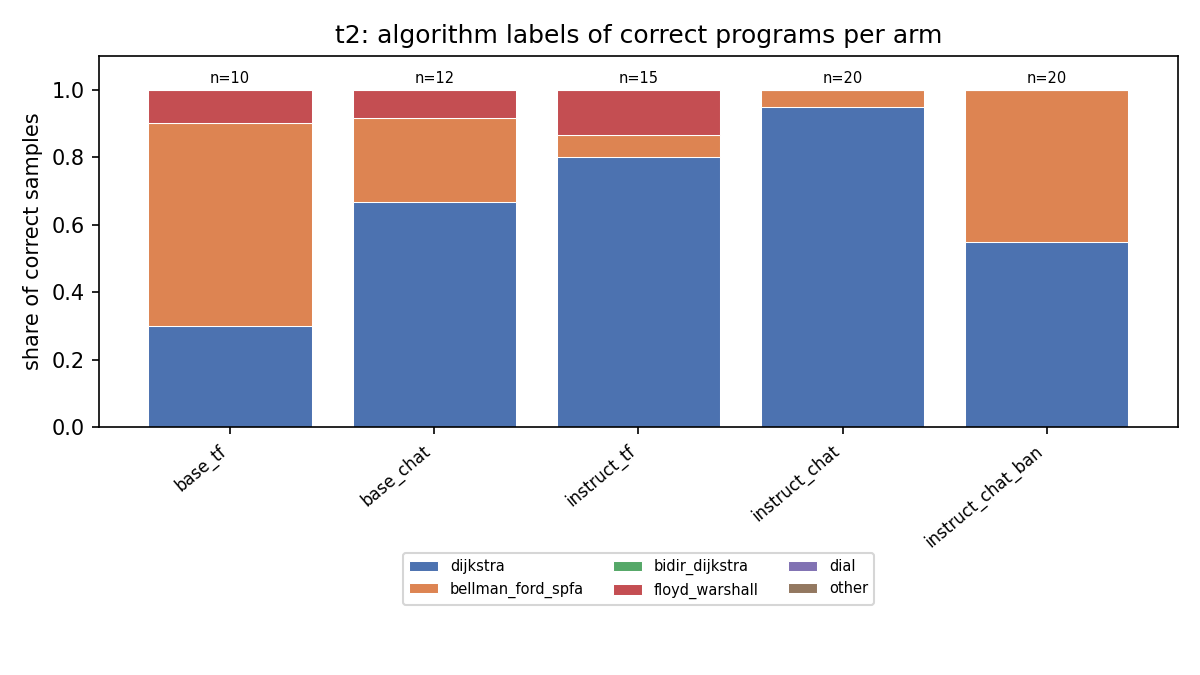

In [28]:
# the committed forecast, byte-identical, with its hash log and commit record (read by predict_rows / assemble)
(PRED / "predict_modal_ban.json").write_text(support["forecast_file_text"])
(PRED / "hash_log.txt").write_text(support["hash_log_text"])
(PRED / "git_commit.txt").write_text(support["git_commit_text"])
warnings.filterwarnings("ignore", message="No artists with labels")  # figures(): its steering panels stay empty here (GPU arms)
t0 = time.time()
main()  # = .venv/bin/python src/analysis.py   (analysis.py's main, defined in the cell above)
%matplotlib inline
print(f"analysis took {time.time() - t0:.0f} s")
res = json.loads((RESULTS / "analysis.json").read_text())
display(Image(str(FIGS / "labels_t2.png"), width=650))  # the artifact's own label figure, drawn from the demo rows

## 13 · The hash-committed forecast and the prompting baseline

Before the instruct model was sampled under *"Do not use Dijkstra"*, `src/predict_commit.py` wrote down where it would land, predicted from the **base** model's template-free distribution over the surviving algorithms. The prediction went to `predictions/predict_modal_ban.json`, its sha256 was logged and it was committed to git (2026-10-19 17:15:56 UTC).

`predict_rows()` re-hashes the file and finds the realised mode among the compliant correct programs (a label must lead by ≥ 15 pp). It then scores every predictor by top-1 hit and mean log score; the uniform predictor is the no-skill reference. The BUY row prices the ban prompt as a diversity knob: Hill gain against pass-rate loss.

In [29]:
ref = support["full_run_reference"]
full_pred = {r["predictor"]: r for r in ref["PREDICT"]}
print(f"{'predictor':22s} {'primary':7s} {'top-1':18s} {'hit':5s} {'log score':>9s} {'JS':>6s} | full run: {'hit':5s} {'log score':>9s}")
for r in res["rows"]["PREDICT"]:
    f = full_pred.get(r["predictor"], {})
    ls = f"{r['log_score']:.3f}" if r["log_score"] is not None else "n/a"
    jsd = f"{r['js_to_realised']:.3f}" if r["js_to_realised"] is not None else "n/a"
    print(f"{r['predictor']:22s} {str(r['primary']):7s} {r['top1']:18s} {str(r['top1_hit']):5s} {ls:>9s} {jsd:>6s} | "
          f"{str(f.get('top1_hit')):9s} {f.get('log_score', float('nan')):9.3f}")
if res["rows"]["PREDICT"]:
    r0 = res["rows"]["PREDICT"][0]
    print(f"\nhash re-check: committed {r0['sha256_committed'][:12]}... now {r0['sha256_now'][:12]}... match={r0['hash_match']}; "
          f"compliant correct programs {r0['n_compliant']}/{r0['n_samples']}, realised counts {r0['realised_counts']} "
          f"-> mode {r0['realised_mode']}   (full run: {ref['PREDICT'][0]['realised_counts']})")
for r in res["rows"]["BUY"]:
    f = next((x for x in ref["BUY"] if x["knob"] == r["knob"]), {})
    print(f"\nBUY {r['knob']}: Hill_cc {r['hill_cc']:.2f} (delta {r['delta_hill_cc']:+.2f}) at {r['pass_loss_pp']:.0f} pp pass loss "
          f"| full run: Hill_cc {f.get('hill_cc', float('nan')):.2f} (delta {f.get('delta_hill_cc', float('nan')):+.2f}) "
          f"at {f.get('pass_loss_pp', float('nan')):.0f} pp")
qa = res["labeller_qa"]
print(f"\nlabeller QA: Cohen's kappa runtime vs AST over the demo programs = {qa['kappa_runtime_vs_ast_overall'] or float('nan'):.2f} "
      f"(full run {ref['labeller_qa']['kappa_runtime_vs_ast_overall']:.2f}; inter-judge kappa {ref['labeller_qa']['second_judge_kappa']:.2f})")

predictor              primary top-1              hit   log score     JS | full run: hit   log score
base_chat_correct      False   bellman_ford_spfa  True     -0.058  0.020 | True         -0.058
base_tf_all            True    bellman_ford_spfa  True     -0.220  0.074 | True         -0.220
base_tf_correct        False   bellman_ford_spfa  True     -0.144  0.049 | True         -0.144
instruct_chat_correct  False   bellman_ford_spfa  True     -0.058  0.020 | True         -0.058
uniform                False   bellman_ford_spfa  True     -1.406  0.384 | True         -1.406

hash re-check: committed 94854c800110... now 94854c800110... match=True; compliant correct programs 9/20, realised counts {'bellman_ford_spfa': 9, 'bidir_dijkstra': 0, 'floyd_warshall': 0, 'dial': 0, 'other': 0} -> mode bellman_ford_spfa   (full run: {'bellman_ford_spfa': 46, 'bidir_dijkstra': 0, 'floyd_warshall': 0, 'dial': 0, 'other': 0})

BUY prompt:ban:Dijkstra: Hill_cc 1.99 (delta +0.77) at 0 pp pass loss | full ru

## 14 · Inside the models: the read-position "sharpening direction" (`src/acts_hf.py`)

`acts_hf.py` hooks every decoder layer of each model. For 50 chat prompts that are token-identical for both models, it records the residual stream at **R**, the last prompt token, which is the state the first answer token is read from. The paired difference δ_L = mean_p (h_instruct − h_base) is the candidate *sharpening direction*.

The steering runs (`src/steer_hf.py`, GPU) subtracted c·δ over layers 8–28 to try to undo the collapse. That destroyed the output format (0/100 parseable at c = 0.5, 1 and 1.5), while norm-matched random directions did not.

The data file carries the stored fp16 states of both models for the 50 T2 prompts at decoder layers 8, 18 and 28 (the band start, the single-layer steering site and the band end). The cell below runs the artifact's `diagnostics()` on them, and the Results section plots the actual activation geometry. The model-loading and hooking code is included for reference; it needs a GPU and is not called.

In [30]:
"""Sharpening direction (STEP 5). One process per model, base first.

  .venv/bin/python src/acts_hf.py --model base       -> activations/base_{task}_R.npy, base_{task}_gen.npy
  .venv/bin/python src/acts_hf.py --model instruct   -> activations/instruct_{task}_R.npy, instruct_{task}_gen.npy,
                                                        steer_{task}.npy (band-incremental vectors, layers 8..28),
                                                        results/sharpening_direction.json (diagnostics + logit lens)
Residual states are read with forward hooks on model.model.layers[L] (the same site the steering hook writes to);
index 0 = embedding output, index L+1 = output of decoder layer L.
"""
import argparse
import gc
import json
import sys
import time
from pathlib import Path

import numpy as np
from loguru import logger

# notebook: the common (§1) and prompts (§3) names are already defined
# sys.path.insert(0, str(Path(__file__).resolve().parent))
# from common import ACTS, MB, MI, N_LAYERS, RESULTS, RUNS, read_jsonl, setup_logging, time_log  # noqa: E402
# from prompts import load_prompts  # noqa: E402

BAND = list(range(8, 29))  # 0-indexed decoder layers 8..28 (21 layers)


def load_model(model_id: str):
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer
    tok = AutoTokenizer.from_pretrained(model_id)
    model = AutoModelForCausalLM.from_pretrained(model_id, dtype=torch.bfloat16, device_map="cuda",
                                                 attn_implementation="sdpa")
    model.eval()
    return tok, model


class Recorder:
    """Records the residual stream after the embedding and after every decoder layer for one forward pass."""

    def __init__(self, model):
        self.model = model
        self.handles = []
        self.store: dict[int, "torch.Tensor"] = {}
        emb = model.model.embed_tokens
        self.handles.append(emb.register_forward_hook(self._mk(0)))
        for L, layer in enumerate(model.model.layers):
            self.handles.append(layer.register_forward_hook(self._mk(L + 1)))

    def _mk(self, idx: int):
        def hook(mod, inp, out):
            hs = out[0] if isinstance(out, tuple) else out
            self.store[idx] = hs.detach()
        return hook

    def remove(self) -> None:
        for h in self.handles:
            h.remove()


def chat_ids(prompts: dict, task: str) -> list[list[int]]:
    return [p["token_ids"] for p in prompts["chat"][task]["baseline"]]  # P0..P49


def run_R(model, ids_list: list[list[int]], rec: Recorder) -> np.ndarray:
    import torch
    out = np.zeros((len(ids_list), N_LAYERS + 1, model.config.hidden_size), dtype=np.float32)
    with torch.inference_mode():
        for i, ids in enumerate(ids_list):
            rec.store.clear()
            model(input_ids=torch.tensor([ids], device="cuda"), use_cache=False, logits_to_keep=1)
            for l in range(N_LAYERS + 1):
                out[i, l] = rec.store[l][0, -1].float().cpu().numpy()
    return out


def gen_items(prompts: dict, task: str, tok) -> list[tuple[list[int], int]]:
    """20 B1 completions (samples 0-1 of each paraphrase P0..P9): prompt ids + first 64 completion tokens."""
    rows = [r for r in read_jsonl(RUNS / "raw_instruct_chat__baseline.jsonl") if r["task"] == task]
    pid = {p["id"]: p["token_ids"] for p in prompts["chat"][task]["baseline"]}
    items = []
    for k in range(10):
        sel = sorted([r for r in rows if r["prompt_id"] == f"P{k}"], key=lambda r: r["sample_id"])[:2]
        for r in sel:
            comp = tok(r["text"], add_special_tokens=False)["input_ids"][:64]
            items.append((pid[r["prompt_id"]] + comp, len(comp)))
    return items


def run_gen(model, items: list[tuple[list[int], int]], rec: Recorder) -> np.ndarray:
    import torch
    out = np.zeros((len(items), N_LAYERS + 1, model.config.hidden_size), dtype=np.float32)
    with torch.inference_mode():
        for i, (ids, n_c) in enumerate(items):
            rec.store.clear()
            model(input_ids=torch.tensor([ids], device="cuda"), use_cache=False, logits_to_keep=1)
            for l in range(N_LAYERS + 1):
                out[i, l] = rec.store[l][0, -n_c:].float().mean(0).cpu().numpy()
    return out


def cos(a: np.ndarray, b: np.ndarray) -> float:
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12))


def diagnostics(hI: np.ndarray, hB: np.ndarray, gI: np.ndarray | None, gB: np.ndarray | None) -> dict:
    """hI, hB: [50, 37, D] at R (paired, identical tokens)."""
    diff = hI - hB
    delta = diff.mean(0)  # [37, D]
    d1 = diff[:25].mean(0)
    d2 = diff[25:].mean(0)
    per_layer = []
    dgen = (gI - gB).mean(0) if gI is not None and gB is not None else None
    for l in range(hI.shape[1]):
        mI, mB = hI[:, l].mean(0), hB[:, l].mean(0)
        dl = delta[l]
        e = dl ** 2
        top10 = float(np.sort(e)[-10:].sum() / (e.sum() + 1e-12))
        per_layer.append({
            "index": l, "decoder_layer": l - 1,
            "cos_meanI_meanB": cos(mI, mB),
            "mean_per_prompt_cos": float(np.mean([cos(hI[p, l], hB[p, l]) for p in range(hI.shape[0])])),
            "rel_norm_delta": float(np.linalg.norm(dl) / (np.linalg.norm(mB) + 1e-12)),
            "norm_delta": float(np.linalg.norm(dl)),
            "split_half_cos": cos(d1[l], d2[l]),
            "top10_energy_share": top10,
            "cos_delta_R_delta_gen": (cos(dl, dgen[l]) if dgen is not None else None),
        })
    return {"delta": delta, "per_layer": per_layer}


def band_vectors(delta: np.ndarray) -> np.ndarray:
    """v_8 = delta_8, v_L = delta_L - delta_{L-1}; delta indexed by decoder layer -> hidden index L+1."""
    vs = []
    for L in BAND:
        cur = delta[L + 1]
        prev = delta[L] if L > BAND[0] else np.zeros_like(cur)
        vs.append(cur - prev)
    return np.stack(vs).astype(np.float32)  # [21, D]


def logit_lens(model, tok, hI_mean_L: np.ndarray, delta_L: np.ndarray, k: int = 20) -> dict:
    import torch
    with torch.inference_mode():
        norm = model.model.norm
        W = model.lm_head
        x0 = torch.tensor(hI_mean_L, device="cuda", dtype=torch.bfloat16)[None, None]
        x1 = torch.tensor(hI_mean_L - delta_L, device="cuda", dtype=torch.bfloat16)[None, None]
        l0 = W(norm(x0)).float()[0, 0]
        l1 = W(norm(x1)).float()[0, 0]
        d = (l1 - l0).cpu().numpy()
    top = np.argsort(-d)[:k]
    bot = np.argsort(d)[:k]
    return {"promoted_by_minus_delta": [(tok.decode([int(i)]), float(d[i])) for i in top],
            "suppressed_by_minus_delta": [(tok.decode([int(i)]), float(d[i])) for i in bot]}


@logger.catch(reraise=True)
def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--model", required=True, choices=["base", "instruct"])
    ap.add_argument("--skip_gen", action="store_true")
    args = ap.parse_args()
    setup_logging(f"acts_{args.model}")
    import torch
    torch.cuda.set_per_process_memory_fraction(0.95)
    mid = MB if args.model == "base" else MI
    time_log(f"acts_{args.model}_start")
    t0 = time.time()
    prompts = load_prompts()
    tok, model = load_model(mid)
    logger.info(f"loaded {mid} in {time.time() - t0:.0f}s; layers={len(model.model.layers)}")
    rec = Recorder(model)
    # sanity: recorder index 36 must equal the pre-norm residual (differs from HF's normed last hidden state)
    for task in ("t1", "t2"):
        hR = run_R(model, chat_ids(prompts, task), rec)
        np.save(ACTS / f"{args.model}_{task}_R.npy", hR.astype(np.float16))
        logger.info(f"{task}: saved R activations {hR.shape}")
        if not args.skip_gen:
            items = gen_items(prompts, task, tok)
            if items:
                hg = run_gen(model, items, rec)
                np.save(ACTS / f"{args.model}_{task}_gen.npy", hg.astype(np.float16))
                logger.info(f"{task}: saved teacher-forced gen activations {hg.shape}")
    rec.remove()
    if args.model == "instruct":
        out = {"model_pair": [MB, MI], "band_layers": BAND, "tasks": {}}
        deltas = {}
        for task in ("t1", "t2"):
            hI = np.load(ACTS / f"instruct_{task}_R.npy").astype(np.float32)
            hB = np.load(ACTS / f"base_{task}_R.npy").astype(np.float32)
            gIp, gBp = ACTS / f"instruct_{task}_gen.npy", ACTS / f"base_{task}_gen.npy"
            gI = np.load(gIp).astype(np.float32) if gIp.exists() else None
            gB = np.load(gBp).astype(np.float32) if gBp.exists() else None
            dg = diagnostics(hI, hB, gI, gB)
            deltas[task] = dg["delta"]
            np.save(ACTS / f"delta_{task}.npy", dg["delta"].astype(np.float32))
            v = band_vectors(dg["delta"])
            np.save(ACTS / f"steer_{task}.npy", v)
            # cumulative check: sum of increments equals delta at each band layer
            cum = np.cumsum(v, axis=0)
            err = float(max(np.abs(cum[i] - dg["delta"][L + 1]).max() for i, L in enumerate(BAND)))
            ll = logit_lens(model, tok, hI[:, 29].mean(0), dg["delta"][29])
            out["tasks"][task] = {"per_layer": dg["per_layer"], "cumsum_max_abs_err": err, "logit_lens_L28": ll,
                                  "band_increment_norms": [float(np.linalg.norm(x)) for x in v]}
            logger.info(f"{task}: band vectors saved; cum err {err:.2e}; "
                        f"L18 split-half cos {dg['per_layer'][19]['split_half_cos']:.3f}, rel norm "
                        f"{dg['per_layer'][19]['rel_norm_delta']:.3f}")
        out["task_generality_cos"] = [{"index": l, "cos_delta_t1_t2": cos(deltas["t1"][l], deltas["t2"][l])}
                                      for l in range(N_LAYERS + 1)]
        # pooled direction (fallback 5)
        hI_all = np.concatenate([np.load(ACTS / f"instruct_{t}_R.npy").astype(np.float32) for t in ("t1", "t2")])
        hB_all = np.concatenate([np.load(ACTS / f"base_{t}_R.npy").astype(np.float32) for t in ("t1", "t2")])
        pooled = (hI_all - hB_all).mean(0)
        np.save(ACTS / "delta_pooled.npy", pooled.astype(np.float32))
        np.save(ACTS / "steer_pooled.npy", band_vectors(pooled))
        (RESULTS / "sharpening_direction.json").write_text(json.dumps(out, indent=1))
    # special-token embedding norms (STEP 2.5) for this model
    emb = model.model.embed_tokens.weight.detach().float()
    norms = emb.norm(dim=1)
    med = float(norms.median())
    st = {}
    for s in ["<|im_start|>", "<|im_end|>", "<think>", "</think>"]:
        i = tok.convert_tokens_to_ids(s)
        st[s] = {"id": int(i), "norm": float(norms[i]), "ratio_to_median": float(norms[i] / med),
                 "flag_untrained": bool(norms[i] < 0.2 * med)}
    (RESULTS / f"special_token_norms_{args.model}.json").write_text(json.dumps({"median_norm": med, "tokens": st}, indent=1))
    logger.info(f"special-token norms ({args.model}): {st}")
    del model
    gc.collect()
    time_log(f"acts_{args.model}_end", seconds=round(time.time() - t0, 1))


# notebook: the script's CLI entry point is not run inside the notebook (needs a GPU and both 8B models)
# if __name__ == "__main__":
#     main()

In [31]:
acts = support["activations_R"]
LAYERS = acts["decoder_layers"]
def _decode(a):  # base64 little-endian fp16 -> float32, as acts_hf.py's main() loads its .npy files
    return np.frombuffer(base64.b64decode(a["b64"]), dtype="<f2").reshape(a["shape"]).astype(np.float32)
hB, hI = _decode(acts["base"]), _decode(acts["instruct"])  # [50 prompts, 3 layers, 4096]
dg = diagnostics(hI, hB, None, None)                         # no teacher-forced states in the demo data
for x, L in zip(dg["per_layer"], LAYERS):                    # the slice holds decoder layers 8/18/28, not 0..2
    x["decoder_layer"], x["index"] = L, L + 1
full_pl = {x["decoder_layer"]: x for x in ref["sharpening_direction"]["per_layer"]}
print(f"states: base {hB.shape}, instruct {hI.shape} (prompts x layers x d_model)")
print(f"{'layer':>5s} {'cos(mean h_I, mean h_B)':>24s} {'||delta||/||h_B||':>18s} {'split-half cos(delta)':>22s} {'top-10 energy':>14s}   full run (same four)")
for x in dg["per_layer"]:
    f = full_pl[x["decoder_layer"]]
    print(f"{x['decoder_layer']:5d} {x['cos_meanI_meanB']:24.3f} {x['rel_norm_delta']:18.3f} {x['split_half_cos']:22.4f} {x['top10_energy_share']:14.3f}"
          f"   {f['cos_meanI_meanB']:.3f} / {f['rel_norm_delta']:.3f} / {f['split_half_cos']:.4f} / {f['top10_energy_share']:.3f}")
ll = ref["sharpening_direction"]["logit_lens_L28"]
print("\nfull-run logit lens at layer 28, tokens -delta promotes:", [t for t, _ in ll["promoted_by_minus_delta"][:10]])
print("                                 tokens -delta suppresses:", [t for t, _ in ll["suppressed_by_minus_delta"][:10]])

states: base (50, 3, 4096), instruct (50, 3, 4096) (prompts x layers x d_model)
layer  cos(mean h_I, mean h_B)  ||delta||/||h_B||  split-half cos(delta)  top-10 energy   full run (same four)
    8                    0.621              0.851                 0.9989          0.046   0.621 / 0.851 / 0.9989 / 0.046
   18                    0.467              1.099                 0.9990          0.111   0.467 / 1.099 / 0.9990 / 0.111
   28                    0.441              1.023                 0.9987          0.101   0.441 / 1.023 / 0.9987 / 0.101

full-run logit lens at layer 28, tokens -delta promotes: ['指令', 'Conversation', ' Claude', 'Prompt', '擦', 'CHAT', ' prompt', 'chat', 'pulse', 'conversation']
                                 tokens -delta suppresses: ['```', ' ```', '``', 'éré', ' Liga', ' here', ' <%=', '<Block', '大奖', '[^']


## 15 · Assemble `method_out.json` (the rest of `method.py`)

`assemble()` turns every labelled row into two things: the shared row schema (`runs/samples.jsonl`), and one `exp_gen_sol_out` example per sample (the prompt as input, the raw text as output, the final label and pass flag as predictions, every other field as `metadata_*`). It bundles all analyses as metadata. It runs unchanged here; its `load_prompts` import is replaced by the §3 cell, and missing GPU-phase files simply come back as `None`. `main()` is the CLI wrapper and is not called.

In [32]:
def clean(x):
    """Strict JSON: NaN/inf -> None, tuples -> lists, recursively."""
    import math as _m
    if isinstance(x, float):
        return None if (_m.isnan(x) or _m.isinf(x)) else x
    if isinstance(x, dict):
        return {str(k): clean(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [clean(v) for v in x]
    return x


def gpu_cost() -> dict:
    """GPU time from time_log.json: sum of per-phase reported seconds and the wall-clock span of GPU phases."""
    import datetime as _dt
    tl = jload(WS / "time_log.json", []) or []
    secs = sum(float(e.get("seconds", 0) or 0) for e in tl if str(e.get("event", "")).endswith("_end"))
    ts = [_dt.datetime.strptime(e["utc"], "%Y-%m-%dT%H:%M:%SZ") for e in tl
          if any(str(e.get("event", "")).startswith(p) for p in ("gen_", "acts_", "steer_"))]
    span = (max(ts) - min(ts)).total_seconds() if ts else 0.0
    return {"gpu_hours_phase_sum": round(secs / 3600, 2), "gpu_wall_span_hours": round(span / 3600, 2),
            "gpu": "1x NVIDIA L4 23 GB"}


def jload(p: Path, default=None):
    try:
        return json.loads(p.read_text())
    except (OSError, json.JSONDecodeError):
        return default


def all_labelled() -> list[dict]:
    rows = []
    for f in sorted(RUNS.glob("labelled_*.jsonl")):
        rows.extend(read_jsonl(f))
    return rows


def shared_schema(r: dict) -> dict:
    return {"task": r["task"], "condition": r["condition"], "paraphrase_id": r["paraphrase_id"], "sample_id": r["sample_id"],
            "model": r["model"], "decoding": r.get("decoding", DECODING), "label": r.get("label"),
            "labeller_source": r.get("labeller_source"), "passed": bool(r.get("passed")), "wall_s": r.get("wall_s"),
            "code_sha256": r.get("code_sha256"), "code": r.get("code"),
            "arm": r["arm"], "template": r["template"], "steer": r.get("steer"), "prompt_id": r["prompt_id"],
            "seed": r.get("seed"), "engine": r.get("engine"), "stage": r.get("stage"), "finish_reason": r.get("finish_reason"),
            "n_tokens": r.get("n_tokens"), "parse_ok": r.get("parse_ok"), "format_ok_loose": r.get("format_ok_loose"),
            "format_ok_strict": r.get("format_ok_strict"), "refusal": r.get("refusal"), "degenerate": r.get("degenerate"),
            "chat_leak": r.get("chat_leak"), "runtime_label": r.get("runtime_label"), "ast_label": r.get("ast_label"),
            "judge_label": r.get("judge_label"), "fail_case": r.get("fail_case"), "error": r.get("error")}


def example_of(r: dict, prompt_text: str) -> dict:
    ex = {"input": prompt_text, "output": r.get("text", ""),
          "predict_algorithm_label": r.get("label") or "unparseable",
          "predict_passes_hidden_tests": "true" if r.get("passed") else "false"}
    for k, v in shared_schema(r).items():
        if k in ("code",):
            ex["metadata_program"] = v
            continue
        ex[f"metadata_{k}"] = v
    return ex


def assemble() -> None:
    # from prompts import load_prompts  -> notebook: defined in §3
    prompts = load_prompts()
    rows = all_labelled()
    write_jsonl(RUNS / "samples.jsonl", [shared_schema(r) for r in rows])
    ptext = {}
    for tmpl in ("chat", "tf"):
        for task in ("t1", "t2"):
            for kind in ("baseline", "ban"):
                for p in prompts[tmpl][task][kind]:
                    ptext[(tmpl, task, kind, p["id"])] = p["text"]
    datasets = []
    for task in ("t1", "t2"):
        ex = []
        for r in rows:
            if r["task"] != task:
                continue
            kind = "baseline" if r["condition"] == "baseline" else "ban"
            ex.append(example_of(r, ptext[(r["template"], task, kind, r["prompt_id"])]))
        datasets.append({"dataset": TASK_NAMES[task], "examples": ex})
    an = jload(RESULTS / "analysis.json", {})
    sd = jload(RESULTS / "sharpening_direction.json", {})
    if sd:
        for t in sd.get("tasks", {}).values():
            t.pop("band_increment_norms", None)
    gen_meta = {ph: jload(RESULTS / f"gen_meta_{ph}.json") for ph in ("A", "B", "C", "A_EXT")}
    pred_file = PRED / "predict_modal_ban.json"
    meta = {
        "method_name": "post-training collapse screen: 2x2 weights-by-format decomposition + sharpening-direction steering + "
                       "hash-committed base-model forecast",
        "description": ("Qwen3-8B-Base vs Qwen3-8B (thinking off) on two path-search tasks (T1 unweighted grid path, T2 weighted "
                        "shortest path). Arms: base template-free, base chat-templated, instruct chat, instruct template-free "
                        "(2x2), modal-ban arms, and HF steering arms that subtract the paired instruct-minus-base residual "
                        "difference (band-incremental over layers 8-28, plus fallbacks). Every program is scored on >=44 hidden "
                        "tests and labelled by a runtime-signature + AST labeller with a blind LLM judge for disagreements."),
        "models": {"base": MB, "instruct": MI}, "decoding": DECODING,
        "library_versions": lib_versions(), "hardware": hardware(), "gen_engine_meta": gen_meta,
        "deviations": jload(RESULTS / "deviations.json", []),
        "time_log": jload(WS / "time_log.json", []),
        "tasks": {t: {"name": TASK_NAMES[t], "catalogue": CATALOGUE[t],
                      "n_hidden_tests": len(jload(WS / "data" / "tests" / f"{t}.json", {}).get("cases", []))} for t in ("t1", "t2")},
        "prompts_sha256": jload(WS / "data" / "prompts.json", {}).get("sha256_all"),
        "prompt_checks": jload(WS / "data" / "prompts.json", {}).get("checks"),
        "special_token_norms": {m: jload(RESULTS / f"special_token_norms_{m}.json") for m in ("base", "instruct")},
        "harness_calibration": jload(RESULTS / "harness_calibration.json"),
        "labeller_qa": an.get("labeller_qa"),
        "arms": an.get("arms"),
        "collapse_screen": an.get("collapse_screen"),
        "sharpening_direction": sd,
        "hook_tests": jload(RESULTS / "hook_tests.json"),
        "steering": an.get("steering"),
        "manipulation_gap_closed": an.get("manipulation"),
        "base_ban_obedience": an.get("base_ban_obedience"),
        "rows": an.get("rows"),
        "predict_commit": {"file": "predictions/predict_modal_ban.json",
                           "sha256_now": sha256_file(pred_file) if pred_file.exists() else None,
                           "hash_log": (PRED / "hash_log.txt").read_text().splitlines() if (PRED / "hash_log.txt").exists() else [],
                           "git_commit": (PRED / "git_commit.txt").read_text().strip() if (PRED / "git_commit.txt").exists() else None,
                           "guard_test": jload(RESULTS / "predict_guard_test.json")},
        "priors": an.get("priors"),
        "analysis_sanity_checks": an.get("sanity"),
        "costs": {"judge": jload(RESULTS / "judge_cost.json"), "gpu": gpu_cost()},
        "figures": an.get("figures"),
        "kept_artifacts": {"activations/": "per-model residual states at R and teacher-forced generated positions, deltas, "
                                           "band steering vectors (kept on the run volume; each file < 100 MB)",
                           "runs/": "raw generations, labelled per-sample rows, caches",
                           "predictions/": "hash-committed forecast + hash log + commit record"},
    }
    out = clean({"metadata": meta, "datasets": datasets})
    (WS / "method_out.json").write_text(json.dumps(out, indent=1, default=str, allow_nan=False))
    logger.info(f"method_out.json written: {sum(len(d['examples']) for d in datasets)} examples")


@logger.catch(reraise=True)
def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--all", action="store_true")
    ap.add_argument("--assemble", action="store_true")
    ap.add_argument("--step", choices=sorted(STEPS))
    a = ap.parse_args()
    setup_logging("method")
    os.chdir(WS)
    if a.all:
        for s in ORDER:
            run_step(s)
        assemble()
    elif a.step:
        run_step(a.step)
    if a.assemble:
        assemble()


# notebook: the script's CLI entry point is not run inside the notebook
# if __name__ == "__main__":
#     main()

In [33]:
(WS / "time_log.json").write_text(json.dumps(support["time_log"], indent=1))  # phase timings, read by gpu_cost()
assemble()  # = .venv/bin/python method.py --assemble
out = json.loads((WS / "method_out.json").read_text())
rebuilt = {(x["metadata_arm"], x["metadata_condition"], x["metadata_paraphrase_id"], x["metadata_sample_id"]): x
           for d in out["datasets"] for x in d["examples"]}
same = Counter()
for k, s in stored.items():
    x = rebuilt[k]
    same["label"] += x["predict_algorithm_label"] == s["predict_algorithm_label"]
    same["passes"] += x["predict_passes_hidden_tests"] == s["predict_passes_hidden_tests"]
    same["program"] += x["metadata_program"] == s["metadata_program"]
print({d["dataset"]: len(d["examples"]) for d in out["datasets"]}, "| metadata keys:", len(out["metadata"]))
print(f"rebuilt examples identical to the full run's: " + ", ".join(f"{k} {v}/{len(stored)}" for k, v in same.items()))
print("GPU cost recorded by the artifact:", out["metadata"]["costs"]["gpu"])

05:46:14|INFO   |method_out.json written: 100 examples


{'T1_unweighted_grid_path': 0, 'T2_weighted_shortest_path': 100} | metadata keys: 29
rebuilt examples identical to the full run's: label 100/100, passes 100/100, program 100/100
GPU cost recorded by the artifact: {'gpu_hours_phase_sum': 2.1, 'gpu_wall_span_hours': 2.79, 'gpu': '1x NVIDIA L4 23 GB'}


## Results

The cells below put each demo value from the re-run above next to the full-run value from the artifact. Then come two figures:

* the behavioural picture: the algorithm mix, Hill_cc with paraphrase-cluster CIs, the weights and format contrasts, and the ban substitution against the committed forecast;
* the activation geometry at the read position.

In [34]:
ARMS = ["base_tf", "base_chat", "instruct_tf", "instruct_chat", "instruct_chat_ban"]
SHORT = {"dijkstra": "Dij", "bellman_ford_spfa": "BF", "floyd_warshall": "FW", "bidir_dijkstra": "biDij", "dial": "Dial", "other": "other"}

def ci(d):
    if not d or d.get("est") is None or (isinstance(d["est"], float) and math.isnan(d["est"])):
        return "n/a"
    return f"{d['est']:.2f} [{d['lo']:.2f}, {d['hi']:.2f}]" if d.get("lo") is not None else f"{d['est']:.2f} [CI n/a]"

def lab_str(c):
    return ", ".join(f"{SHORT.get(k, k)} {v}" for k, v in sorted((c or {}).items(), key=lambda kv: -kv[1])) or "-"

print("Per arm (T2). demo = this re-run on the curated subset | full = the artifact's full run")
print(f"{'arm':18s} {'N':>3s} {'pass':>5s} {'correct programs':24s} {'Hill_cc [95% CI]':19s} | {'N':>3s} {'pass':>5s} {'correct programs':30s} {'Hill_cc [95% CI]'}")
for a in ARMS:
    s, f = res["arms"].get(f"{a}|t2", {}), ref["arms"][f"{a}|t2"]
    print(f"{a:18s} {s.get('N', 0):3d} {s.get('pass_rate', [float('nan')])[0]:5.2f} {lab_str(s.get('label_counts_correct')):24s} "
          f"{ci(s.get('hill_cc_ci')):19s} | {f['N']:3d} {f['pass_rate'][0]:5.2f} {lab_str(f['label_counts_correct']):30s} {ci(f['hill_cc_ci'])}")
cs, cf = res["collapse_screen"]["t2"], ref["collapse_screen"]
v, vf = cs["verdict_cc"], cf["verdict_cc"]
print(f"\nCollapse screen (T2, Hill_cc)                        demo                 | full run")
print(f"D_weights = Hill(instruct_chat) - Hill(base_chat)  : {ci(cs['D_weights_cc']):20s} | {ci(cf['D_weights_cc'])}")
print(f"D_format  = Hill(base_chat) - Hill(base_tf)        : {ci(cs['D_format_cc']):20s} | {ci(cf['D_format_cc'])}")
print(f"D_format (instruct) = Hill(instruct_chat) - Hill(instruct_tf): {ci(cs.get('D_format_instruct_cc')):9s} | {ci(cf.get('D_format_instruct_cc'))}")
print(f"modal-share gap for the instruct mode ({v['instruct_modal']}), bar 15 pp: {v['modal_share_gap_pp_weights']:.1f} pp | {vf['modal_share_gap_pp_weights']:.1f} pp")
p_d = cs["permutation_chi2"].get("instruct_chat_vs_base_chat_cc", {}).get("p")
print(f"permutation chi2 p (instruct_chat vs base_chat labels): {p_d} | {cf['permutation_chi2']['instruct_chat_vs_base_chat_cc']['p']}")
print(f"VERDICT (Hill_cc): demo {v['verdict']} | full {vf['verdict']}   [Hill_all: demo {cs['verdict_all']['verdict']} | full {cf['verdict_all']['verdict']}]")
print(f"full run, T1 verdict: {ref['verdict_t1_cc']}; alternate 'post-training installed the collapse' passes the screen: {ref['alternate_passes_screen_cc']}")
st = ref["steering"]
print(f"\nSteering (full run only, GPU; HF S0 = hooked c=0 control: pass {st['S0']['pass_rate'][0]:.2f}, Hill_cc {st['S0']['hill_cc']:.2f}) -> knob verdict {st['knob_verdict']}")
for k, x in st["arms"].items():
    h = x["hill_cc"]
    print(f"   {k:38s} parse {x['parse_rate']:.2f}  pass {x['pass_rate'][0]:.2f}  Hill_cc {'n/a' if h is None else f'{h:.2f}'}")
print(f"\nLabelling re-run agreement with the stored full-run fields over {agree_all['n']} samples: "
      + ", ".join(f"{k} {agree_all[k]}" for k in ("program", "passed", "runtime", "ast", "judge", "final")))

Per arm (T2). demo = this re-run on the curated subset | full = the artifact's full run
arm                  N  pass correct programs         Hill_cc [95% CI]    |   N  pass correct programs               Hill_cc [95% CI]
base_tf             20  0.50 BF 6, Dij 3, FW 1        2.45 [1.00, 2.95]   | 300  0.08 BF 16, Dij 8, FW 1             2.18 [1.00, 2.73]
base_chat           20  0.60 Dij 8, BF 3, FW 1        2.28 [1.00, 2.82]   | 300  0.30 Dij 63, BF 24, other 2, FW 1   2.09 [1.63, 2.54]
instruct_tf         20  0.75 Dij 12, FW 2, BF 1       1.87 [1.00, 2.60]   | 100  0.72 Dij 57, FW 8, BF 7             1.93 [1.41, 2.37]
instruct_chat       20  1.00 Dij 19, BF 1             1.22 [1.00, 1.65]   | 200  1.00 Dij 193, BF 7                  1.16 [1.03, 1.31]
instruct_chat_ban   20  1.00 Dij 11, BF 9             1.99 [1.67, 2.00]   | 100  1.00 Dij 54, BF 46                  1.99 [1.65, 2.00]

Collapse screen (T2, Hill_cc)                        demo                 | full run
D_weights = Hill(

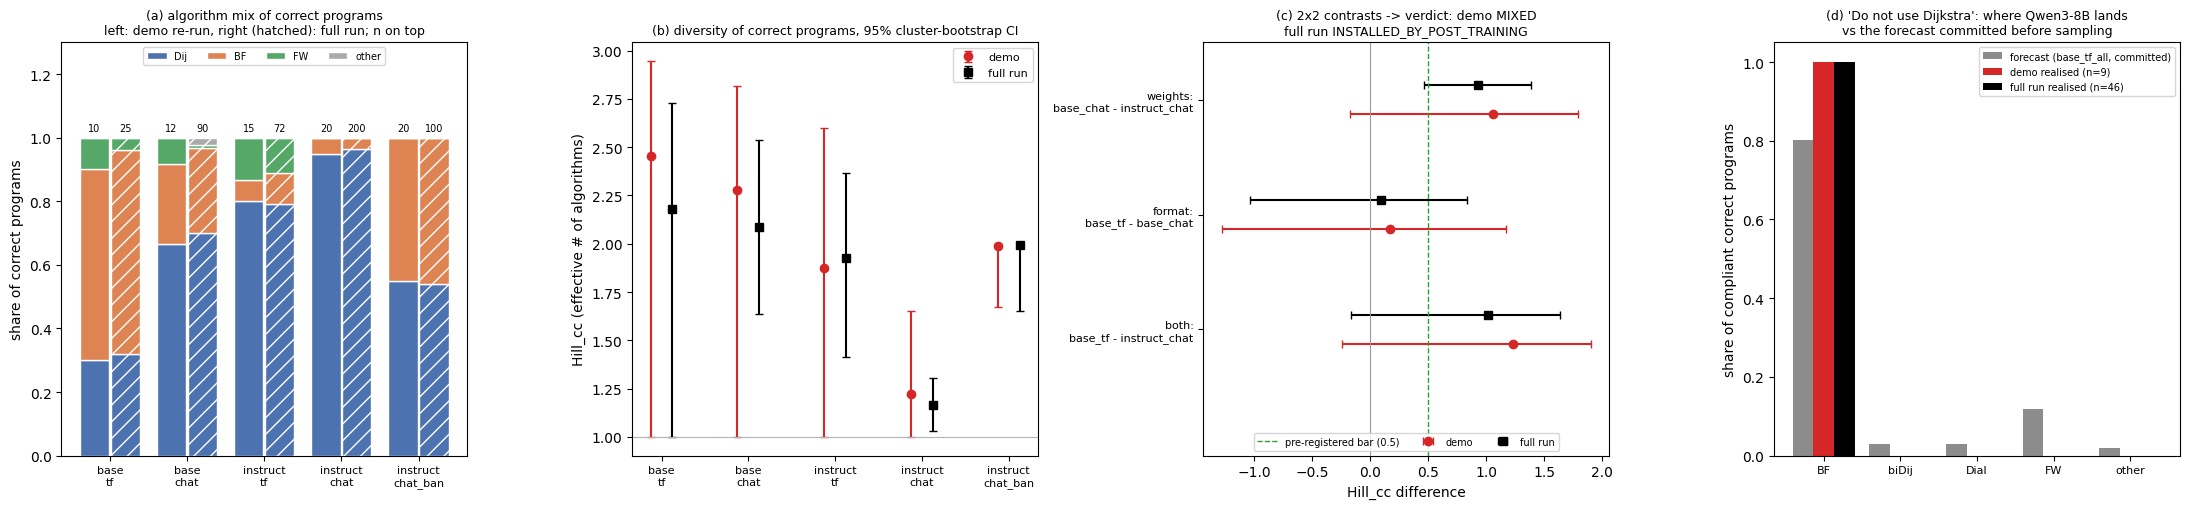

In [35]:
%matplotlib inline
LABS = ["dijkstra", "bellman_ford_spfa", "floyd_warshall", "other"]
COL = {"dijkstra": "#4C72B0", "bellman_ford_spfa": "#DD8452", "floyd_warshall": "#55A868", "other": "#AAAAAA"}
fig, axes = plt.subplots(1, 4, figsize=(22, 5.2))

# (a) algorithm shares among correct programs: demo (solid) vs full run (hatched)
ax = axes[0]
for i, a in enumerate(ARMS):
    for j, (c, hatch) in enumerate(((res["arms"].get(f"{a}|t2", {}).get("label_counts_correct", {}), None),
                                    (ref["arms"][f"{a}|t2"]["label_counts_correct"], "//"))):
        tot, bottom, x = sum(c.values()), 0.0, i + (j - 0.5) * 0.4
        for lab in LABS:
            h = (c.get(lab, 0) + (sum(v for k, v in c.items() if k not in LABS) if lab == "other" else 0)) / tot if tot else 0
            ax.bar(x, h, 0.38, bottom=bottom, color=COL[lab], hatch=hatch, edgecolor="white",
                   label=(SHORT[lab] if (i == 0 and j == 0) else None))
            bottom += h
        ax.text(x, 1.02, f"{tot}", ha="center", fontsize=7)
ax.set_xticks(range(len(ARMS)))
ax.set_xticklabels([a.replace("_", "\n", 1) for a in ARMS], fontsize=8)
ax.set_ylim(0, 1.3)
ax.set_ylabel("share of correct programs")
ax.set_title("(a) algorithm mix of correct programs\nleft: demo re-run, right (hatched): full run; n on top", fontsize=9)
ax.legend(fontsize=7, loc="upper center", ncol=4)

# (b) Hill_cc with paraphrase-cluster bootstrap CIs
ax = axes[1]
for j, (src_, mk, name) in enumerate(((res["arms"], "o", "demo"), (ref["arms"], "s", "full run"))):
    for i, a in enumerate(ARMS):
        d = src_.get(f"{a}|t2", {}).get("hill_cc_ci", {})
        if d.get("est") is None:
            continue
        lo, hi = (d["lo"], d["hi"]) if d.get("lo") is not None else (d["est"], d["est"])
        ax.errorbar(i + (j - 0.5) * 0.25, d["est"], yerr=[[d["est"] - lo], [hi - d["est"]]], fmt=mk, capsize=3,
                    color=("k" if j else "tab:red"), label=name if i == 0 else None)
ax.axhline(1, color="0.7", lw=0.8)
ax.set_xticks(range(len(ARMS)))
ax.set_xticklabels([a.replace("_", "\n", 1) for a in ARMS], fontsize=8)
ax.set_ylabel("Hill_cc (effective # of algorithms)")
ax.set_title("(b) diversity of correct programs, 95% cluster-bootstrap CI", fontsize=9)
ax.legend(fontsize=8)

# (c) the three verdict contrasts (positive = the second arm is more collapsed)
ax = axes[2]
names = [("hill_base_chat_minus_instruct_chat", "weights:\nbase_chat - instruct_chat"),
         ("hill_base_tf_minus_base_chat", "format:\nbase_tf - base_chat"),
         ("hill_base_tf_minus_instruct_chat", "both:\nbase_tf - instruct_chat")]
for j, (vd, mk, name) in enumerate(((v, "o", "demo"), (vf, "s", "full run"))):
    for i, (k, _) in enumerate(names):
        d = vd[k]
        if d.get("est") is None or (isinstance(d["est"], float) and math.isnan(d["est"])):
            continue
        lo, hi = (d["lo"], d["hi"]) if d.get("lo") is not None else (d["est"], d["est"])
        ax.errorbar(d["est"], len(names) - 1 - i + (j - 0.5) * 0.25, xerr=[[d["est"] - lo], [hi - d["est"]]], fmt=mk, capsize=3,
                    color=("k" if j else "tab:red"), label=name if i == 0 else None)
ax.axvline(0, color="0.6", lw=0.8)
ax.axvline(0.5, color="tab:green", ls="--", lw=1, label="pre-registered bar (0.5)")
ax.set_yticks([len(names) - 1 - i for i in range(len(names))])
ax.set_yticklabels([n for _, n in names], fontsize=8)
ax.set_ylim(-1.1, len(names) - 0.5)
ax.set_xlabel("Hill_cc difference")
ax.set_title(f"(c) 2x2 contrasts -> verdict: demo {v['verdict']}\nfull run {vf['verdict']}", fontsize=9)
ax.legend(fontsize=7, loc="lower center", ncol=3)

# (d) ban substitution vs the committed forecast (base model's template-free distribution over the survivors)
ax = axes[3]
fc = json.loads(support["forecast_file_text"])["events"]["t2"]
p = fc["predictors"][fc["primary"]]["p"]
S = list(p)
rd_ = res["rows"]["PREDICT"][0]["realised_counts"] if res["rows"]["PREDICT"] else {}
rf_ = ref["PREDICT"][0]["realised_counts"]
w = 0.27
for j, (vals, name, colr) in enumerate(((p, f"forecast ({fc['primary']}, committed)", "0.55"),
                                        ({k: rd_.get(k, 0) / max(1, sum(rd_.values())) for k in S}, f"demo realised (n={sum(rd_.values())})", "tab:red"),
                                        ({k: rf_.get(k, 0) / max(1, sum(rf_.values())) for k in S}, f"full run realised (n={sum(rf_.values())})", "k"))):
    ax.bar(np.arange(len(S)) + (j - 1) * w, [vals[k] for k in S], w, label=name, color=colr)
ax.set_xticks(range(len(S)))
ax.set_xticklabels([SHORT.get(k, k) for k in S], fontsize=8)
ax.set_ylabel("share of compliant correct programs")
ax.set_title("(d) 'Do not use Dijkstra': where Qwen3-8B lands\nvs the forecast committed before sampling", fontsize=9)
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

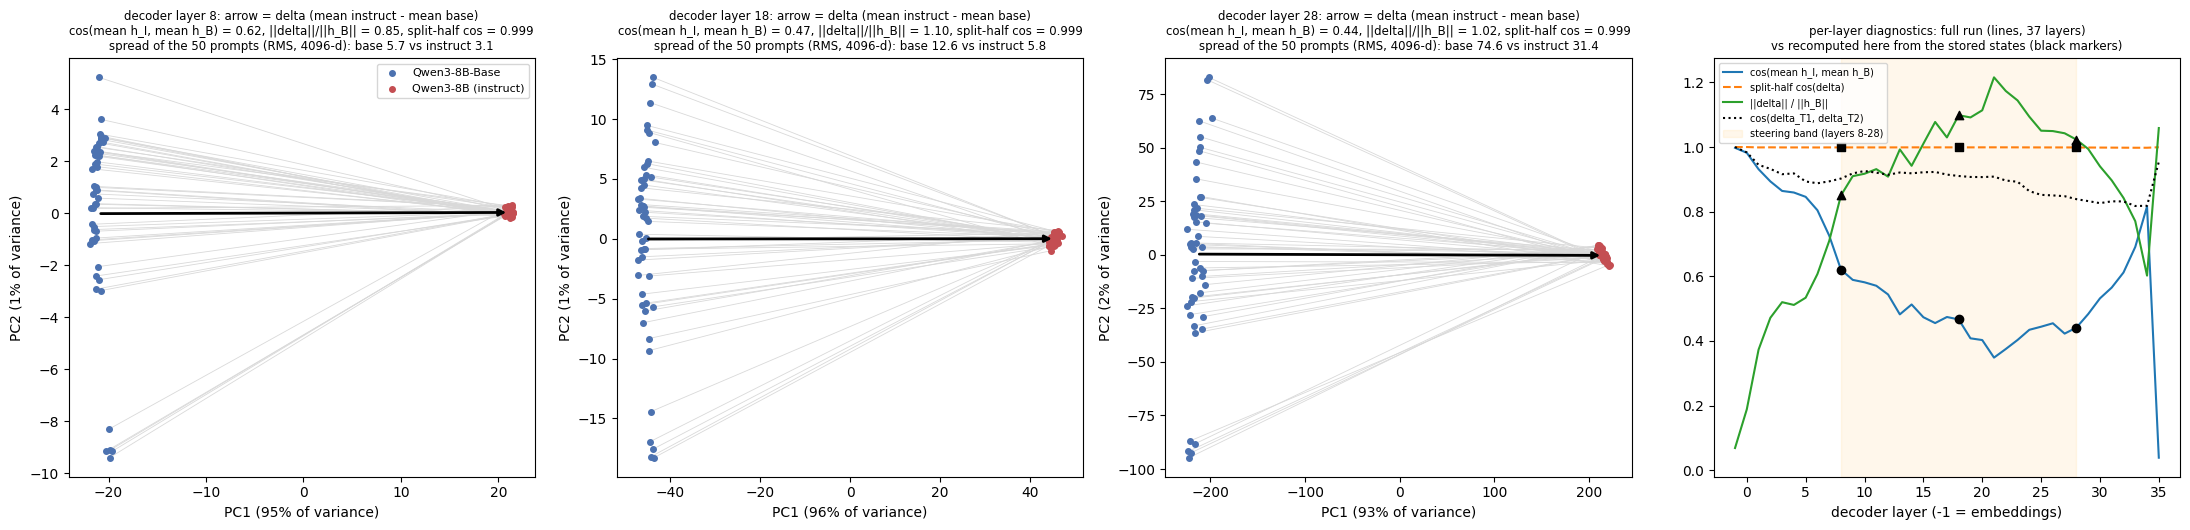

How tightly each model bunches the 50 paraphrased prompts at R (RMS distance to its own centroid, full 4096-d space):
  decoder layer  8: base    5.7   instruct    3.1   -> instruct states are 1.8x more concentrated
  decoder layer 18: base   12.6   instruct    5.8   -> instruct states are 2.2x more concentrated
  decoder layer 28: base   74.6   instruct   31.4   -> instruct states are 2.4x more concentrated


In [36]:
# Activation geometry at the read position R: the stored residual states of both models (50 T2 chat prompts)
fig, axes = plt.subplots(1, 4, figsize=(22, 5.4))
spread = []  # notebook-only descriptive measure: RMS distance of each model's 50 prompt states to their own centroid (4096-d)
for li, (ax, L) in enumerate(zip(axes[:3], LAYERS)):
    X = np.concatenate([hB[:, li], hI[:, li]])  # [100, 4096]
    Xc = X - X.mean(0)
    _, Sv, Vt = np.linalg.svd(Xc, full_matrices=False)
    P = Xc @ Vt[:2].T
    pb, pi = P[:50], P[50:]
    for k in range(50):  # the same prompt in both models
        ax.plot([pb[k, 0], pi[k, 0]], [pb[k, 1], pi[k, 1]], color="0.85", lw=0.6, zorder=1)
    ax.scatter(*pb.T, s=16, color="#4C72B0", label="Qwen3-8B-Base", zorder=2)
    ax.scatter(*pi.T, s=16, color="#C44E52", label="Qwen3-8B (instruct)", zorder=2)
    ax.annotate("", xy=pi.mean(0), xytext=pb.mean(0), arrowprops=dict(arrowstyle="-|>", lw=2, color="k"), zorder=3)
    ev = Sv ** 2 / (Sv ** 2).sum()
    x = dg["per_layer"][li]
    sB, sI = (float(np.sqrt(((H[:, li] - H[:, li].mean(0)) ** 2).sum(1).mean())) for H in (hB, hI))
    spread.append((L, sB, sI))
    ax.set_title(f"decoder layer {L}: arrow = delta (mean instruct - mean base)\ncos(mean h_I, mean h_B) = {x['cos_meanI_meanB']:.2f}, "
                 f"||delta||/||h_B|| = {x['rel_norm_delta']:.2f}, split-half cos = {x['split_half_cos']:.3f}\n"
                 f"spread of the 50 prompts (RMS, 4096-d): base {sB:.1f} vs instruct {sI:.1f}", fontsize=8.5)
    ax.set_xlabel(f"PC1 ({100 * ev[0]:.0f}% of variance)")
    ax.set_ylabel(f"PC2 ({100 * ev[1]:.0f}% of variance)")
axes[0].legend(fontsize=8, loc="best")
ax = axes[3]
pl, tg = ref["sharpening_direction"]["per_layer"], ref["sharpening_direction"]["task_generality_cos"]
Ls = [x["decoder_layer"] for x in pl]
ax.plot(Ls, [x["cos_meanI_meanB"] for x in pl], label="cos(mean h_I, mean h_B)")
ax.plot(Ls, [x["split_half_cos"] for x in pl], ls="--", label="split-half cos(delta)")
ax.plot(Ls, [x["rel_norm_delta"] for x in pl], label="||delta|| / ||h_B||")
ax.plot([x["index"] - 1 for x in tg], [x["cos_delta_t1_t2"] for x in tg], color="k", ls=":", label="cos(delta_T1, delta_T2)")
for key, mk in (("cos_meanI_meanB", "o"), ("split_half_cos", "s"), ("rel_norm_delta", "^")):
    ax.scatter(LAYERS, [x[key] for x in dg["per_layer"]], marker=mk, color="k", zorder=3)
ax.axvspan(8, 28, color="orange", alpha=0.08, label="steering band (layers 8-28)")
ax.set_xlabel("decoder layer (-1 = embeddings)")
ax.set_title("per-layer diagnostics: full run (lines, 37 layers)\nvs recomputed here from the stored states (black markers)", fontsize=8.5)
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()
print("How tightly each model bunches the 50 paraphrased prompts at R (RMS distance to its own centroid, full 4096-d space):")
for L, sB, sI in spread:
    print(f"  decoder layer {L:2d}: base {sB:6.1f}   instruct {sI:6.1f}   -> instruct states are {sB / sI:.1f}x more concentrated")

**Reading the results.**

* **The labelling reproduces exactly.** Re-running extraction, the sandboxed hidden tests, both labellers and the cached judge with the artifact's code reproduces every stored field for all 100 samples, and `assemble()` rebuilds identical examples.
* **Behaviour.** `instruct_chat` is almost all Dijkstra (19/20 here, 193/200 in the full run). The base model on the *same chat tokens* mixes Dijkstra with Bellman-Ford and Floyd–Warshall. The demo's point estimates track the full run: D_weights −1.06 vs −0.93, modal-share gap 28 vs 26.5 pp.
* **Why the demo says MIXED.** With only 12 correct `base_chat` programs, the cluster-bootstrap CI still crosses 0, so the pre-registered rule returns **MIXED**. The artifact found the same at its planned sample size. Only after extending the base arms to N = 300 (90 correct `base_chat` programs) did the CI exclude 0, giving **INSTALLED_BY_POST_TRAINING** for T2.
* **What post-training did.** It sharpened the base model's existing mode instead of inventing a new one. Format matters too: template-free base code favours Bellman-Ford, and the chat template moves the base model to Dijkstra.
* **Bans substitute.** Under *"Do not use Dijkstra"*, every compliant program lands on Bellman-Ford (9/9 here, 46/46 in the full run). Bellman-Ford is the base model's runner-up and the top-1 of the committed forecast, whose hash is unchanged. The ban removes the mode and the model substitutes the next one. That is why the ban prompt raised Hill_cc (1.16 → 1.99 in the full run) at no pass-rate cost, while no steering setting did.
* **Geometry.** At the read position the two checkpoints form two separated clouds along one direction (PC1 holds 93–96 % of the variance). Every prompt moves by almost the same vector (split-half cos 0.999), the shift is about as large as the base state itself, and it is largely shared with T1 (cos 0.85–0.92 in the band). It is a generic "chat model about to answer" direction, and its logit lens suppresses ```` ``` ```` and "Here". That is why subtracting it broke the answer format instead of restoring the base mix.
* **A notebook-only view.** The instruct model's 50 prompt states are about 2× more concentrated than the base model's (ratios printed above). The instruct model reads differently worded prompts more alike before it writes a single token. This is descriptive only and not part of the artifact's analysis.

The demo subset is 100 of the 2,070 T2 samples, stratified per arm, so its exact numbers differ from the full run. The full-run values are the reported ones.